In [ ]:

# CELL 1: ENVIRONMENT SETUP

import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("AMHARIC SEMANTIC RELATION EXTRACTION")
print("DEEP LEARNING MODEL: BiLSTM")
print("=" * 75)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Random seed:", SEED)
print("Target relation classes: 10")
print("Model: BiLSTM")


AMHARIC SEMANTIC RELATION EXTRACTION
DEEP LEARNING MODEL: BiLSTM
PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Random seed: 42
Target relation classes: 10
Model: BiLSTM


In [ ]:

# CELL 2: LOAD DATASET

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("=" * 70)
print("DATASET LOADING AND INITIAL INSPECTION")
print("=" * 70)

print("File:", file_name)
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five records:")
display(df.head())

print("\nRelation distribution:")
display(
    df["relation"].value_counts()
    .rename_axis("Relation")
    .reset_index(name="Count")
)

print("\nTotal records:", len(df))
print("Number of relation classes:", df["relation"].nunique())


Saving amharic relation extraction.csv to amharic relation extraction.csv
DATASET LOADING AND INITIAL INSPECTION
File: amharic relation extraction.csv
Dataset shape: (6580, 3)

Column names:
['id', 'sentence', 'relation']

Missing values:
id          0
sentence    0
relation    0
dtype: int64

First five records:


,id,sentence,relation
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,"Content-Container(e2,e1)"
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,"Product-Producer(e2,e1)"
2,3,<e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ...,"Member-Collection(e1,e2)"
3,4,<e1>ሰዎች</e1> ወደ <e2>መሃል ከተማ</e2> በመሄድ ላይ ናቸው፡፡፡,"Entity-Destination(e1,e2)"
4,5,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,"Message-Topic(e2,e1)"



Relation distribution:


,Relation,Count
0,Other,1031
1,"Entity-Destination(e1,e2)",874
2,"Cause-Effect(e1,e2)",495
3,"Message-Topic(e1,e2)",493
4,"Component-Whole(e2,e1)",436
5,"Content-Container(e1,e2)",413
6,"Entity-Origin(e1,e2)",393
7,"Product-Producer(e2,e1)",356
8,"Instrument-Agency(e2,e1)",338
9,"Message-Topic(e2,e1)",302



Total records: 6580
Number of relation classes: 19


In [ ]:

# CELL 3: DATA CLEANING AND RELATION NORMALIZATION

# Keep the required columns
df = df[["sentence", "relation"]].copy()

# Remove records with missing values
df = df.dropna(subset=["sentence", "relation"]).copy()

# Convert values to strings and remove surrounding spaces
df["sentence"] = df["sentence"].astype(str).str.strip()
df["relation"] = df["relation"].astype(str).str.strip()

# Remove empty sentences or relation labels
df = df[
    (df["sentence"] != "") &
    (df["relation"] != "")
].copy()

# Merge directional labels into their parent relations
df["relation"] = df["relation"].str.replace(
    r"\(e[12],e[12]\)",
    "",
    regex=True
).str.strip()

# Reset dataframe index
df = df.reset_index(drop=True)

print("=" * 75)
print("DATA CLEANING AND RELATION NORMALIZATION")
print("=" * 75)

print("Total records:", len(df))
print("Number of relation classes:", df["relation"].nunique())

print("\nFinal relation classes and distribution:")

display(
    df["relation"].value_counts()
    .rename_axis("Relation")
    .reset_index(name="Count")
)

print("\nRelation class names:")
for i, relation in enumerate(sorted(df["relation"].unique()), 1):
    print(f"{i}. {relation}")

# Verify exactly 10 classes
assert df["relation"].nunique() == 10, (
    f"Expected 10 classes, found {df['relation'].nunique()}"
)

print("\nSUCCESS: All directional labels merged into 10 classes.")
print("No directional records were intentionally removed.")


DATA CLEANING AND RELATION NORMALIZATION
Total records: 6580
Number of relation classes: 10

Final relation classes and distribution:


,Relation,Count
0,Other,1031
1,Entity-Destination,940
2,Message-Topic,795
3,Cause-Effect,790
4,Component-Whole,600
5,Entity-Origin,561
6,Product-Producer,547
7,Content-Container,494
8,Instrument-Agency,413
9,Member-Collection,409



Relation class names:
1. Cause-Effect
2. Component-Whole
3. Content-Container
4. Entity-Destination
5. Entity-Origin
6. Instrument-Agency
7. Member-Collection
8. Message-Topic
9. Other
10. Product-Producer

SUCCESS: All directional labels merged into 10 classes.
No directional records were intentionally removed.


In [ ]:

# CELL 4: ENTITY MARKER VALIDATION

required_markers = ["<e1>", "</e1>", "<e2>", "</e2>"]

for marker in required_markers:
    df[marker] = df["sentence"].apply(
        lambda text: text.count(marker)
    )

df["valid_markers"] = df[required_markers].eq(1).all(axis=1)

valid_count = df["valid_markers"].sum()
invalid_count = len(df) - valid_count

print("=" * 75)
print("ENTITY MARKER VALIDATION")
print("=" * 75)

print("Total records:", len(df))
print("Valid records:", valid_count)
print("Invalid records:", invalid_count)

print("\nMarker validation summary:")
display(
    df[required_markers + ["valid_markers"]]
    .value_counts()
    .reset_index(name="Count")
)

if invalid_count > 0:
    print("\nExamples of invalid records:")
    display(
        df.loc[
            ~df["valid_markers"],
            ["sentence", "relation"] + required_markers
        ].head(10)
    )
else:
    print("\nAll records have valid entity markers.")

print("\nCELL 4 completed.")


ENTITY MARKER VALIDATION
Total records: 6580
Valid records: 6492
Invalid records: 88

Marker validation summary:


,<e1>,</e1>,<e2>,</e2>,valid_markers,Count
0,1,1,1,1,True,6492
1,2,2,2,2,False,27
2,1,0,1,1,False,25
3,0,1,1,1,False,17
4,1,1,2,2,False,11
5,1,1,0,1,False,8



Examples of invalid records:


,sentence,relation,<e1>,</e1>,<e2>,</e2>
9,የደራሲው መጽሐፎቹ እና <e1>መጣጥፎች</e1> ዘመናዊውን <e2>ታሪክ</...,Cause-Effect,2,2,2,2
231,<e1>የኦዲቱ</e1> ዋና ዓላማ <e2>በሒሳብ መግለጫው</e2> ላይ ሪፖ...,Content-Container,2,2,2,2
238,<e1>መምህሩ</e1> ስለ ሙሉ ቁጥሮች ከ 50000 በታች የሚሆን <e2>...,Other,2,2,2,2
385,የዚህ <e1>ክፍል</e1> ዉይይት ስለ e2>ስረአተ ብድር</e2>< ብ...,Message-Topic,1,1,0,1
418,የሸክላ አፈር ያላቸዉ አገሮች ትንሽ ናቸዉ ነገርግን <e1>የጸደይ</e1 ...,Other,1,0,1,1
461,ፖሊሶች ደብድበውት፣ ውሀ አፍ እና አፍንጫው ላይ ጨምረውበት እንዲሁም <e...,Entity-Destination,1,0,1,1
470,ይህ <e1>ታሪክ/e1>በተጋቢ ጥንዶች መካከል ያለውን የቅናት <e2>ሀይል...,Message-Topic,1,0,1,1
477,ሚ/ር ላጋኖ በቼሪስቶን እና ኩዋሆግ <e1>ክላምስ</e1> ፍለጋ ብዙ ጊዜ...,Entity-Destination,1,1,2,2
483,በኋላ ላይ በነጮች e1>ቃል ኪዳን</e1>እና <e2>ጠንቋዮች</e2>እንዲ...,Member-Collection,0,1,1,1
805,የሃበሻ e1>የማር</e1> <e2>ጠጅ</e2> አዘገጃጀት መመሪያዎችን በማ...,Entity-Origin,0,1,1,1



CELL 4 completed.


In [ ]:

# CELL 5: ENTITY EXTRACTION

import re

def extract_entity(sentence, entity_number):
    pattern = rf"<e{entity_number}>(.*?)</e{entity_number}>"
    match = re.search(pattern, sentence, flags=re.DOTALL)

    if match:
        return match.group(1).strip()

    return ""

df["entity_1"] = df["sentence"].apply(
    lambda text: extract_entity(text, 1)
)

df["entity_2"] = df["sentence"].apply(
    lambda text: extract_entity(text, 2)
)

print("=" * 75)
print("ENTITY EXTRACTION RESULTS")
print("=" * 75)

print("Total records:", len(df))
print("Entity 1 extracted:", (df["entity_1"] != "").sum())
print("Entity 2 extracted:", (df["entity_2"] != "").sum())

print("\nRecords with missing extracted entities:")
print(
    ((df["entity_1"] == "") | (df["entity_2"] == "")).sum()
)

print("\nSample extracted entities:")
display(
    df[["sentence", "entity_1", "entity_2", "relation"]].head(10)
)

# Remove temporary marker-audit columns
df = df.drop(
    columns=required_markers + ["valid_markers"],
    errors="ignore"
)

print("\nFinal dataset shape:", df.shape)
print("Relation classes:", df["relation"].nunique())
print("\nCELL 5 completed.")


ENTITY EXTRACTION RESULTS
Total records: 6580
Entity 1 extracted: 6538
Entity 2 extracted: 6572

Records with missing extracted entities:
50

Sample extracted entities:


,sentence,entity_1,entity_2,relation
0,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,በፖርኩ,እንስሳት,Content-Container
1,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,ሶቪየት ሰራሽ,ሚሳይል,Product-Producer
2,<e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ...,የተማሪ,ማህበሩ,Member-Collection
3,<e1>ሰዎች</e1> ወደ <e2>መሃል ከተማ</e2> በመሄድ ላይ ናቸው፡፡፡,ሰዎች,መሃል ከተማ,Entity-Destination
4,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,ምክንያቶች,ሰነድ,Message-Topic
5,<e1>ፍንዳታ</e1> የተከሰተው በውሃ መዶሻ <e2>ግፊት</e2> ምክንያ...,ፍንዳታ,ግፊት,Cause-Effect
6,የንግድ <e1>ኔትወርኮችም</e1> እንኳ ወደ ከፍተኛ ጥራት ወዳለው <e2...,ኔትወርኮችም,አከፋፋይ,Instrument-Agency
7,ስለ <e1>ሂሳቡ</e1> እንዲያስታውሱ እና ደረሰኝ እንዳላቸው ለማረጋገጥ...,ሂሳቡ,ጥሪ,Message-Topic
8,<e1>የፋብሪካው</e1> ምርቶች የአበባ ዱባዎችን ፣ የፊንላንድ ዶሮ-ዊስ...,የፋብሪካው,በሮችን,Product-Producer
9,የደራሲው መጽሐፎቹ እና <e1>መጣጥፎች</e1> ዘመናዊውን <e2>ታሪክ</...,መጣጥፎች,ታሪክ,Cause-Effect



Final dataset shape: (6580, 4)
Relation classes: 10

CELL 5 completed.


In [ ]:

# CELL 6: LABEL ENCODING

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["relation"]
)

NUM_CLASSES = len(label_encoder.classes_)

print("=" * 75)
print("RELATION LABEL ENCODING")
print("=" * 75)

print("Number of relation classes:", NUM_CLASSES)

print("\nClass-to-index mapping:")

for index, relation in enumerate(label_encoder.classes_):
    print(f"{index}: {relation}")

print("\nClass distribution:")

class_distribution = (
    df.groupby(["label", "relation"])
    .size()
    .reset_index(name="Count")
    .sort_values("label")
)

display(class_distribution)

assert NUM_CLASSES == 10, (
    f"Expected 10 classes, but found {NUM_CLASSES}"
)

print("\nSUCCESS: Exactly 10 relation classes encoded.")


RELATION LABEL ENCODING
Number of relation classes: 10

Class-to-index mapping:
0: Cause-Effect
1: Component-Whole
2: Content-Container
3: Entity-Destination
4: Entity-Origin
5: Instrument-Agency
6: Member-Collection
7: Message-Topic
8: Other
9: Product-Producer

Class distribution:


,label,relation,Count
0,0,Cause-Effect,790
1,1,Component-Whole,600
2,2,Content-Container,494
3,3,Entity-Destination,940
4,4,Entity-Origin,561
5,5,Instrument-Agency,413
6,6,Member-Collection,409
7,7,Message-Topic,795
8,8,Other,1031
9,9,Product-Producer,547



SUCCESS: Exactly 10 relation classes encoded.


In [ ]:

# CELL 7: NEAR-DUPLICATE DETECTION AND GROUP CREATION

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Character-level TF-IDF
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=1,
    sublinear_tf=True
)

sentence_vectors = vectorizer.fit_transform(
    df["sentence"].astype(str)
)

# Calculate sparse cosine similarity
similarity_matrix = cosine_similarity(
    sentence_vectors,
    dense_output=False
)

SIMILARITY_THRESHOLD = 0.90

# Union-Find initialization
parent = list(range(len(df)))

def find_root(x):
    if parent[x] != x:
        parent[x] = find_root(parent[x])
    return parent[x]

def union_groups(a, b):
    root_a = find_root(a)
    root_b = find_root(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Join highly similar sentence pairs
similarity_coo = similarity_matrix.tocoo()

similar_pairs = 0

for i, j, similarity in zip(
    similarity_coo.row,
    similarity_coo.col,
    similarity_coo.data
):
    if i < j and similarity >= SIMILARITY_THRESHOLD:
        union_groups(i, j)
        similar_pairs += 1

# Assign group IDs
df["group_id"] = [
    find_root(i) for i in range(len(df))
]

print("=" * 75)
print("NEAR-DUPLICATE GROUPING RESULTS")
print("=" * 75)

print("Total sentences:", len(df))
print("Similarity threshold:", SIMILARITY_THRESHOLD)
print("Highly similar sentence pairs:", similar_pairs)
print("Total independent groups:", df["group_id"].nunique())

group_sizes = df.groupby("group_id").size()

print("Groups containing multiple records:", (group_sizes > 1).sum())
print("Largest group size:", group_sizes.max())

print("\nCELL 7 completed.")


NEAR-DUPLICATE GROUPING RESULTS
Total sentences: 6580
Similarity threshold: 0.9
Highly similar sentence pairs: 15767
Total independent groups: 1343
Groups containing multiple records: 984
Largest group size: 22

CELL 7 completed.


In [ ]:

# CELL 8: DUPLICATE-GROUP LABEL CONSISTENCY AUDIT

group_label_audit = (
    df.groupby("group_id")
    .agg(
        Record_Count=("relation", "size"),
        Unique_Relations=("relation", "nunique"),
        Relations=("relation", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

conflicting_groups = group_label_audit[
    group_label_audit["Unique_Relations"] > 1
].copy()

consistent_groups = group_label_audit[
    group_label_audit["Unique_Relations"] == 1
]

print("=" * 75)
print("DUPLICATE-GROUP LABEL CONSISTENCY AUDIT")
print("=" * 75)

print("Total records:", len(df))
print("Total groups:", len(group_label_audit))
print("Consistent groups:", len(consistent_groups))
print("Groups with conflicting relation labels:", len(conflicting_groups))
print("Records in conflicting groups:",
      conflicting_groups["Record_Count"].sum())

if len(conflicting_groups) > 0:
    print("\nExamples of conflicting groups:")
    display(conflicting_groups.head(20))

    print("\nCorresponding sentences:")
    conflict_ids = conflicting_groups["group_id"].head(10)
    display(
        df[df["group_id"].isin(conflict_ids)][
            ["sentence", "relation", "group_id"]
        ]
    )
else:
    print("\nSUCCESS: All duplicate groups have consistent relation labels.")

print("\nAll records retained:", len(df))


DUPLICATE-GROUP LABEL CONSISTENCY AUDIT
Total records: 6580
Total groups: 1343
Consistent groups: 1343
Groups with conflicting relation labels: 0
Records in conflicting groups: 0

SUCCESS: All duplicate groups have consistent relation labels.

All records retained: 6580


In [ ]:

# CELL 9: RELATION-CLASS GROUP AVAILABILITY AUDIT

class_group_audit = (
    df.groupby("relation")
    .agg(
        Total_Records=("sentence", "count"),
        Independent_Groups=("group_id", "nunique")
    )
    .reset_index()
    .sort_values("relation")
)

print("=" * 80)
print("RELATION-CLASS GROUP AVAILABILITY AUDIT")
print("=" * 80)

display(class_group_audit)

print("\nTotal records:", len(df))
print("Total independent groups:", df["group_id"].nunique())
print("Number of relation classes:", df["relation"].nunique())

print("\nMinimum independent groups per class:",
      class_group_audit["Independent_Groups"].min())

print("\nClasses with fewer than 3 independent groups:")

low_group_classes = class_group_audit[
    class_group_audit["Independent_Groups"] < 3
]

if len(low_group_classes) > 0:
    display(low_group_classes)
else:
    print("None. Every class has at least 3 independent groups.")

assert df["relation"].nunique() == 10, (
    "The dataset must contain exactly 10 relation classes."
)

print("\nCELL 9 audit completed.")


RELATION-CLASS GROUP AVAILABILITY AUDIT


,relation,Total_Records,Independent_Groups
0,Cause-Effect,790,131
1,Component-Whole,600,128
2,Content-Container,494,110
3,Entity-Destination,940,251
4,Entity-Origin,561,121
5,Instrument-Agency,413,78
6,Member-Collection,409,72
7,Message-Topic,795,132
8,Other,1031,223
9,Product-Producer,547,97



Total records: 6580
Total independent groups: 1343
Number of relation classes: 10

Minimum independent groups per class: 72

Classes with fewer than 3 independent groups:
None. Every class has at least 3 independent groups.

CELL 9 audit completed.


In [ ]:

# CELL 10: GROUP-AWARE TRAIN / VALIDATION / TEST SPLITTING

from sklearn.model_selection import GroupShuffleSplit

TARGET_TRAIN = 0.70
TARGET_VAL = 0.15
TARGET_TEST = 0.15

groups = df["group_id"].to_numpy()
labels = df["label"].to_numpy()
indices = np.arange(len(df))

all_classes = set(np.unique(labels))

best_split = None
best_score = float("inf")

# Search for a split with good class balance and target proportions
for seed in range(500):
    first_split = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=seed
    )

    train_idx, temp_idx = next(
        first_split.split(indices, labels, groups)
    )

    second_split = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=seed + 1000
    )

    val_relative, test_relative = next(
        second_split.split(
            temp_idx,
            labels[temp_idx],
            groups[temp_idx]
        )
    )

    val_idx = temp_idx[val_relative]
    test_idx = temp_idx[test_relative]

    # Require all 10 classes in every split
    if (
        set(np.unique(labels[train_idx])) != all_classes
        or set(np.unique(labels[val_idx])) != all_classes
        or set(np.unique(labels[test_idx])) != all_classes
    ):
        continue

    # Evaluate split sizes
    train_ratio = len(train_idx) / len(df)
    val_ratio = len(val_idx) / len(df)
    test_ratio = len(test_idx) / len(df)

    size_error = (
        abs(train_ratio - TARGET_TRAIN)
        + abs(val_ratio - TARGET_VAL)
        + abs(test_ratio - TARGET_TEST)
    )

    # Evaluate class distribution across splits
    total_counts = np.bincount(labels, minlength=NUM_CLASSES)
    train_counts = np.bincount(labels[train_idx], minlength=NUM_CLASSES)
    val_counts = np.bincount(labels[val_idx], minlength=NUM_CLASSES)
    test_counts = np.bincount(labels[test_idx], minlength=NUM_CLASSES)

    distribution_error = 0

    for split_counts, target_ratio in [
        (train_counts, TARGET_TRAIN),
        (val_counts, TARGET_VAL),
        (test_counts, TARGET_TEST)
    ]:
        observed = split_counts / total_counts
        distribution_error += np.mean(
            np.abs(observed - target_ratio)
        )

    score = size_error + distribution_error

    if score < best_score:
        best_score = score
        best_split = (train_idx, val_idx, test_idx)

if best_split is None:
    raise ValueError(
        "No valid split found in 500 attempts. "
        "Share the CELL 9 output so we can adjust the splitting strategy."
    )

train_idx, val_idx, test_idx = best_split

# Create the three datasets
train_df = df.iloc[train_idx].copy().reset_index(drop=True)
val_df = df.iloc[val_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

# Verify group separation
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Verify all 10 classes are present
assert train_df["label"].nunique() == 10
assert val_df["label"].nunique() == 10
assert test_df["label"].nunique() == 10

print("=" * 80)
print("GROUP-AWARE DATA SPLITTING RESULTS")
print("=" * 80)

for name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(split_df):,} records "
        f"({len(split_df) / len(df) * 100:.2f}%) | "
        f"{split_df['group_id'].nunique():,} groups | "
        f"{split_df['label'].nunique()} classes"
    )

print("\nTotal records across splits:",
      len(train_df) + len(val_df) + len(test_df))

print("Original records:", len(df))
print("Groups shared between splits: 0")
print("All 10 classes represented in all splits.")


GROUP-AWARE DATA SPLITTING RESULTS
Training: 4,602 records (69.94%) | 940 groups | 10 classes
Validation: 985 records (14.97%) | 201 groups | 10 classes
Test: 993 records (15.09%) | 202 groups | 10 classes

Total records across splits: 6580
Original records: 6580
Groups shared between splits: 0
All 10 classes represented in all splits.


In [ ]:

# CELL 11: CLASS DISTRIBUTION ACROSS DATA SPLITS

train_counts = train_df["relation"].value_counts()
val_counts = val_df["relation"].value_counts()
test_counts = test_df["relation"].value_counts()
total_counts = df["relation"].value_counts()

split_distribution = pd.DataFrame({
    "Relation": label_encoder.classes_,
    "Train_Count": [
        train_counts.get(c, 0) for c in label_encoder.classes_
    ],
    "Validation_Count": [
        val_counts.get(c, 0) for c in label_encoder.classes_
    ],
    "Test_Count": [
        test_counts.get(c, 0) for c in label_encoder.classes_
    ],
    "Total": [
        total_counts.get(c, 0) for c in label_encoder.classes_
    ]
})

split_distribution["Train_Percent"] = (
    split_distribution["Train_Count"] /
    split_distribution["Total"] * 100
).round(2)

split_distribution["Validation_Percent"] = (
    split_distribution["Validation_Count"] /
    split_distribution["Total"] * 100
).round(2)

split_distribution["Test_Percent"] = (
    split_distribution["Test_Count"] /
    split_distribution["Total"] * 100
).round(2)

print("=" * 90)
print("CLASS DISTRIBUTION ACROSS TRAINING, VALIDATION, AND TEST SETS")
print("=" * 90)

display(split_distribution)

print("\nSplit sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nClass coverage:")
print("Training classes:", train_df["relation"].nunique())
print("Validation classes:", val_df["relation"].nunique())
print("Test classes:", test_df["relation"].nunique())

assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df["relation"].nunique() == 10
assert val_df["relation"].nunique() == 10
assert test_df["relation"].nunique() == 10

print("\nSUCCESS: All records are retained and all 10 classes are represented.")


CLASS DISTRIBUTION ACROSS TRAINING, VALIDATION, AND TEST SETS


,Relation,Train_Count,Validation_Count,Test_Count,Total,Train_Percent,Validation_Percent,Test_Percent
0,Cause-Effect,544,119,127,790,68.86,15.06,16.08
1,Component-Whole,394,77,129,600,65.67,12.83,21.50
2,Content-Container,324,109,61,494,65.59,22.06,12.35
3,Entity-Destination,660,145,135,940,70.21,15.43,14.36
4,Entity-Origin,391,84,86,561,69.70,14.97,15.33
5,Instrument-Agency,287,64,62,413,69.49,15.50,15.01
6,Member-Collection,288,66,55,409,70.42,16.14,13.45
7,Message-Topic,545,128,122,795,68.55,16.10,15.35
8,Other,792,112,127,1031,76.82,10.86,12.32
9,Product-Producer,377,81,89,547,68.92,14.81,16.27



Split sizes:
Training: 4602
Validation: 985
Test: 993
Total: 6580

Class coverage:
Training classes: 10
Validation classes: 10
Test classes: 10

SUCCESS: All records are retained and all 10 classes are represented.


In [ ]:

# CELL 12: BUILD TRAINING VOCABULARY

from collections import Counter

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def tokenize_sentence(sentence):
    return str(sentence).strip().split()

# Build vocabulary from training sentences only
word_counter = Counter()

for sentence in train_df["sentence"]:
    word_counter.update(tokenize_sentence(sentence))

# Reserve indices 0 and 1
vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, frequency in word_counter.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)

print("=" * 75)
print("TRAINING VOCABULARY")
print("=" * 75)

print("Training sentences:", len(train_df))
print("Unique training tokens:", len(word_counter))
print("Vocabulary size:", VOCAB_SIZE)
print("Padding token index:", vocab[PAD_TOKEN])
print("Unknown token index:", vocab[UNK_TOKEN])

print("\nMost frequent 20 tokens:")

display(
    pd.DataFrame(
        word_counter.most_common(20),
        columns=["Token", "Frequency"]
    )
)

print("\nVocabulary built using training data only.")


TRAINING VOCABULARY
Training sentences: 4602
Unique training tokens: 4982
Vocabulary size: 4984
Padding token index: 0
Unknown token index: 1

Most frequent 20 tokens:


,Token,Frequency
0,ውስጥ,1203
1,፡፡,1022
2,እና,781
3,ላይ,707
4,ነው,647
5,ወደ,638
6,ነው።,409
7,፣,362
8,ነበር,336
9,ሪፖርት,320



Vocabulary built using training data only.


SENTENCE LENGTH ANALYSIS
Minimum length: 2
Maximum length: 43
Mean length: 11.81
Median length: 11.0
95th percentile: 21
Selected maximum sequence length: 21

Sentence length percentiles:


,Token_Length
count,4602.000000
mean,11.809648
std,4.883455
min,2.000000
25%,8.000000
50%,11.000000
75%,14.000000
90%,18.000000
95%,21.000000
99%,26.000000


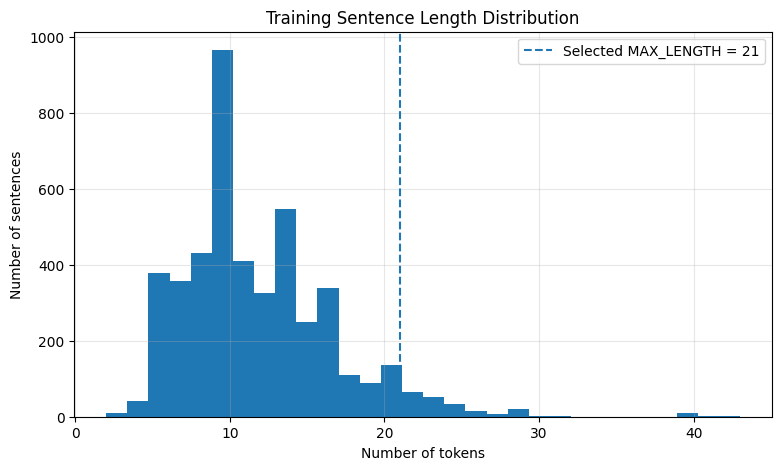


CELL 13 completed.


In [ ]:

# CELL 13: ANALYZE SENTENCE LENGTHS

train_df["token_length"] = train_df["sentence"].apply(
    lambda sentence: len(tokenize_sentence(sentence))
)

length_95 = int(np.percentile(train_df["token_length"], 95))

MAX_LENGTH = max(1, length_95)

print("=" * 75)
print("SENTENCE LENGTH ANALYSIS")
print("=" * 75)

print("Minimum length:", train_df["token_length"].min())
print("Maximum length:", train_df["token_length"].max())
print("Mean length:", round(train_df["token_length"].mean(), 2))
print("Median length:", train_df["token_length"].median())
print("95th percentile:", length_95)
print("Selected maximum sequence length:", MAX_LENGTH)

print("\nSentence length percentiles:")

display(
    train_df["token_length"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Token_Length")
)

plt.figure(figsize=(9, 5))
plt.hist(train_df["token_length"], bins=30)
plt.axvline(
    MAX_LENGTH,
    linestyle="--",
    label=f"Selected MAX_LENGTH = {MAX_LENGTH}"
)
plt.xlabel("Number of tokens")
plt.ylabel("Number of sentences")
plt.title("Training Sentence Length Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nCELL 13 completed.")


In [ ]:

# CELL 14: TEXT-TO-SEQUENCE CONVERSION

def encode_sentence(sentence, vocab, max_length):
    tokens = tokenize_sentence(sentence)

    sequence = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens
    ]

    # Truncate long sequences
    sequence = sequence[:max_length]

    # Pad short sequences
    sequence += [vocab[PAD_TOKEN]] * (
        max_length - len(sequence)
    )

    return sequence


# Encode all three splits using the training vocabulary
X_train = np.array([
    encode_sentence(s, vocab, MAX_LENGTH)
    for s in train_df["sentence"]
], dtype=np.int64)

X_val = np.array([
    encode_sentence(s, vocab, MAX_LENGTH)
    for s in val_df["sentence"]
], dtype=np.int64)

X_test = np.array([
    encode_sentence(s, vocab, MAX_LENGTH)
    for s in test_df["sentence"]
], dtype=np.int64)


# Numerical labels
y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)


print("=" * 75)
print("NUMERICAL SEQUENCE CONVERSION")
print("=" * 75)

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)
print("Test input shape:", X_test.shape)

print("\nTraining label shape:", y_train.shape)
print("Validation label shape:", y_val.shape)
print("Test label shape:", y_test.shape)

print("\nVocabulary size:", VOCAB_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Number of classes:", NUM_CLASSES)

print("\nExample encoded sentence:")
print("Original:", train_df["sentence"].iloc[0])
print("Encoded:", X_train[0].tolist())
print("Label:", y_train[0])
print("Relation:", train_df["relation"].iloc[0])

# Data integrity checks
assert X_train.shape == (len(train_df), MAX_LENGTH)
assert X_val.shape == (len(val_df), MAX_LENGTH)
assert X_test.shape == (len(test_df), MAX_LENGTH)

assert len(y_train) == len(train_df)
assert len(y_val) == len(val_df)
assert len(y_test) == len(test_df)

print("\nSUCCESS: All splits converted into numerical sequences.")


NUMERICAL SEQUENCE CONVERSION
Training input shape: (4602, 21)
Validation input shape: (985, 21)
Test input shape: (993, 21)

Training label shape: (4602,)
Validation label shape: (985,)
Test label shape: (993,)

Vocabulary size: 4984
Maximum sequence length: 21
Number of classes: 10

Example encoded sentence:
Original: <e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ በቡፋሎ ውስጥ ያለ የቅድመ ምረቃ ተማሪ ድምጽ ነው፡
Encoded: [3069, 3070, 3071, 363, 3072, 793, 3073, 2, 181, 3074, 3075, 424, 2077, 4703, 0, 0, 0, 0, 0, 0, 0]
Label: 6
Relation: Member-Collection

SUCCESS: All splits converted into numerical sequences.


In [ ]:

# CELL 15: PYTORCH DATASETS AND DATALOADERS

from torch.utils.data import Dataset, DataLoader

class RelationDataset(Dataset):

    def __init__(self, features, labels):
        self.features = torch.tensor(
            features, dtype=torch.long
        )
        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]


# Create datasets
train_dataset = RelationDataset(X_train, y_train)
val_dataset = RelationDataset(X_val, y_val)
test_dataset = RelationDataset(X_test, y_test)

# Data loaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("=" * 75)
print("PYTORCH DATASET AND DATALOADER SUMMARY")
print("=" * 75)

print("Training records:", len(train_dataset))
print("Validation records:", len(val_dataset))
print("Test records:", len(test_dataset))

print("\nBatch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one training batch
sample_inputs, sample_labels = next(iter(train_loader))

print("\nSample batch input shape:", sample_inputs.shape)
print("Sample batch label shape:", sample_labels.shape)
print("Input data type:", sample_inputs.dtype)
print("Label data type:", sample_labels.dtype)

print("\nDevice:", DEVICE)
print("\nCELL 15 completed.")


PYTORCH DATASET AND DATALOADER SUMMARY
Training records: 4602
Validation records: 985
Test records: 993

Batch size: 32
Training batches: 144
Validation batches: 31
Test batches: 32

Sample batch input shape: torch.Size([32, 21])
Sample batch label shape: torch.Size([32])
Input data type: torch.int64
Label data type: torch.int64

Device: cuda

CELL 15 completed.


In [ ]:

# CELL 16: CLASS WEIGHT CALCULATION

from sklearn.utils.class_weight import compute_class_weight

class_ids = np.arange(NUM_CLASSES)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

class_weight_table = pd.DataFrame({
    "Class_ID": class_ids,
    "Relation": label_encoder.classes_,
    "Training_Count": [
        np.sum(y_train == class_id)
        for class_id in class_ids
    ],
    "Class_Weight": class_weights
})

print("=" * 75)
print("CLASS WEIGHTS FOR BILSTM TRAINING")
print("=" * 75)

display(class_weight_table)

print("\nClass weights tensor:")
print(class_weights_tensor)

assert len(class_weights_tensor) == 10
assert torch.isfinite(class_weights_tensor).all()

print("\nSUCCESS: Class weights calculated for all 10 classes.")


CLASS WEIGHTS FOR BILSTM TRAINING


,Class_ID,Relation,Training_Count,Class_Weight
0,0,Cause-Effect,544,0.845956
1,1,Component-Whole,394,1.168020
2,2,Content-Container,324,1.420370
3,3,Entity-Destination,660,0.697273
4,4,Entity-Origin,391,1.176982
5,5,Instrument-Agency,287,1.603484
6,6,Member-Collection,288,1.597917
7,7,Message-Topic,545,0.844404
8,8,Other,792,0.581061
9,9,Product-Producer,377,1.220690



Class weights tensor:
tensor([0.8460, 1.1680, 1.4204, 0.6973, 1.1770, 1.6035, 1.5979, 0.8444, 0.5811,
        1.2207], device='cuda:0')

SUCCESS: Class weights calculated for all 10 classes.


In [ ]:

# CELL 17: DEFINE BILSTM MODEL

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes,
        dropout
    ):
        super(BiLSTMClassifier, self).__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        embedded = self.embedding(x)

        _, (hidden, _) = self.lstm(embedded)

        # Concatenate final forward and backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined = self.dropout(combined)

        output = self.fc(combined)

        return output


# Model hyperparameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.3

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(DEVICE)

print("=" * 75)
print("BILSTM MODEL ARCHITECTURE")
print("=" * 75)

print(model)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Vocabulary size:", VOCAB_SIZE)
print("Number of output classes:", NUM_CLASSES)
print("Device:", DEVICE)

# Verify output dimensions
sample_batch = torch.randint(
    low=0,
    high=VOCAB_SIZE,
    size=(2, MAX_LENGTH)
).to(DEVICE)

model.eval()

with torch.no_grad():
    sample_output = model(sample_batch)

print("\nSample input shape:", sample_batch.shape)
print("Sample output shape:", sample_output.shape)

assert sample_output.shape == (2, NUM_CLASSES)

print("\nSUCCESS: BiLSTM model initialized correctly.")


BILSTM MODEL ARCHITECTURE
BiLSTMClassifier(
  (embedding): Embedding(4984, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=10, bias=True)
)

Total parameters: 904,714
Trainable parameters: 904,714
Vocabulary size: 4984
Number of output classes: 10
Device: cuda

Sample input shape: torch.Size([2, 21])
Sample output shape: torch.Size([2, 10])

SUCCESS: BiLSTM model initialized correctly.


In [ ]:

# CELL 18: LOSS FUNCTION AND OPTIMIZER

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("=" * 75)
print("LOSS FUNCTION AND OPTIMIZER CONFIGURATION")
print("=" * 75)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Class weighting: Enabled")
print("Number of classes:", NUM_CLASSES)

print("\nCELL 18 completed successfully.")


LOSS FUNCTION AND OPTIMIZER CONFIGURATION
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Weight decay: 0.0001
Class weighting: Enabled
Number of classes: 10

CELL 18 completed successfully.


In [ ]:

# CELL 19: EVALUATION METRICS FUNCTION

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "Accuracy": accuracy,
        "Macro_Precision": macro_precision,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "Weighted_Precision": weighted_precision,
        "Weighted_Recall": weighted_recall,
        "Weighted_F1": weighted_f1
    }


# Verify the metric function with a small example
example_true = [0, 1, 2, 0, 1, 2]
example_pred = [0, 1, 1, 0, 2, 2]

example_metrics = calculate_metrics(
    example_true,
    example_pred
)

print("=" * 75)
print("EVALUATION METRICS FUNCTION CHECK")
print("=" * 75)

for metric, value in example_metrics.items():
    print(f"{metric:<25}: {value:.4f}")

print("\nMetric function is ready for model evaluation.")


EVALUATION METRICS FUNCTION CHECK
Accuracy                 : 0.6667
Macro_Precision          : 0.6667
Macro_Recall             : 0.6667
Macro_F1                 : 0.6667
Weighted_Precision       : 0.6667
Weighted_Recall          : 0.6667
Weighted_F1              : 0.6667

Metric function is ready for model evaluation.


In [ ]:

# CELL 20: TRAINING AND VALIDATION FUNCTIONS

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        # Gradient clipping for training stability
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    average_loss = total_loss / len(loader)

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    return average_loss, metrics


def evaluate_model(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    average_loss = total_loss / len(loader)

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    return average_loss, metrics


print("=" * 75)
print("BILSTM TRAINING AND VALIDATION FUNCTIONS")
print("=" * 75)

print("Training function: train_one_epoch")
print("Validation function: evaluate_model")
print("Evaluation metrics: Accuracy, Precision, Recall, Macro-F1, Weighted-F1")
print("Gradient clipping: Enabled (max_norm=1.0)")
print("Validation gradient updates: Disabled")

print("\nCELL 20 completed successfully.")


BILSTM TRAINING AND VALIDATION FUNCTIONS
Training function: train_one_epoch
Validation function: evaluate_model
Evaluation metrics: Accuracy, Precision, Recall, Macro-F1, Weighted-F1
Gradient clipping: Enabled (max_norm=1.0)
Validation gradient updates: Disabled

CELL 20 completed successfully.


In [ ]:

# CELL 21: BILSTM MODEL TRAINING

import copy

EPOCHS = 15
PATIENCE = 5

best_val_f1 = -1.0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_macro_f1": [],
    "val_macro_f1": []
}

best_model_state = None

print("=" * 80)
print("BILSTM MODEL TRAINING")
print("=" * 80)

for epoch in range(EPOCHS):

    train_loss, train_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss, val_metrics = evaluate_model(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(
        train_metrics["Accuracy"]
    )

    history["val_accuracy"].append(
        val_metrics["Accuracy"]
    )

    history["train_macro_f1"].append(
        train_metrics["Macro_F1"]
    )

    history["val_macro_f1"].append(
        val_metrics["Macro_F1"]
    )

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_metrics['Accuracy']:.4f} | "
        f"Train Macro-F1: {train_metrics['Macro_F1']:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_metrics['Accuracy']:.4f} | "
        f"Val Macro-F1: {val_metrics['Macro_F1']:.4f}"
    )

    # Save the best model based on validation Macro-F1
    if val_metrics["Macro_F1"] > best_val_f1:

        best_val_f1 = val_metrics["Macro_F1"]

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_state,
            "best_bilstm_model.pth"
        )

        patience_counter = 0

        print("Best model saved.")

    else:

        patience_counter += 1

        print(
            f"No improvement. "
            f"Patience: {patience_counter}/{PATIENCE}"
        )

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# Restore the best validation model
if best_model_state is None:
    raise RuntimeError("No valid model checkpoint was saved.")

model.load_state_dict(best_model_state)

print("\n" + "=" * 80)
print("TRAINING COMPLETED")
print("=" * 80)

print("Completed epochs:", len(history["train_loss"]))
print("Best validation Macro-F1:", round(best_val_f1, 4))
print("Best model restored successfully.")


BILSTM MODEL TRAINING

Epoch [1/15]
Train Loss: 0.0044 | Train Accuracy: 0.9993 | Train Macro-F1: 0.9994
Val Loss: 3.7527 | Val Accuracy: 0.4508 | Val Macro-F1: 0.4342
Best model saved.

Epoch [2/15]
Train Loss: 0.0032 | Train Accuracy: 0.9991 | Train Macro-F1: 0.9993
Val Loss: 3.6848 | Val Accuracy: 0.4244 | Val Macro-F1: 0.4033
No improvement. Patience: 1/5

Epoch [3/15]
Train Loss: 0.0195 | Train Accuracy: 0.9961 | Train Macro-F1: 0.9957
Val Loss: 3.9896 | Val Accuracy: 0.4680 | Val Macro-F1: 0.4323
No improvement. Patience: 2/5

Epoch [4/15]
Train Loss: 0.0143 | Train Accuracy: 0.9961 | Train Macro-F1: 0.9960
Val Loss: 3.5341 | Val Accuracy: 0.4569 | Val Macro-F1: 0.4358
Best model saved.

Epoch [5/15]
Train Loss: 0.0119 | Train Accuracy: 0.9961 | Train Macro-F1: 0.9961
Val Loss: 4.1963 | Val Accuracy: 0.4802 | Val Macro-F1: 0.4506
Best model saved.

Epoch [6/15]
Train Loss: 0.0089 | Train Accuracy: 0.9972 | Train Macro-F1: 0.9975
Val Loss: 3.1256 | Val Accuracy: 0.4721 | Val Macro

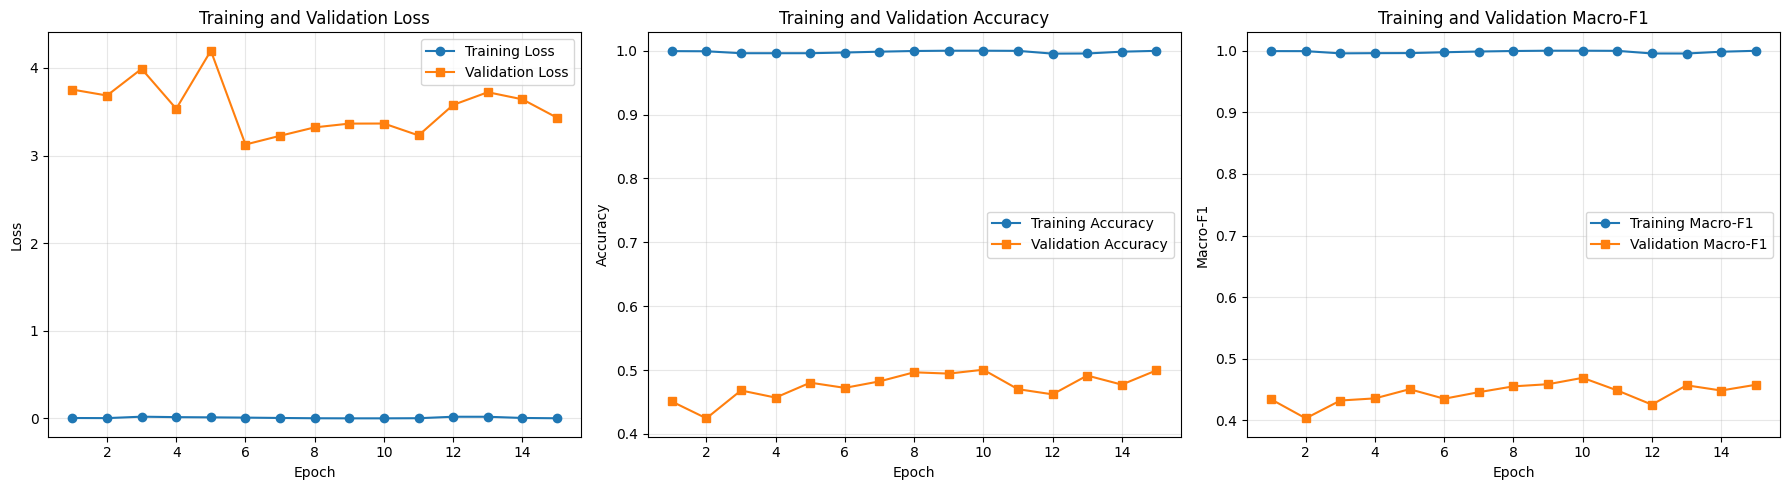

TRAINING CURVE SUMMARY
Maximum epochs: 15
Completed epochs: 15
Best epoch: 10
Best validation Macro-F1: 0.4691
Final training Macro-F1: 0.9999
Final validation Macro-F1: 0.4578


In [ ]:

# CELL 22: BILSTM TRAINING PERFORMANCE GRAPHS

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss
axes[0].plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    epochs_range,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Accuracy
axes[1].plot(
    epochs_range,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    epochs_range,
    history["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Macro-F1
axes[2].plot(
    epochs_range,
    history["train_macro_f1"],
    marker="o",
    label="Training Macro-F1"
)

axes[2].plot(
    epochs_range,
    history["val_macro_f1"],
    marker="s",
    label="Validation Macro-F1"
)

axes[2].set_title("Training and Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 75)
print("TRAINING CURVE SUMMARY")
print("=" * 75)

best_epoch = int(np.argmax(history["val_macro_f1"])) + 1

print("Maximum epochs:", 15)
print("Completed epochs:", len(epochs_range))
print("Best epoch:", best_epoch)
print(
    "Best validation Macro-F1:",
    f"{max(history['val_macro_f1']):.4f}"
)
print(
    "Final training Macro-F1:",
    f"{history['train_macro_f1'][-1]:.4f}"
)
print(
    "Final validation Macro-F1:",
    f"{history['val_macro_f1'][-1]:.4f}"
)


In [ ]:

# CELL 23: FINAL BILSTM TEST EVALUATION

test_loss, test_metrics = evaluate_model(
    model,
    test_loader,
    criterion,
    DEVICE
)

print("=" * 80)
print("BILSTM: FINAL TEST RESULTS")
print("=" * 80)

print(f"Test Loss:             {test_loss:.4f}")
print(f"Test Accuracy:         {test_metrics['Accuracy']:.4f}")
print(f"Macro Precision:       {test_metrics['Macro_Precision']:.4f}")
print(f"Macro Recall:           {test_metrics['Macro_Recall']:.4f}")
print(f"Macro F1-score:        {test_metrics['Macro_F1']:.4f}")
print(f"Weighted Precision:    {test_metrics['Weighted_Precision']:.4f}")
print(f"Weighted Recall:       {test_metrics['Weighted_Recall']:.4f}")
print(f"Weighted F1-score:     {test_metrics['Weighted_F1']:.4f}")

print("\n" + "=" * 80)
print("TEST EVALUATION SUMMARY")
print("=" * 80)

print("Model: Bidirectional LSTM")
print("Relation classes:", NUM_CLASSES)
print("Test records:", len(test_df))
print("Best validation Macro-F1:", f"{best_val_f1:.4f}")
print("Training epochs completed:", len(history["train_loss"]))


BILSTM: FINAL TEST RESULTS
Test Loss:             3.4768
Test Accuracy:         0.4542
Macro Precision:       0.4520
Macro Recall:           0.4550
Macro F1-score:        0.4363
Weighted Precision:    0.4887
Weighted Recall:       0.4542
Weighted F1-score:     0.4565

TEST EVALUATION SUMMARY
Model: Bidirectional LSTM
Relation classes: 10
Test records: 993
Best validation Macro-F1: 0.4691
Training epochs completed: 15


In [ ]:

# CELL 24: DETAILED CLASSIFICATION REPORT

from sklearn.metrics import classification_report

model.eval()

all_test_predictions = []
all_test_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(DEVICE)

        outputs = model(inputs)

        predictions = torch.argmax(outputs, dim=1)

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_labels.extend(
            labels.numpy()
        )

# Generate classification report
report = classification_report(
    all_test_labels,
    all_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("=" * 90)
print("BILSTM: CLASSIFICATION REPORT")
print("=" * 90)

display(
    report_df.round(4)
)

print("\nNumber of actual test records:", len(all_test_labels))
print("Number of predictions:", len(all_test_predictions))

assert len(all_test_labels) == len(test_df)
assert len(all_test_predictions) == len(test_df)

print("\nClassification report generated successfully.")


BILSTM: CLASSIFICATION REPORT


,precision,recall,f1-score,support
Cause-Effect,0.8901,0.6378,0.7431,127.0000
Component-Whole,0.3645,0.3023,0.3305,129.0000
Content-Container,0.3099,0.7213,0.4335,61.0000
Entity-Destination,0.6642,0.6741,0.6691,135.0000
Entity-Origin,0.3371,0.3488,0.3429,86.0000
Instrument-Agency,0.3889,0.5645,0.4605,62.0000
Member-Collection,0.2979,0.2545,0.2745,55.0000
Message-Topic,0.5238,0.2705,0.3568,122.0000
Other,0.4505,0.3937,0.4202,127.0000
Product-Producer,0.2931,0.3820,0.3317,89.0000



Number of actual test records: 993
Number of predictions: 993

Classification report generated successfully.


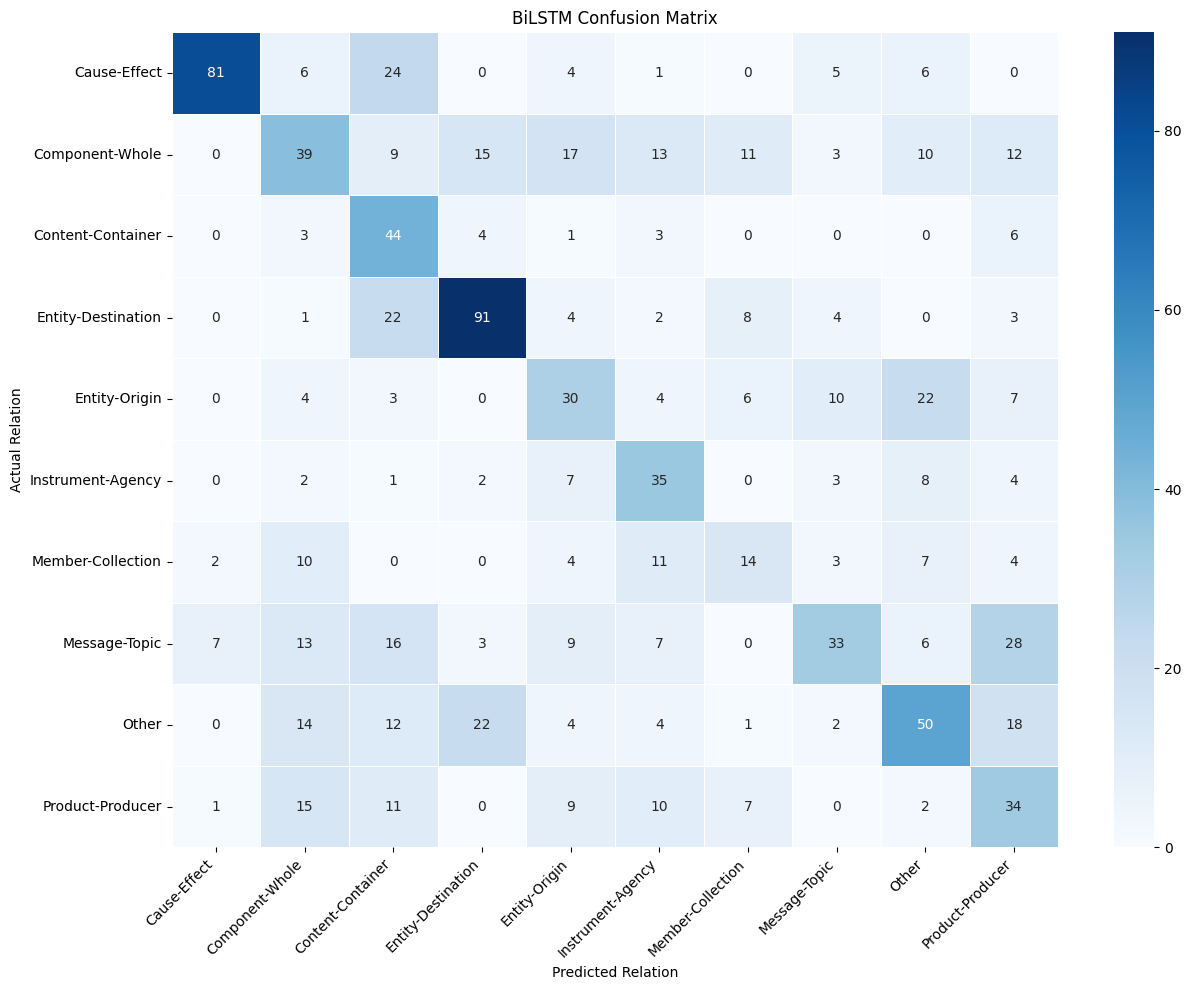

CONFUSION MATRIX


,Cause-Effect,Component-Whole,Content-Container,Entity-Destination,Entity-Origin,Instrument-Agency,Member-Collection,Message-Topic,Other,Product-Producer
Cause-Effect,81,6,24,0,4,1,0,5,6,0
Component-Whole,0,39,9,15,17,13,11,3,10,12
Content-Container,0,3,44,4,1,3,0,0,0,6
Entity-Destination,0,1,22,91,4,2,8,4,0,3
Entity-Origin,0,4,3,0,30,4,6,10,22,7
Instrument-Agency,0,2,1,2,7,35,0,3,8,4
Member-Collection,2,10,0,0,4,11,14,3,7,4
Message-Topic,7,13,16,3,9,7,0,33,6,28
Other,0,14,12,22,4,4,1,2,50,18
Product-Producer,1,15,11,0,9,10,7,0,2,34



Correct predictions: 451
Incorrect predictions: 542
Total test records: 993


In [ ]:

# CELL 25: CONFUSION MATRIX ANALYSIS

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    all_test_labels,
    all_test_predictions,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    linewidths=0.5
)

plt.title("BiLSTM Confusion Matrix")
plt.xlabel("Predicted Relation")
plt.ylabel("Actual Relation")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(cm_df)

correct_predictions = np.trace(cm)
incorrect_predictions = cm.sum() - correct_predictions

print("\nCorrect predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)
print("Total test records:", cm.sum())

assert cm.sum() == len(test_df)


ACTUAL VS PREDICTED CLASS DISTRIBUTION


,Relation,Actual_Count,Predicted_Count,Difference
0,Cause-Effect,127,91,-36
1,Component-Whole,129,107,-22
2,Content-Container,61,142,81
3,Entity-Destination,135,137,2
4,Entity-Origin,86,89,3
5,Instrument-Agency,62,90,28
6,Member-Collection,55,47,-8
7,Message-Topic,122,63,-59
8,Other,127,111,-16
9,Product-Producer,89,116,27


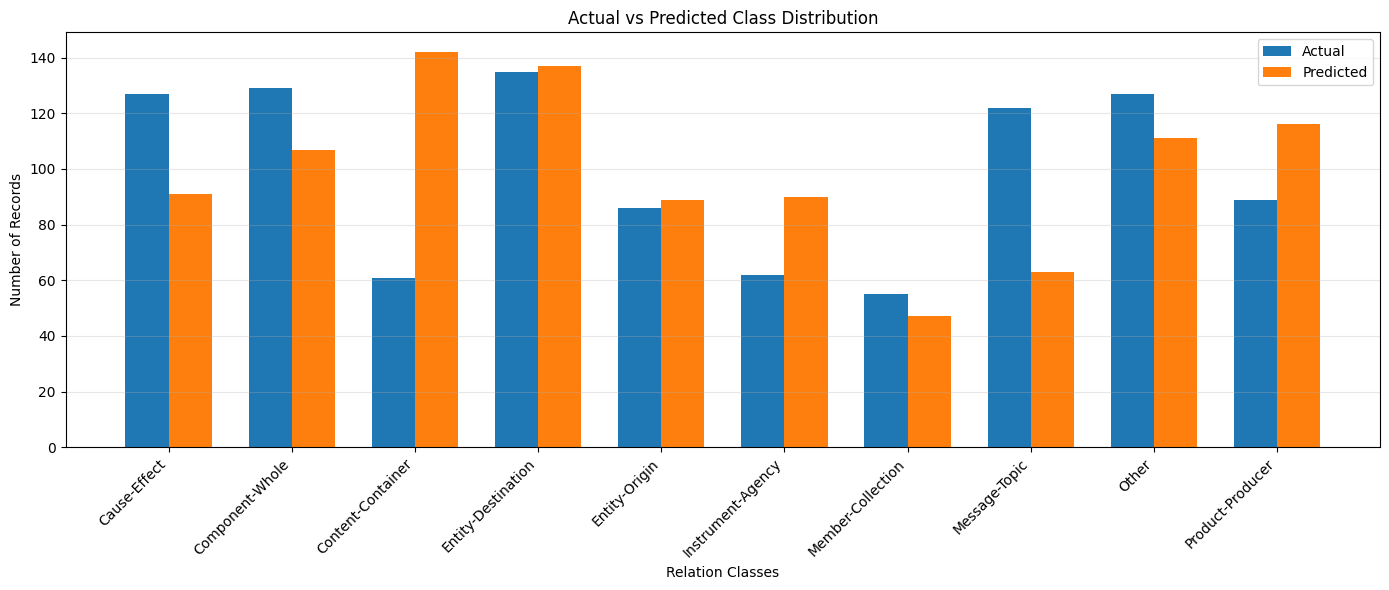


Total actual records: 993
Total predicted records: 993


In [ ]:

# CELL 26: ACTUAL VS PREDICTED CLASS DISTRIBUTION

actual_distribution = pd.Series(
    all_test_labels
).value_counts().reindex(
    range(NUM_CLASSES),
    fill_value=0
)

predicted_distribution = pd.Series(
    all_test_predictions
).value_counts().reindex(
    range(NUM_CLASSES),
    fill_value=0
)

distribution_df = pd.DataFrame({
    "Relation": label_encoder.classes_,
    "Actual_Count": actual_distribution.values,
    "Predicted_Count": predicted_distribution.values
})

distribution_df["Difference"] = (
    distribution_df["Predicted_Count"]
    - distribution_df["Actual_Count"]
)

print("=" * 85)
print("ACTUAL VS PREDICTED CLASS DISTRIBUTION")
print("=" * 85)

display(distribution_df)

# Visualization
x = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    distribution_df["Actual_Count"],
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    distribution_df["Predicted_Count"],
    width,
    label="Predicted"
)

plt.xticks(
    x,
    distribution_df["Relation"],
    rotation=45,
    ha="right"
)

plt.xlabel("Relation Classes")
plt.ylabel("Number of Records")
plt.title("Actual vs Predicted Class Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTotal actual records:", distribution_df["Actual_Count"].sum())
print("Total predicted records:", distribution_df["Predicted_Count"].sum())


In [ ]:

# CELL 27: TOP MISCLASSIFICATION PAIRS

error_records = []

for actual_id in range(NUM_CLASSES):
    for predicted_id in range(NUM_CLASSES):

        if actual_id != predicted_id:

            count = cm[actual_id, predicted_id]

            if count > 0:

                row_total = cm[actual_id].sum()

                error_records.append({
                    "Actual_Relation": label_encoder.classes_[actual_id],
                    "Predicted_Relation": label_encoder.classes_[predicted_id],
                    "Error_Count": int(count),
                    "Percentage_of_Actual_Class": round(
                        count / row_total * 100, 2
                    )
                })

error_df = pd.DataFrame(error_records)

error_df = error_df.sort_values(
    by="Error_Count",
    ascending=False
).reset_index(drop=True)

print("=" * 90)
print("TOP 20 BILSTM MISCLASSIFICATION PAIRS")
print("=" * 90)

display(error_df.head(20))

print("\nTotal misclassified records:", int(cm.sum() - np.trace(cm)))
print("Unique misclassification pairs:", len(error_df))

print("\nMost frequent confusion:")
display(error_df.head(1))


TOP 20 BILSTM MISCLASSIFICATION PAIRS


,Actual_Relation,Predicted_Relation,Error_Count,Percentage_of_Actual_Class
0,Message-Topic,Product-Producer,28,22.95
1,Cause-Effect,Content-Container,24,18.90
2,Entity-Origin,Other,22,25.58
3,Other,Entity-Destination,22,17.32
4,Entity-Destination,Content-Container,22,16.30
5,Other,Product-Producer,18,14.17
6,Component-Whole,Entity-Origin,17,13.18
7,Message-Topic,Content-Container,16,13.11
8,Product-Producer,Component-Whole,15,16.85
9,Component-Whole,Entity-Destination,15,11.63



Total misclassified records: 542
Unique misclassification pairs: 70

Most frequent confusion:


,Actual_Relation,Predicted_Relation,Error_Count,Percentage_of_Actual_Class
0,Message-Topic,Product-Producer,28,22.95


In [ ]:

# CELL 28: INDIVIDUAL MISCLASSIFICATION ANALYSIS

test_results = test_df[
    ["sentence", "relation", "label"]
].copy().reset_index(drop=True)

test_results["Predicted_Label"] = all_test_predictions

test_results["Predicted_Relation"] = (
    label_encoder.inverse_transform(
        test_results["Predicted_Label"]
    )
)

test_results["Correct_Prediction"] = (
    test_results["label"] ==
    test_results["Predicted_Label"]
)

misclassified_df = test_results[
    ~test_results["Correct_Prediction"]
].copy()

print("=" * 90)
print("INDIVIDUAL BILSTM MISCLASSIFICATION ANALYSIS")
print("=" * 90)

print("Total test records:", len(test_results))
print("Correct predictions:", test_results["Correct_Prediction"].sum())
print("Incorrect predictions:", len(misclassified_df))

print("\nFirst 30 misclassified sentences:")

display(
    misclassified_df[
        ["sentence", "relation", "Predicted_Relation"]
    ].head(30)
)

print("\nActual relation distribution among errors:")

display(
    misclassified_df["relation"]
    .value_counts()
    .rename_axis("Actual_Relation")
    .reset_index(name="Error_Count")
)

print("\nPredicted relation distribution among errors:")

display(
    misclassified_df["Predicted_Relation"]
    .value_counts()
    .rename_axis("Predicted_Relation")
    .reset_index(name="Error_Count")
)


INDIVIDUAL BILSTM MISCLASSIFICATION ANALYSIS
Total test records: 993
Correct predictions: 451
Incorrect predictions: 542

First 30 misclassified sentences:


,sentence,relation,Predicted_Relation
0,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,Content-Container,Product-Producer
1,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,Product-Producer,Instrument-Agency
2,የደራሲው መጽሐፎቹ እና <e1>መጣጥፎች</e1> ዘመናዊውን <e2>ታሪክ</...,Cause-Effect,Content-Container
3,ቤትዎ የጨርቆችን ውበት ፣ ባለ ደም አፍንጫዎችን ፣ ወይም <e1>የጦፎችን...,Member-Collection,Instrument-Agency
5,ተላላፊው የባክቴሪያ በሽታ <e1>ብሩካላይተስ</e1> በምስራቃዊ ኤርትራ ...,Other,Content-Container
6,ይህ የተፈጥሮ ስጦታ <e1>ፍቅር</e1> ከአንድ ሺህ ዓመታት በላይ በተነ...,Message-Topic,Product-Producer
7,የተለያዩ የኢትዮጵያ የሙዚቃ መሳሪያዎችን ለመጫወት ከፍተኛ ብቃት ያላቸውን...,Member-Collection,Other
8,በስልክ ስለ ሽብርተኝነት ስጋት ያወራው <e1>ተሳፋሪ</e1> ባቡር ላይ ...,Entity-Origin,Member-Collection
9,<e1>በመጽሐፉ</e1> ውስጥ ያለው <e2>መግቢያ</e2> የመጽሐፉ ማጠቃ...,Component-Whole,Product-Producer
10,<e1>የጫማውን</e1> <e2>ተረከዝ</e2> በሚነካ ሁኔታ ተረከዙን በመ...,Component-Whole,Instrument-Agency



Actual relation distribution among errors:


,Actual_Relation,Error_Count
0,Component-Whole,90
1,Message-Topic,89
2,Other,77
3,Entity-Origin,56
4,Product-Producer,55
5,Cause-Effect,46
6,Entity-Destination,44
7,Member-Collection,41
8,Instrument-Agency,27
9,Content-Container,17



Predicted relation distribution among errors:


,Predicted_Relation,Error_Count
0,Content-Container,98
1,Product-Producer,82
2,Component-Whole,68
3,Other,61
4,Entity-Origin,59
5,Instrument-Agency,55
6,Entity-Destination,46
7,Member-Collection,33
8,Message-Topic,30
9,Cause-Effect,10


In [ ]:

# CELL 29: TRAINING HISTORY SUMMARY

history_df = pd.DataFrame(history)

history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "Epoch"

print("=" * 80)
print("BILSTM TRAINING HISTORY SUMMARY")
print("=" * 80)

display(history_df.round(4))

best_epoch = history_df["val_macro_f1"].idxmax()

print("\nBest epoch:", best_epoch)
print("Best validation Macro-F1:",
      round(history_df.loc[best_epoch, "val_macro_f1"], 4))

print("\nTotal epochs completed:", len(history_df))
print("Configured maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)


BILSTM TRAINING HISTORY SUMMARY


,train_loss,val_loss,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
Epoch,,,,,,
1,0.0044,3.7527,0.9993,0.4508,0.9994,0.4342
2,0.0032,3.6848,0.9991,0.4244,0.9993,0.4033
3,0.0195,3.9896,0.9961,0.4680,0.9957,0.4323
4,0.0143,3.5341,0.9961,0.4569,0.9960,0.4358
5,0.0119,4.1963,0.9961,0.4802,0.9961,0.4506
6,0.0089,3.1256,0.9972,0.4721,0.9975,0.4352
7,0.0049,3.2254,0.9985,0.4822,0.9987,0.4458
8,0.0016,3.3215,0.9996,0.4964,0.9995,0.4553
9,0.0006,3.3644,1.0000,0.4944,1.0000,0.4587



Best epoch: 10
Best validation Macro-F1: 0.4691

Total epochs completed: 15
Configured maximum epochs: 15
Early stopping patience: 5


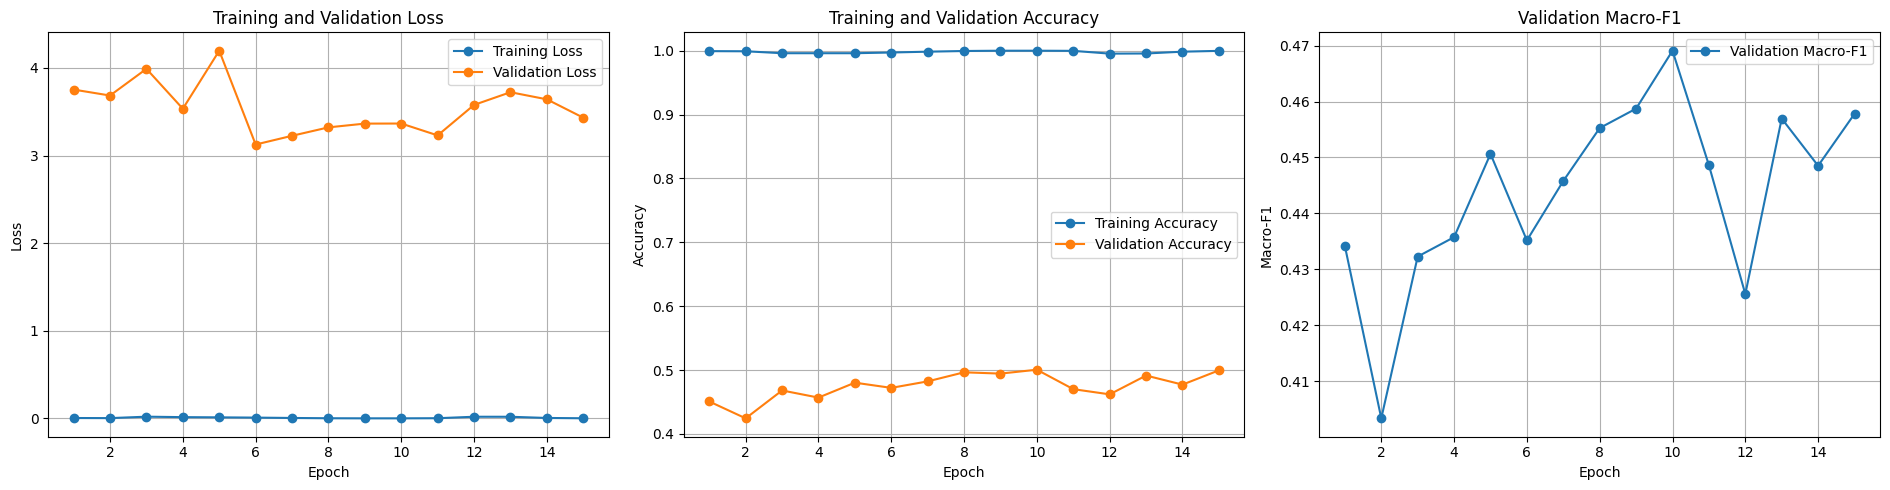

In [ ]:

# CELL 30: BILSTM TRAINING CURVES

import matplotlib.pyplot as plt

required_keys = [
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy",
    "val_macro_f1"
]

missing_keys = [key for key in required_keys if key not in history]

if missing_keys:
    raise KeyError(
        f"Missing history keys: {missing_keys}. "
        "Check CELL 21 before plotting."
    )

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Loss
axes[0].plot(epochs, history["train_loss"], marker="o",
             label="Training Loss")
axes[0].plot(epochs, history["val_loss"], marker="o",
             label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(epochs, history["train_accuracy"], marker="o",
             label="Training Accuracy")
axes[1].plot(epochs, history["val_accuracy"], marker="o",
             label="Validation Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. Validation Macro-F1
axes[2].plot(epochs, history["val_macro_f1"], marker="o",
             label="Validation Macro-F1")
axes[2].set_title("Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# CELL 31: FINAL BILSTM PERFORMANCE METRICS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    all_test_labels, all_test_predictions
)

macro_precision = precision_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

macro_recall = recall_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

macro_f1 = f1_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

weighted_precision = precision_score(
    all_test_labels, all_test_predictions,
    average="weighted", zero_division=0
)

weighted_recall = recall_score(
    all_test_labels, all_test_predictions,
    average="weighted", zero_division=0
)

weighted_f1 = f1_score(
    all_test_labels, all_test_predictions,
    average="weighted", zero_division=0
)

performance_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_precision,
        weighted_recall,
        weighted_f1
    ]
})

performance_df["Percentage"] = (
    performance_df["Score"] * 100
).round(2)

print("=" * 75)
print("FINAL BILSTM TEST PERFORMANCE")
print("=" * 75)

display(performance_df.round(4))


FINAL BILSTM TEST PERFORMANCE


,Metric,Score,Percentage
0,Accuracy,0.4542,45.42
1,Macro Precision,0.4520,45.20
2,Macro Recall,0.4550,45.50
3,Macro F1-score,0.4363,43.63
4,Weighted Precision,0.4887,48.87
5,Weighted Recall,0.4542,45.42
6,Weighted F1-score,0.4565,45.65


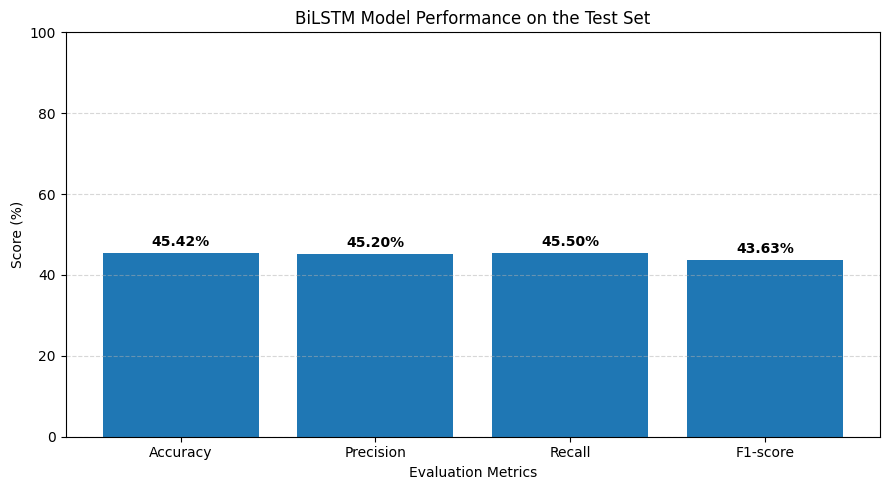

In [ ]:

# CELL 31: BILSTM PERFORMANCE METRICS GRAPH

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy_score(
        all_test_labels, all_test_predictions
    ),
    "Precision": precision_score(
        all_test_labels, all_test_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        all_test_labels, all_test_predictions,
        average="macro", zero_division=0
    ),
    "F1-score": f1_score(
        all_test_labels, all_test_predictions,
        average="macro", zero_division=0
    )
}

names = list(metrics.keys())
scores = [value * 100 for value in metrics.values()]

plt.figure(figsize=(9, 5))

bars = plt.bar(names, scores)

plt.title("BiLSTM Model Performance on the Test Set")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


In [ ]:

# CELL 32: AFROXLM-R DEPENDENCIES

!pip -q install transformers sentencepiece accelerate

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader

print("AfroXLM-R dependencies installed successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)


AfroXLM-R dependencies installed successfully.
PyTorch version: 2.14.1+cu130
CUDA available: True
Device: cuda


In [ ]:

# CELL 33: AFROXLM-R TOKENIZER

MODEL_NAME = "Davlan/afro-xlmr-base"

afro_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Measure subword token lengths using training data only
train_token_lengths = [
    len(afro_tokenizer.encode(
        sentence,
        add_special_tokens=True,
        truncation=False
    ))
    for sentence in train_df["sentence"].astype(str)
]

print("=" * 75)
print("AFROXLM-R TOKENIZER ANALYSIS")
print("=" * 75)

print("Pretrained model:", MODEL_NAME)
print("Tokenizer vocabulary size:", len(afro_tokenizer))
print("Training sentences:", len(train_token_lengths))
print("Minimum token length:", min(train_token_lengths))
print("Maximum token length:", max(train_token_lengths))
print("Mean token length:", round(np.mean(train_token_lengths), 2))
print("Median token length:", int(np.median(train_token_lengths)))
print("95th percentile:", int(np.percentile(train_token_lengths, 95)))

# Use the training-set 95th percentile, capped at 512
MAX_TOKEN_LENGTH = min(
    max(int(np.percentile(train_token_lengths, 95)), 32),
    512
)

print("\nSelected maximum sequence length:", MAX_TOKEN_LENGTH)


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

AFROXLM-R TOKENIZER ANALYSIS
Pretrained model: Davlan/afro-xlmr-base
Tokenizer vocabulary size: 250002
Training sentences: 4602
Minimum token length: 24
Maximum token length: 117
Mean token length: 45.8
Median token length: 43
95th percentile: 66

Selected maximum sequence length: 66


In [ ]:

# CELL 34: AFROXLM-R DATASET PREPARATION

class AfroXLMRDataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length):
        self.sentences = dataframe["sentence"].astype(str).tolist()
        self.labels = dataframe["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, index):

        encoding = self.tokenizer(
            self.sentences[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }


afro_train_dataset = AfroXLMRDataset(
    train_df, afro_tokenizer, MAX_TOKEN_LENGTH
)

afro_val_dataset = AfroXLMRDataset(
    val_df, afro_tokenizer, MAX_TOKEN_LENGTH
)

afro_test_dataset = AfroXLMRDataset(
    test_df, afro_tokenizer, MAX_TOKEN_LENGTH
)

AFRO_BATCH_SIZE = 16

afro_train_loader = DataLoader(
    afro_train_dataset,
    batch_size=AFRO_BATCH_SIZE,
    shuffle=True
)

afro_val_loader = DataLoader(
    afro_val_dataset,
    batch_size=AFRO_BATCH_SIZE,
    shuffle=False
)

afro_test_loader = DataLoader(
    afro_test_dataset,
    batch_size=AFRO_BATCH_SIZE,
    shuffle=False
)

print("=" * 75)
print("AFROXLM-R DATASET SUMMARY")
print("=" * 75)

print("Training records:", len(afro_train_dataset))
print("Validation records:", len(afro_val_dataset))
print("Test records:", len(afro_test_dataset))
print("Number of classes:", NUM_CLASSES)
print("Batch size:", AFRO_BATCH_SIZE)
print("Maximum token length:", MAX_TOKEN_LENGTH)

# Verify one batch
sample_batch = next(iter(afro_train_loader))

print("\nInput IDs shape:", sample_batch["input_ids"].shape)
print("Attention mask shape:", sample_batch["attention_mask"].shape)
print("Labels shape:", sample_batch["labels"].shape)

assert sample_batch["input_ids"].shape[1] == MAX_TOKEN_LENGTH
assert len(afro_train_dataset) == len(train_df)
assert len(afro_val_dataset) == len(val_df)
assert len(afro_test_dataset) == len(test_df)

print("\nDataset preparation completed successfully.")


AFROXLM-R DATASET SUMMARY
Training records: 4602
Validation records: 985
Test records: 993
Number of classes: 10
Batch size: 16
Maximum token length: 66

Input IDs shape: torch.Size([16, 66])
Attention mask shape: torch.Size([16, 66])
Labels shape: torch.Size([16])

Dataset preparation completed successfully.


In [ ]:

# CELL 35: LOAD AFROXLM-R MODEL

id2label = {
    i: label for i, label in enumerate(label_encoder.classes_)
}

label2id = {
    label: i for i, label in id2label.items()
}

afro_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id
).to(DEVICE)

print("=" * 75)
print("AFROXLM-R MODEL CONFIGURATION")
print("=" * 75)

print("Pretrained checkpoint:", MODEL_NAME)
print("Number of relation classes:", NUM_CLASSES)
print("Device:", DEVICE)

print("\nRelation label mapping:")
for class_id, relation in id2label.items():
    print(f"{class_id}: {relation}")

total_parameters = sum(
    parameter.numel()
    for parameter in afro_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in afro_model.parameters()
    if parameter.requires_grad
)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nAfroXLM-R model loaded successfully.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


AFROXLM-R MODEL CONFIGURATION
Pretrained checkpoint: Davlan/afro-xlmr-base
Number of relation classes: 10
Device: cuda

Relation label mapping:
0: Cause-Effect
1: Component-Whole
2: Content-Container
3: Entity-Destination
4: Entity-Origin
5: Instrument-Agency
6: Member-Collection
7: Message-Topic
8: Other
9: Product-Producer

Total parameters: 278,051,338
Trainable parameters: 278,051,338

AfroXLM-R model loaded successfully.


In [ ]:

# CELL 36: AFROXLM-R OPTIMIZER AND SCHEDULER

from sklearn.utils.class_weight import compute_class_weight

AFRO_EPOCHS = 15
AFRO_PATIENCE = 5
AFRO_LEARNING_RATE = 2e-5
AFRO_WEIGHT_DECAY = 0.01

# Calculate class weights using training labels only
afro_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].to_numpy()
)

afro_class_weights = torch.tensor(
    afro_class_weights,
    dtype=torch.float32,
    device=DEVICE
)

# Weighted classification loss
afro_criterion = nn.CrossEntropyLoss(
    weight=afro_class_weights
)

# Optimizer
afro_optimizer = AdamW(
    afro_model.parameters(),
    lr=AFRO_LEARNING_RATE,
    weight_decay=AFRO_WEIGHT_DECAY
)

# Learning rate scheduler
total_training_steps = (
    len(afro_train_loader) * AFRO_EPOCHS
)

warmup_steps = int(0.1 * total_training_steps)

afro_scheduler = get_linear_schedule_with_warmup(
    afro_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("=" * 75)
print("AFROXLM-R TRAINING CONFIGURATION")
print("=" * 75)

print("Maximum epochs:", AFRO_EPOCHS)
print("Early stopping patience:", AFRO_PATIENCE)
print("Learning rate:", AFRO_LEARNING_RATE)
print("Weight decay:", AFRO_WEIGHT_DECAY)
print("Optimizer: AdamW")
print("Loss function: Weighted CrossEntropyLoss")
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

print("\nTraining class weights:")
for i, weight in enumerate(afro_class_weights.cpu().numpy()):
    print(f"{id2label[i]}: {weight:.4f}")

print("\nAfroXLM-R optimizer and scheduler configured.")


AFROXLM-R TRAINING CONFIGURATION
Maximum epochs: 15
Early stopping patience: 5
Learning rate: 2e-05
Weight decay: 0.01
Optimizer: AdamW
Loss function: Weighted CrossEntropyLoss
Total training steps: 4320
Warmup steps: 432

Training class weights:
Cause-Effect: 0.8460
Component-Whole: 1.1680
Content-Container: 1.4204
Entity-Destination: 0.6973
Entity-Origin: 1.1770
Instrument-Agency: 1.6035
Member-Collection: 1.5979
Message-Topic: 0.8444
Other: 0.5811
Product-Producer: 1.2207

AfroXLM-R optimizer and scheduler configured.


In [ ]:

# CELL 37: AFROXLM-R TRAINING AND EVALUATION FUNCTIONS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tqdm.auto import tqdm

def afro_train_one_epoch(model, loader, optimizer, scheduler):

    model.train()

    total_loss = 0
    all_labels = []
    all_predictions = []

    for batch in tqdm(loader, desc="Training", leave=False):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = afro_criterion(
            outputs.logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    metrics = {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            all_labels, all_predictions,
            average="weighted", zero_division=0
        )
    }

    return total_loss / len(loader), metrics


def afro_evaluate(model, loader):

    model.eval()

    total_loss = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in tqdm(loader, desc="Evaluating", leave=False):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = afro_criterion(
                outputs.logits,
                labels
            )

            total_loss += loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    metrics = {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            all_labels, all_predictions,
            average="weighted", zero_division=0
        )
    }

    return total_loss / len(loader), metrics


print("AfroXLM-R training and evaluation functions defined successfully.")


AfroXLM-R training and evaluation functions defined successfully.


In [ ]:

# CELL 38: AFROXLM-R MODEL TRAINING

import copy

afro_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_macro_f1": [],
    "val_macro_f1": [],
    "train_macro_precision": [],
    "val_macro_precision": [],
    "train_macro_recall": [],
    "val_macro_recall": [],
    "train_weighted_f1": [],
    "val_weighted_f1": []
}

best_afro_macro_f1 = -1.0
best_afro_epoch = 0
afro_patience_counter = 0

best_afro_state = None

print("=" * 80)
print("AFROXLM-R FINE-TUNING")
print("=" * 80)

for epoch in range(1, AFRO_EPOCHS + 1):

    print(f"\nEpoch [{epoch}/{AFRO_EPOCHS}]")

    train_loss, train_metrics = afro_train_one_epoch(
        afro_model,
        afro_train_loader,
        afro_optimizer,
        afro_scheduler
    )

    val_loss, val_metrics = afro_evaluate(
        afro_model,
        afro_val_loader
    )

    afro_history["train_loss"].append(train_loss)
    afro_history["val_loss"].append(val_loss)

    for metric in [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1"
    ]:
        afro_history[f"train_{metric}"].append(
            train_metrics[metric]
        )
        afro_history[f"val_{metric}"].append(
            val_metrics[metric]
        )

    print(f"Train Loss: {train_loss:.4f} | "
          f"Train Accuracy: {train_metrics['accuracy']:.4f}")

    print(f"Validation Loss: {val_loss:.4f} | "
          f"Validation Accuracy: {val_metrics['accuracy']:.4f}")

    print(f"Validation Precision: {val_metrics['macro_precision']:.4f} | "
          f"Validation Recall: {val_metrics['macro_recall']:.4f} | "
          f"Validation Macro-F1: {val_metrics['macro_f1']:.4f}")

    if val_metrics["macro_f1"] > best_afro_macro_f1:

        best_afro_macro_f1 = val_metrics["macro_f1"]
        best_afro_epoch = epoch
        afro_patience_counter = 0

        best_afro_state = copy.deepcopy(
            afro_model.state_dict()
        )

        torch.save(
            best_afro_state,
            "best_afroxlmr_model.pth"
        )

        print("Best model checkpoint saved.")

    else:
        afro_patience_counter += 1
        print(
            f"No improvement. Patience: "
            f"{afro_patience_counter}/{AFRO_PATIENCE}"
        )

    if afro_patience_counter >= AFRO_PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best validation checkpoint
if best_afro_state is None:
    raise RuntimeError("No valid AfroXLM-R checkpoint was saved.")

afro_model.load_state_dict(best_afro_state)

print("\n" + "=" * 80)
print("AFROXLM-R TRAINING COMPLETED")
print("=" * 80)

print("Best epoch:", best_afro_epoch)
print("Best validation Macro-F1:",
      round(best_afro_macro_f1, 4))
print("Epochs completed:", len(afro_history["train_loss"]))
print("Best model restored successfully.")


AFROXLM-R FINE-TUNING

Epoch [1/15]


Training:   0%|          | 0/288 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/62 [00:00<?, ?it/s]

Train Loss: 2.1541 | Train Accuracy: 0.2405
Validation Loss: 1.5918 | Validation Accuracy: 0.5533
Validation Precision: 0.5354 | Validation Recall: 0.5102 | Validation Macro-F1: 0.4799
Best model checkpoint saved.

Epoch [2/15]


Training:   0%|          | 0/288 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/62 [00:00<?, ?it/s]

... (27 outputs left out)

Train Loss: 0.0015 | Train Accuracy: 0.9998
Validation Loss: 2.2139 | Validation Accuracy: 0.7188
Validation Precision: 0.7378 | Validation Recall: 0.6901 | Validation Macro-F1: 0.6978
No improvement. Patience: 4/5

Epoch [12/15]


Training:   0%|          | 0/288 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/62 [00:00<?, ?it/s]

Train Loss: 0.0005 | Train Accuracy: 1.0000
Validation Loss: 2.2736 | Validation Accuracy: 0.7137
Validation Precision: 0.7391 | Validation Recall: 0.6940 | Validation Macro-F1: 0.7013
No improvement. Patience: 5/5

Early stopping triggered.

AFROXLM-R TRAINING COMPLETED
Best epoch: 7
Best validation Macro-F1: 0.7165
Epochs completed: 12
Best model restored successfully.


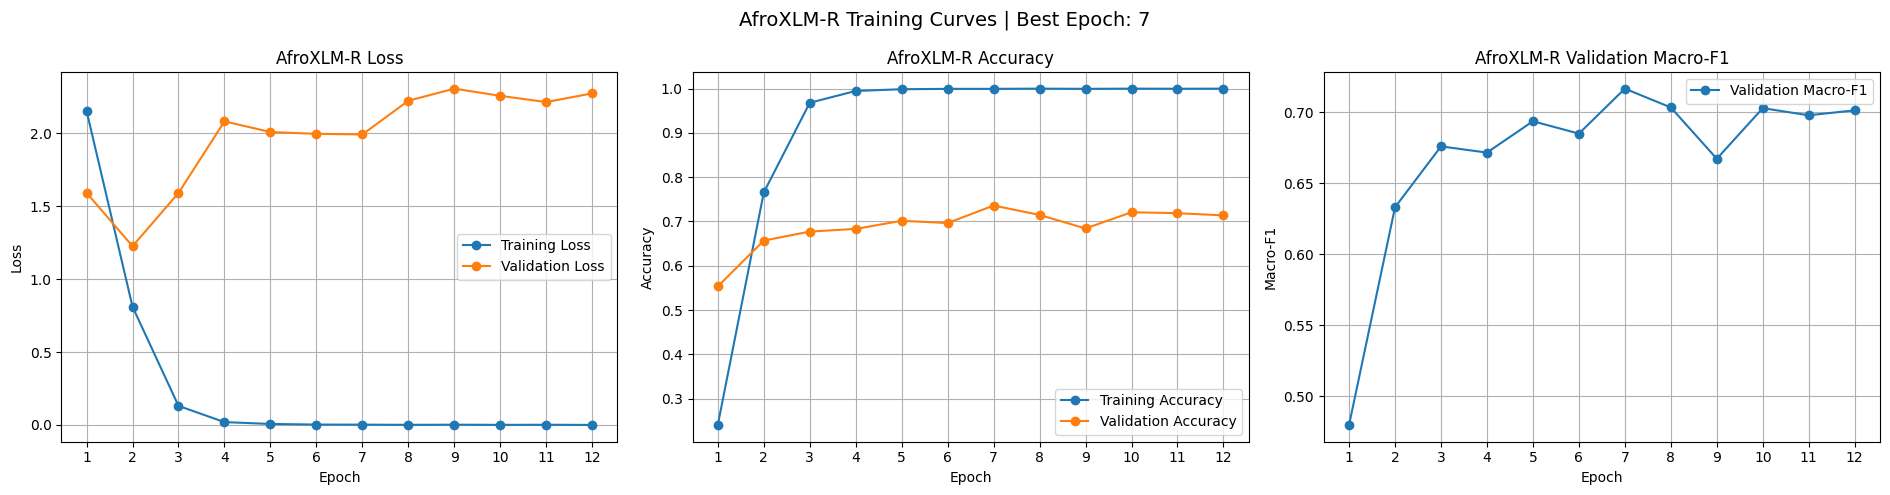

In [ ]:

# CELL 39: AFROXLM-R TRAINING CURVES

epochs = range(1, len(afro_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Training and validation loss
axes[0].plot(
    epochs, afro_history["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs, afro_history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[0].set_title("AfroXLM-R Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Training and validation accuracy
axes[1].plot(
    epochs, afro_history["train_accuracy"],
    marker="o", label="Training Accuracy"
)
axes[1].plot(
    epochs, afro_history["val_accuracy"],
    marker="o", label="Validation Accuracy"
)
axes[1].set_title("AfroXLM-R Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. Validation Macro-F1
axes[2].plot(
    epochs, afro_history["val_macro_f1"],
    marker="o", label="Validation Macro-F1"
)
axes[2].set_title("AfroXLM-R Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].legend()
axes[2].grid(True)

for ax in axes:
    ax.set_xticks(list(epochs))

plt.suptitle(
    f"AfroXLM-R Training Curves | Best Epoch: {best_afro_epoch}",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [ ]:

# CELL 40: AFROXLM-R FINAL TEST EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

afro_model.eval()

afro_test_labels = []
afro_test_predictions = []
afro_test_loss = 0

with torch.no_grad():

    for batch in afro_test_loader:

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = afro_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = afro_criterion(outputs.logits, labels)
        afro_test_loss += loss.item()

        predictions = torch.argmax(outputs.logits, dim=1)

        afro_test_labels.extend(labels.cpu().numpy())
        afro_test_predictions.extend(predictions.cpu().numpy())

# Final metrics
afro_test_metrics = {
    "Accuracy": accuracy_score(
        afro_test_labels, afro_test_predictions
    ),
    "Macro Precision": precision_score(
        afro_test_labels, afro_test_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        afro_test_labels, afro_test_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1-score": f1_score(
        afro_test_labels, afro_test_predictions,
        average="macro", zero_division=0
    ),
    "Weighted F1-score": f1_score(
        afro_test_labels, afro_test_predictions,
        average="weighted", zero_division=0
    )
}

afro_test_loss /= len(afro_test_loader)

print("=" * 80)
print("AFROXLM-R FINAL TEST RESULTS")
print("=" * 80)

print("Test Loss:", round(afro_test_loss, 4))
print("Best Epoch:", best_afro_epoch)
print("Test Records:", len(afro_test_labels))

for metric, value in afro_test_metrics.items():
    print(f"{metric:25s}: {value:.4f} ({value * 100:.2f}%)")

assert len(afro_test_labels) == len(test_df)
assert len(afro_test_predictions) == len(test_df)

print("\nTest evaluation completed successfully.")


AFROXLM-R FINAL TEST RESULTS
Test Loss: 2.6225
Best Epoch: 7
Test Records: 993
Accuracy                 : 0.6354 (63.54%)
Macro Precision          : 0.6678 (66.78%)
Macro Recall             : 0.6323 (63.23%)
Macro F1-score           : 0.6391 (63.91%)
Weighted F1-score        : 0.6469 (64.69%)

Test evaluation completed successfully.


In [ ]:

# CELL 41: AFROXLM-R CLASSIFICATION REPORT

from sklearn.metrics import classification_report

afro_report = classification_report(
    afro_test_labels,
    afro_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

afro_report_df = pd.DataFrame(afro_report).transpose()

print("=" * 90)
print("AFROXLM-R PER-CLASS CLASSIFICATION REPORT")
print("=" * 90)

display(afro_report_df.round(4))

print("\nPer-class results only:")

display(
    afro_report_df.loc[
        label_encoder.classes_,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)


AFROXLM-R PER-CLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
Cause-Effect,0.7626,0.8346,0.7970,127.0000
Component-Whole,0.8333,0.6977,0.7595,129.0000
Content-Container,0.7887,0.9180,0.8485,61.0000
Entity-Destination,0.8990,0.6593,0.7607,135.0000
Entity-Origin,0.6800,0.5930,0.6335,86.0000
Instrument-Agency,0.6269,0.6774,0.6512,62.0000
Member-Collection,0.3934,0.4364,0.4138,55.0000
Message-Topic,0.6759,0.5984,0.6348,122.0000
Other,0.2977,0.5039,0.3743,127.0000
Product-Producer,0.7200,0.4045,0.5180,89.0000



Per-class results only:


,precision,recall,f1-score,support
Cause-Effect,0.7626,0.8346,0.7970,127.0
Component-Whole,0.8333,0.6977,0.7595,129.0
Content-Container,0.7887,0.9180,0.8485,61.0
Entity-Destination,0.8990,0.6593,0.7607,135.0
Entity-Origin,0.6800,0.5930,0.6335,86.0
Instrument-Agency,0.6269,0.6774,0.6512,62.0
Member-Collection,0.3934,0.4364,0.4138,55.0
Message-Topic,0.6759,0.5984,0.6348,122.0
Other,0.2977,0.5039,0.3743,127.0
Product-Producer,0.7200,0.4045,0.5180,89.0


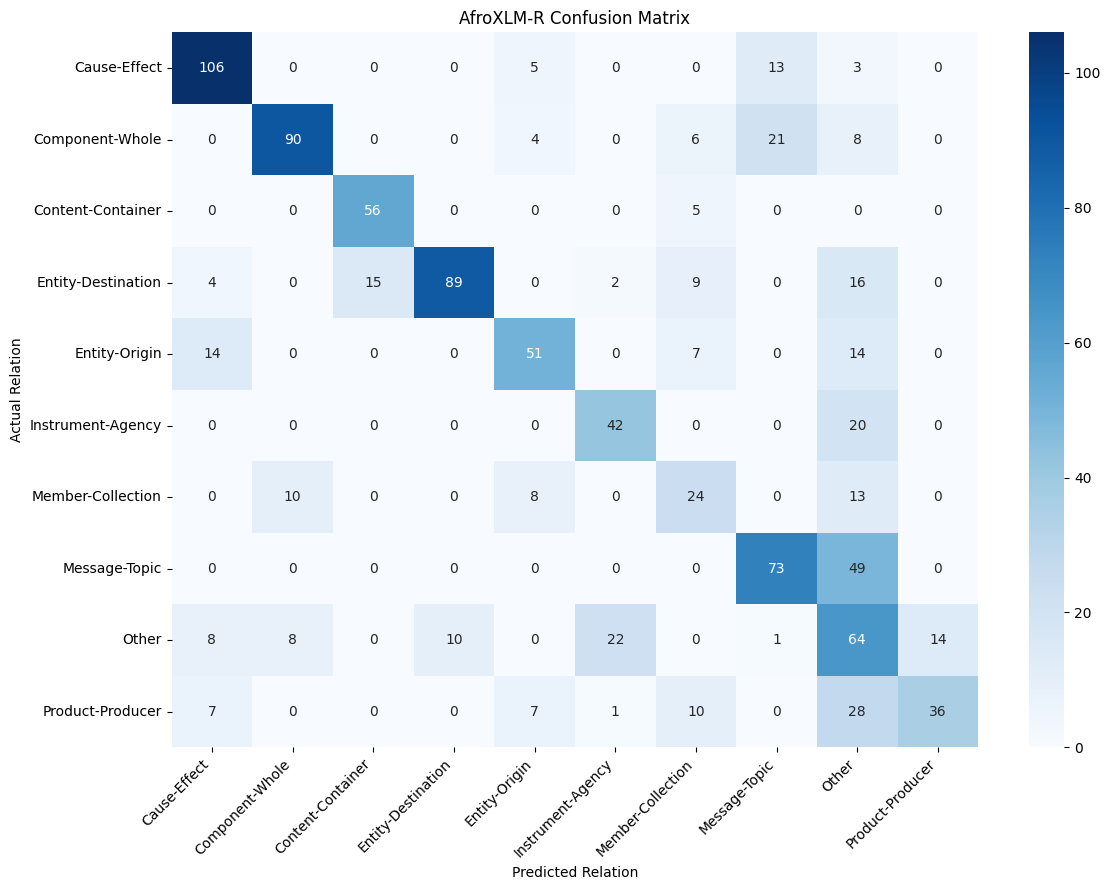

AFROXLM-R CONFUSION MATRIX VALUES


,Cause-Effect,Component-Whole,Content-Container,Entity-Destination,Entity-Origin,Instrument-Agency,Member-Collection,Message-Topic,Other,Product-Producer
Cause-Effect,106,0,0,0,5,0,0,13,3,0
Component-Whole,0,90,0,0,4,0,6,21,8,0
Content-Container,0,0,56,0,0,0,5,0,0,0
Entity-Destination,4,0,15,89,0,2,9,0,16,0
Entity-Origin,14,0,0,0,51,0,7,0,14,0
Instrument-Agency,0,0,0,0,0,42,0,0,20,0
Member-Collection,0,10,0,0,8,0,24,0,13,0
Message-Topic,0,0,0,0,0,0,0,73,49,0
Other,8,8,0,10,0,22,0,1,64,14
Product-Producer,7,0,0,0,7,1,10,0,28,36



Total test records: 993
Correct predictions: 631
Incorrect predictions: 362


In [ ]:

# CELL 42: AFROXLM-R CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

afro_cm = confusion_matrix(
    afro_test_labels,
    afro_test_predictions,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    afro_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("AfroXLM-R Confusion Matrix")
plt.xlabel("Predicted Relation")
plt.ylabel("Actual Relation")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("=" * 80)
print("AFROXLM-R CONFUSION MATRIX VALUES")
print("=" * 80)

afro_cm_df = pd.DataFrame(
    afro_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(afro_cm_df)

print("\nTotal test records:", afro_cm.sum())
print("Correct predictions:", np.trace(afro_cm))
print("Incorrect predictions:", afro_cm.sum() - np.trace(afro_cm))


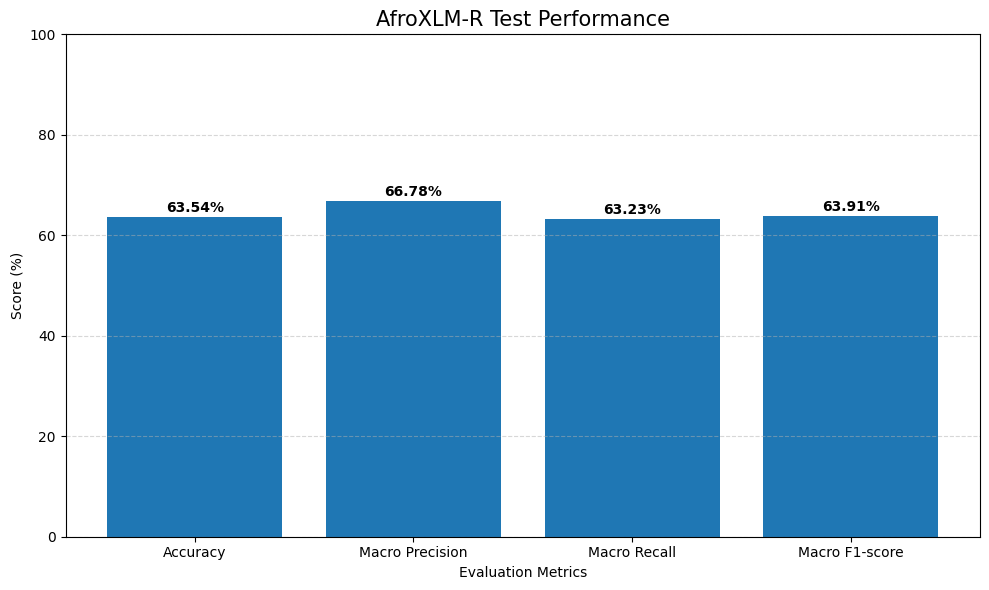

In [ ]:

# CELL 43: AFROXLM-R PERFORMANCE GRAPH

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

metric_values = [
    afro_test_metrics[name] * 100
    for name in metric_names
]

plt.figure(figsize=(10, 6))

bars = plt.bar(metric_names, metric_values)

plt.title(
    "AfroXLM-R Test Performance",
    fontsize=15
)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


In [ ]:

# CELL 44: SAVE AFROXLM-R EXPERIMENT

import os

AFRO_SAVE_DIR = "/content/AfroXLMR_Results"
os.makedirs(AFRO_SAVE_DIR, exist_ok=True)

# 1. Save pretrained model and fine-tuned weights
afro_model.save_pretrained(
    os.path.join(AFRO_SAVE_DIR, "model")
)

afro_tokenizer.save_pretrained(
    os.path.join(AFRO_SAVE_DIR, "model")
)

# 2. Save training history
pd.DataFrame(afro_history).to_csv(
    os.path.join(AFRO_SAVE_DIR, "training_history.csv"),
    index=False
)

# 3. Save final evaluation metrics
pd.DataFrame(
    list(afro_test_metrics.items()),
    columns=["Metric", "Score"]
).to_csv(
    os.path.join(AFRO_SAVE_DIR, "test_metrics.csv"),
    index=False
)

# 4. Save classification report
afro_report_df.to_csv(
    os.path.join(AFRO_SAVE_DIR, "classification_report.csv")
)

# 5. Save confusion matrix
afro_cm_df.to_csv(
    os.path.join(AFRO_SAVE_DIR, "confusion_matrix.csv")
)

# 6. Save individual test predictions
afro_predictions_df = test_df[
    ["sentence", "relation", "label"]
].copy().reset_index(drop=True)

afro_predictions_df["Predicted_Label"] = afro_test_predictions

afro_predictions_df["Predicted_Relation"] = (
    label_encoder.inverse_transform(
        np.asarray(afro_test_predictions)
    )
)

afro_predictions_df["Correct"] = (
    afro_predictions_df["label"] ==
    afro_predictions_df["Predicted_Label"]
)

afro_predictions_df.to_csv(
    os.path.join(AFRO_SAVE_DIR, "test_predictions.csv"),
    index=False
)

# 7. Save experiment configuration
afro_config = pd.DataFrame({
    "Setting": [
        "Model",
        "Maximum Epochs",
        "Best Epoch",
        "Learning Rate",
        "Batch Size",
        "Maximum Token Length",
        "Number of Classes",
        "Training Records",
        "Validation Records",
        "Test Records"
    ],
    "Value": [
        MODEL_NAME,
        AFRO_EPOCHS,
        best_afro_epoch,
        AFRO_LEARNING_RATE,
        AFRO_BATCH_SIZE,
        MAX_TOKEN_LENGTH,
        NUM_CLASSES,
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

afro_config.to_csv(
    os.path.join(AFRO_SAVE_DIR, "experiment_configuration.csv"),
    index=False
)

print("=" * 75)
print("AFROXLM-R EXPERIMENT SAVED SUCCESSFULLY")
print("=" * 75)

for root, dirs, files in os.walk(AFRO_SAVE_DIR):
    for file in files:
        print(os.path.join(root, file))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

AFROXLM-R EXPERIMENT SAVED SUCCESSFULLY
/content/AfroXLMR_Results/test_predictions.csv
/content/AfroXLMR_Results/classification_report.csv
/content/AfroXLMR_Results/test_metrics.csv
/content/AfroXLMR_Results/training_history.csv
/content/AfroXLMR_Results/confusion_matrix.csv
/content/AfroXLMR_Results/experiment_configuration.csv
/content/AfroXLMR_Results/model/tokenizer_config.json
/content/AfroXLMR_Results/model/config.json
/content/AfroXLMR_Results/model/model.safetensors
/content/AfroXLMR_Results/model/tokenizer.json


In [ ]:

# CELL 45: AFROXLM-R CLASSIFICATION REPORT

from sklearn.metrics import classification_report

print("=" * 90)
print("AFROXLM-R CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        afro_test_labels,
        afro_test_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)


AFROXLM-R CLASSIFICATION REPORT
                    precision    recall  f1-score   support

      Cause-Effect     0.7626    0.8346    0.7970       127
   Component-Whole     0.8333    0.6977    0.7595       129
 Content-Container     0.7887    0.9180    0.8485        61
Entity-Destination     0.8990    0.6593    0.7607       135
     Entity-Origin     0.6800    0.5930    0.6335        86
 Instrument-Agency     0.6269    0.6774    0.6512        62
 Member-Collection     0.3934    0.4364    0.4138        55
     Message-Topic     0.6759    0.5984    0.6348       122
             Other     0.2977    0.5039    0.3743       127
  Product-Producer     0.7200    0.4045    0.5180        89

          accuracy                         0.6354       993
         macro avg     0.6678    0.6323    0.6391       993
      weighted avg     0.6819    0.6354    0.6469       993



In [ ]:

# CELL 46: XLM-R TOKENIZER

XLM_MODEL_NAME = "FacebookAI/xlm-roberta-base"

xlm_tokenizer = AutoTokenizer.from_pretrained(
    XLM_MODEL_NAME
)

# Inspect token lengths using training data only
xlm_train_token_lengths = [
    len(xlm_tokenizer.encode(
        sentence,
        add_special_tokens=True,
        truncation=False
    ))
    for sentence in train_df["sentence"].astype(str)
]

print("=" * 75)
print("XLM-R TOKENIZER ANALYSIS")
print("=" * 75)

print("Pretrained model:", XLM_MODEL_NAME)
print("Tokenizer vocabulary size:", len(xlm_tokenizer))
print("Training sentences:", len(xlm_train_token_lengths))
print("Minimum token length:", min(xlm_train_token_lengths))
print("Maximum token length:", max(xlm_train_token_lengths))
print("Mean token length:", round(np.mean(xlm_train_token_lengths), 2))
print("Median token length:", int(np.median(xlm_train_token_lengths)))

# Retain the same maximum sequence length used for AfroXLM-R
XLM_MAX_LENGTH = MAX_TOKEN_LENGTH

truncated_count = sum(
    length > XLM_MAX_LENGTH
    for length in xlm_train_token_lengths
)

print("\nMaximum sequence length:", XLM_MAX_LENGTH)
print(
    "Training sentences exceeding this length:",
    truncated_count
)
print(
    "Truncation percentage:",
    round(truncated_count / len(xlm_train_token_lengths) * 100, 2),
    "%"
)

print("\nXLM-R tokenizer loaded successfully.")


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

XLM-R TOKENIZER ANALYSIS
Pretrained model: FacebookAI/xlm-roberta-base
Tokenizer vocabulary size: 250002
Training sentences: 4602
Minimum token length: 24
Maximum token length: 117
Mean token length: 45.8
Median token length: 43

Maximum sequence length: 66
Training sentences exceeding this length: 212
Truncation percentage: 4.61 %

XLM-R tokenizer loaded successfully.


In [ ]:

# CELL 47: XLM-R DATASET PREPARATION

class XLMRDataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length):
        self.sentences = dataframe["sentence"].astype(str).tolist()
        self.labels = dataframe["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, index):

        encoding = self.tokenizer(
            self.sentences[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }


xlm_train_dataset = XLMRDataset(
    train_df, xlm_tokenizer, XLM_MAX_LENGTH
)

xlm_val_dataset = XLMRDataset(
    val_df, xlm_tokenizer, XLM_MAX_LENGTH
)

xlm_test_dataset = XLMRDataset(
    test_df, xlm_tokenizer, XLM_MAX_LENGTH
)

XLM_BATCH_SIZE = 16

xlm_train_loader = DataLoader(
    xlm_train_dataset,
    batch_size=XLM_BATCH_SIZE,
    shuffle=True
)

xlm_val_loader = DataLoader(
    xlm_val_dataset,
    batch_size=XLM_BATCH_SIZE,
    shuffle=False
)

xlm_test_loader = DataLoader(
    xlm_test_dataset,
    batch_size=XLM_BATCH_SIZE,
    shuffle=False
)

print("=" * 75)
print("XLM-R DATASET SUMMARY")
print("=" * 75)

print("Training records:", len(xlm_train_dataset))
print("Validation records:", len(xlm_val_dataset))
print("Test records:", len(xlm_test_dataset))
print("Number of classes:", NUM_CLASSES)
print("Batch size:", XLM_BATCH_SIZE)
print("Maximum token length:", XLM_MAX_LENGTH)

sample_batch = next(iter(xlm_train_loader))

print("\nInput IDs shape:", sample_batch["input_ids"].shape)
print("Attention mask shape:", sample_batch["attention_mask"].shape)
print("Labels shape:", sample_batch["labels"].shape)

assert len(xlm_train_dataset) == len(train_df)
assert len(xlm_val_dataset) == len(val_df)
assert len(xlm_test_dataset) == len(test_df)

print("\nXLM-R dataset preparation completed successfully.")


XLM-R DATASET SUMMARY
Training records: 4602
Validation records: 985
Test records: 993
Number of classes: 10
Batch size: 16
Maximum token length: 66

Input IDs shape: torch.Size([16, 66])
Attention mask shape: torch.Size([16, 66])
Labels shape: torch.Size([16])

XLM-R dataset preparation completed successfully.


In [ ]:

# CELL 48: LOAD XLM-R MODEL

xlm_id2label = {
    i: label for i, label in enumerate(label_encoder.classes_)
}

xlm_label2id = {
    label: i for i, label in xlm_id2label.items()
}

xlm_model = AutoModelForSequenceClassification.from_pretrained(
    XLM_MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=xlm_id2label,
    label2id=xlm_label2id
).to(DEVICE)

print("=" * 75)
print("XLM-R MODEL CONFIGURATION")
print("=" * 75)

print("Pretrained checkpoint:", XLM_MODEL_NAME)
print("Number of relation classes:", NUM_CLASSES)
print("Device:", DEVICE)

print("\nRelation label mapping:")

for class_id, relation in xlm_id2label.items():
    print(f"{class_id}: {relation}")

total_parameters = sum(
    p.numel() for p in xlm_model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in xlm_model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nXLM-R model loaded successfully.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-R MODEL CONFIGURATION
Pretrained checkpoint: FacebookAI/xlm-roberta-base
Number of relation classes: 10
Device: cuda

Relation label mapping:
0: Cause-Effect
1: Component-Whole
2: Content-Container
3: Entity-Destination
4: Entity-Origin
5: Instrument-Agency
6: Member-Collection
7: Message-Topic
8: Other
9: Product-Producer

Total parameters: 278,051,338
Trainable parameters: 278,051,338

XLM-R model loaded successfully.


In [ ]:

# CELL 49: XLM-R OPTIMIZER AND SCHEDULER

from sklearn.utils.class_weight import compute_class_weight

XLM_EPOCHS = 15
XLM_PATIENCE = 5
XLM_LEARNING_RATE = 2e-5
XLM_WEIGHT_DECAY = 0.01

# Calculate class weights using training data only
xlm_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].to_numpy()
)

xlm_class_weights = torch.tensor(
    xlm_class_weights,
    dtype=torch.float32,
    device=DEVICE
)

# Weighted classification loss
xlm_criterion = nn.CrossEntropyLoss(
    weight=xlm_class_weights
)

# AdamW optimizer
xlm_optimizer = AdamW(
    xlm_model.parameters(),
    lr=XLM_LEARNING_RATE,
    weight_decay=XLM_WEIGHT_DECAY
)

# Linear learning-rate scheduler
xlm_total_steps = (
    len(xlm_train_loader) * XLM_EPOCHS
)

xlm_warmup_steps = int(
    0.1 * xlm_total_steps
)

xlm_scheduler = get_linear_schedule_with_warmup(
    xlm_optimizer,
    num_warmup_steps=xlm_warmup_steps,
    num_training_steps=xlm_total_steps
)

print("=" * 75)
print("XLM-R TRAINING CONFIGURATION")
print("=" * 75)

print("Maximum epochs:", XLM_EPOCHS)
print("Early stopping patience:", XLM_PATIENCE)
print("Learning rate:", XLM_LEARNING_RATE)
print("Weight decay:", XLM_WEIGHT_DECAY)
print("Optimizer: AdamW")
print("Loss: Weighted CrossEntropyLoss")
print("Total training steps:", xlm_total_steps)
print("Warmup steps:", xlm_warmup_steps)

print("\nXLM-R optimizer and scheduler configured successfully.")


XLM-R TRAINING CONFIGURATION
Maximum epochs: 15
Early stopping patience: 5
Learning rate: 2e-05
Weight decay: 0.01
Optimizer: AdamW
Loss: Weighted CrossEntropyLoss
Total training steps: 4320
Warmup steps: 432

XLM-R optimizer and scheduler configured successfully.


In [ ]:

# CELL 50: XLM-R TRAINING AND EVALUATION FUNCTIONS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tqdm.auto import tqdm

def xlm_train_one_epoch(model, loader, optimizer, scheduler):

    model.train()

    total_loss = 0
    all_labels = []
    all_predictions = []

    for batch in tqdm(loader, desc="XLM-R Training", leave=False):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = xlm_criterion(outputs.logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs.logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    metrics = {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            all_labels, all_predictions,
            average="weighted", zero_division=0
        )
    }

    return total_loss / len(loader), metrics


def xlm_evaluate(model, loader):

    model.eval()

    total_loss = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in tqdm(loader, desc="XLM-R Evaluation", leave=False):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = xlm_criterion(outputs.logits, labels)
            total_loss += loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    metrics = {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            all_labels, all_predictions,
            average="weighted", zero_division=0
        )
    }

    return total_loss / len(loader), metrics


print("XLM-R training and evaluation functions defined successfully.")


XLM-R training and evaluation functions defined successfully.


In [ ]:

# CELL 51: XLM-R MODEL TRAINING

import copy

xlm_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_macro_precision": [],
    "val_macro_precision": [],
    "train_macro_recall": [],
    "val_macro_recall": [],
    "train_macro_f1": [],
    "val_macro_f1": [],
    "train_weighted_f1": [],
    "val_weighted_f1": []
}

best_xlm_macro_f1 = -1.0
best_xlm_epoch = 0
xlm_patience_counter = 0
best_xlm_state = None

print("=" * 80)
print("XLM-R FINE-TUNING")
print("=" * 80)

for epoch in range(1, XLM_EPOCHS + 1):

    print(f"\nEpoch [{epoch}/{XLM_EPOCHS}]")

    train_loss, train_metrics = xlm_train_one_epoch(
        xlm_model,
        xlm_train_loader,
        xlm_optimizer,
        xlm_scheduler
    )

    val_loss, val_metrics = xlm_evaluate(
        xlm_model,
        xlm_val_loader
    )

    xlm_history["train_loss"].append(train_loss)
    xlm_history["val_loss"].append(val_loss)

    for metric in [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1"
    ]:
        xlm_history[f"train_{metric}"].append(
            train_metrics[metric]
        )
        xlm_history[f"val_{metric}"].append(
            val_metrics[metric]
        )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_metrics['accuracy']:.4f}"
    )

    print(
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_metrics['accuracy']:.4f}"
    )

    print(
        f"Validation Precision: {val_metrics['macro_precision']:.4f} | "
        f"Validation Recall: {val_metrics['macro_recall']:.4f} | "
        f"Validation Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_xlm_macro_f1:

        best_xlm_macro_f1 = val_metrics["macro_f1"]
        best_xlm_epoch = epoch
        xlm_patience_counter = 0

        best_xlm_state = copy.deepcopy(
            xlm_model.state_dict()
        )

        torch.save(
            best_xlm_state,
            "best_xlmr_model.pth"
        )

        print("Best XLM-R checkpoint saved.")

    else:
        xlm_patience_counter += 1

        print(
            f"No improvement. Patience: "
            f"{xlm_patience_counter}/{XLM_PATIENCE}"
        )

    if xlm_patience_counter >= XLM_PATIENCE:
        print("\nEarly stopping triggered.")
        break

if best_xlm_state is None:
    raise RuntimeError("No valid XLM-R checkpoint was saved.")

xlm_model.load_state_dict(best_xlm_state)

print("\n" + "=" * 80)
print("XLM-R TRAINING COMPLETED")
print("=" * 80)

print("Best epoch:", best_xlm_epoch)
print("Best validation Macro-F1:", round(best_xlm_macro_f1, 4))
print("Epochs completed:", len(xlm_history["train_loss"]))
print("Best model restored successfully.")


XLM-R FINE-TUNING

Epoch [1/15]


XLM-R Training:   0%|          | 0/288 [00:00<?, ?it/s]

XLM-R Evaluation:   0%|          | 0/62 [00:00<?, ?it/s]

Train Loss: 2.2520 | Train Accuracy: 0.2001
Validation Loss: 1.8922 | Validation Accuracy: 0.3929
Validation Precision: 0.2165 | Validation Recall: 0.3408 | Validation Macro-F1: 0.2552
Best XLM-R checkpoint saved.

Epoch [2/15]


XLM-R Training:   0%|          | 0/288 [00:00<?, ?it/s]

XLM-R Evaluation:   0%|          | 0/62 [00:00<?, ?it/s]

... (24 outputs left out)

Train Loss: 0.0017 | Train Accuracy: 0.9998
Validation Loss: 2.9519 | Validation Accuracy: 0.6629
Validation Precision: 0.7464 | Validation Recall: 0.6232 | Validation Macro-F1: 0.6486
No improvement. Patience: 4/5

Epoch [11/15]


XLM-R Training:   0%|          | 0/288 [00:00<?, ?it/s]

XLM-R Evaluation:   0%|          | 0/62 [00:00<?, ?it/s]

Train Loss: 0.0005 | Train Accuracy: 1.0000
Validation Loss: 3.0665 | Validation Accuracy: 0.6629
Validation Precision: 0.7446 | Validation Recall: 0.6208 | Validation Macro-F1: 0.6398
No improvement. Patience: 5/5

Early stopping triggered.

XLM-R TRAINING COMPLETED
Best epoch: 6
Best validation Macro-F1: 0.6488
Epochs completed: 11
Best model restored successfully.


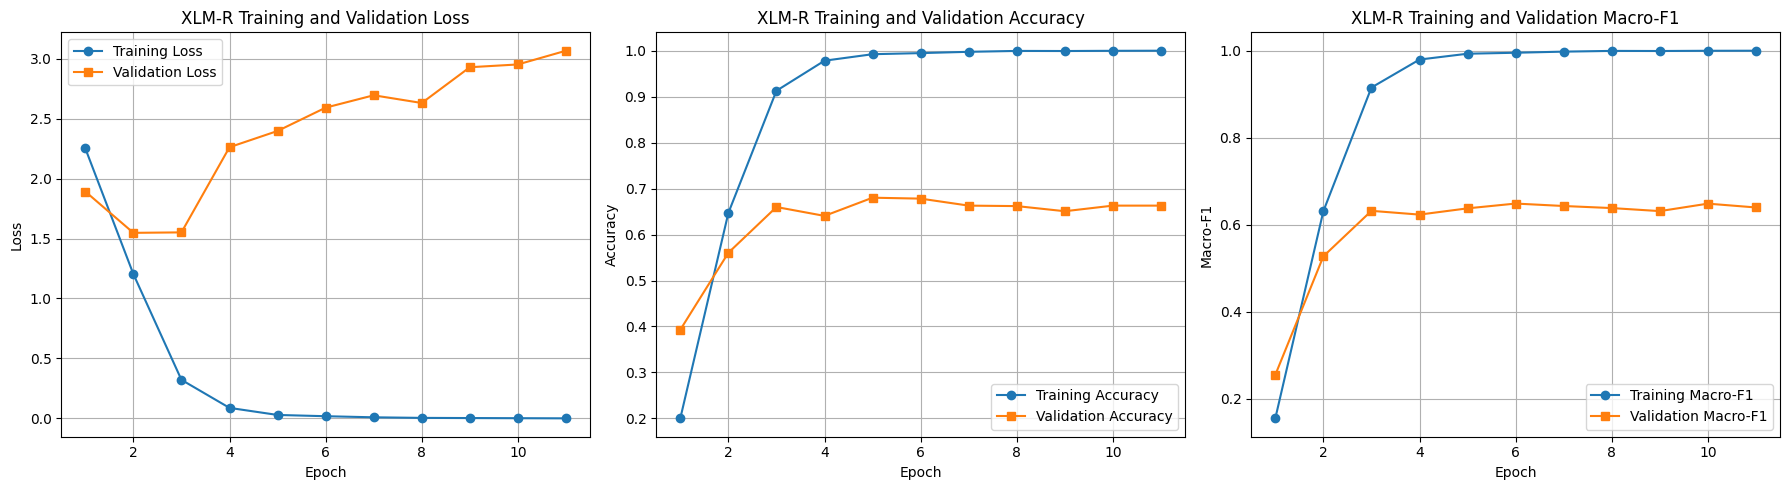

Best epoch: 6
Best validation Macro-F1: 0.6488


In [ ]:

# CELL 52: XLM-R TRAINING CURVES

import matplotlib.pyplot as plt

epochs_range = range(1, len(xlm_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Training and validation loss
axes[0].plot(
    epochs_range,
    xlm_history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    epochs_range,
    xlm_history["val_loss"],
    marker="s",
    label="Validation Loss"
)
axes[0].set_title("XLM-R Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Training and validation accuracy
axes[1].plot(
    epochs_range,
    xlm_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    epochs_range,
    xlm_history["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)
axes[1].set_title("XLM-R Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. Training and validation Macro-F1
axes[2].plot(
    epochs_range,
    xlm_history["train_macro_f1"],
    marker="o",
    label="Training Macro-F1"
)
axes[2].plot(
    epochs_range,
    xlm_history["val_macro_f1"],
    marker="s",
    label="Validation Macro-F1"
)
axes[2].set_title("XLM-R Training and Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("Best epoch:", best_xlm_epoch)
print("Best validation Macro-F1:", round(best_xlm_macro_f1, 4))


In [ ]:

# CELL 53: XLM-R FINAL TEST EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

xlm_model.eval()

xlm_test_predictions = []
xlm_test_labels = []

with torch.no_grad():

    for batch in xlm_test_loader:

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = xlm_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        xlm_test_predictions.extend(
            predictions.cpu().numpy()
        )

        xlm_test_labels.extend(
            labels.cpu().numpy()
        )

# Calculate final test metrics
xlm_test_metrics = {
    "accuracy": accuracy_score(
        xlm_test_labels,
        xlm_test_predictions
    ),
    "macro_precision": precision_score(
        xlm_test_labels,
        xlm_test_predictions,
        average="macro",
        zero_division=0
    ),
    "macro_recall": recall_score(
        xlm_test_labels,
        xlm_test_predictions,
        average="macro",
        zero_division=0
    ),
    "macro_f1": f1_score(
        xlm_test_labels,
        xlm_test_predictions,
        average="macro",
        zero_division=0
    ),
    "weighted_f1": f1_score(
        xlm_test_labels,
        xlm_test_predictions,
        average="weighted",
        zero_division=0
    )
}

print("=" * 75)
print("XLM-R FINAL TEST-SET PERFORMANCE")
print("=" * 75)

print("Test samples:", len(xlm_test_labels))
print("Best training epoch:", best_xlm_epoch)

for metric, value in xlm_test_metrics.items():
    print(f"{metric.replace('_', ' ').title():25s}: {value:.4f}")

print("\nXLM-R test evaluation completed.")


XLM-R FINAL TEST-SET PERFORMANCE
Test samples: 993
Best training epoch: 6
Accuracy                 : 0.6264
Macro Precision          : 0.6898
Macro Recall             : 0.6112
Macro F1                 : 0.6189
Weighted F1              : 0.6313

XLM-R test evaluation completed.


In [ ]:

# CELL 54: XLM-R CLASSIFICATION REPORT

from sklearn.metrics import classification_report
import pandas as pd

xlm_report = classification_report(
    xlm_test_labels,
    xlm_test_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

xlm_report_df = pd.DataFrame(xlm_report).transpose()

print("=" * 90)
print("XLM-R CLASSIFICATION REPORT")
print("=" * 90)

display(
    xlm_report_df.round(4)
)

print("\nMacro Average:")
print(xlm_report_df.loc["macro avg"].round(4))

print("\nWeighted Average:")
print(xlm_report_df.loc["weighted avg"].round(4))


XLM-R CLASSIFICATION REPORT


,precision,recall,f1-score,support
Cause-Effect,0.8359,0.8425,0.8392,127.0000
Component-Whole,0.6387,0.5891,0.6129,129.0000
Content-Container,0.7368,0.9180,0.8175,61.0000
Entity-Destination,0.9905,0.7704,0.8667,135.0000
Entity-Origin,0.6489,0.7093,0.6778,86.0000
Instrument-Agency,0.7925,0.6774,0.7304,62.0000
Member-Collection,0.9091,0.1818,0.3030,55.0000
Message-Topic,0.6509,0.5656,0.6053,122.0000
Other,0.3000,0.5433,0.3866,127.0000
Product-Producer,0.3944,0.3146,0.3500,89.0000



Macro Average:
precision      0.6898
recall         0.6112
f1-score       0.6189
support      993.0000
Name: macro avg, dtype: float64

Weighted Average:
precision      0.6795
recall         0.6264
f1-score       0.6313
support      993.0000
Name: weighted avg, dtype: float64


XLM-R CONFUSION MATRIX


,Cause-Effect,Component-Whole,Content-Container,Entity-Destination,Entity-Origin,Instrument-Agency,Member-Collection,Message-Topic,Other,Product-Producer
Cause-Effect,107,5,0,0,0,0,0,0,12,3
Component-Whole,0,76,0,0,1,0,0,23,18,11
Content-Container,5,0,56,0,0,0,0,0,0,0
Entity-Destination,4,0,10,104,5,0,0,0,12,0
Entity-Origin,5,0,0,0,61,0,0,0,20,0
Instrument-Agency,0,0,0,0,0,42,0,0,17,3
Member-Collection,0,17,0,0,18,0,10,2,0,8
Message-Topic,0,7,0,0,0,0,0,69,43,3
Other,0,14,10,1,3,11,0,4,69,15
Product-Producer,7,0,0,0,6,0,1,8,39,28


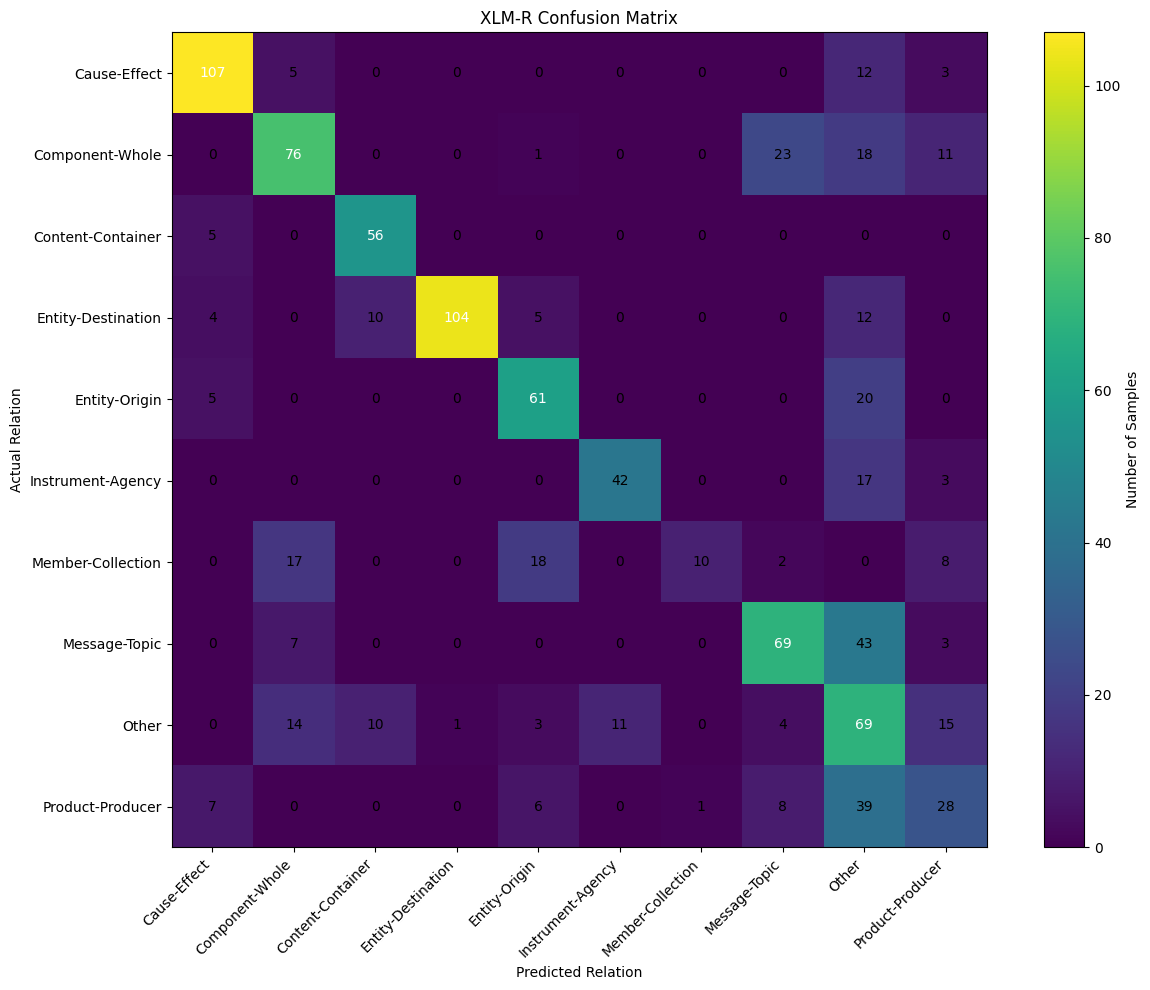

Correct predictions: 622
Incorrect predictions: 371
Total test samples: 993


In [ ]:

# CELL 55: XLM-R CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

xlm_cm = confusion_matrix(
    xlm_test_labels,
    xlm_test_predictions,
    labels=list(range(NUM_CLASSES))
)

class_names = list(label_encoder.classes_)

xlm_cm_df = pd.DataFrame(
    xlm_cm,
    index=class_names,
    columns=class_names
)

print("=" * 90)
print("XLM-R CONFUSION MATRIX")
print("=" * 90)

display(xlm_cm_df)

plt.figure(figsize=(13, 10))

plt.imshow(xlm_cm, interpolation="nearest")
plt.title("XLM-R Confusion Matrix")
plt.colorbar(label="Number of Samples")

tick_marks = np.arange(NUM_CLASSES)

plt.xticks(
    tick_marks,
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(tick_marks, class_names)

threshold = xlm_cm.max() / 2 if xlm_cm.max() > 0 else 0

for i in range(xlm_cm.shape[0]):
    for j in range(xlm_cm.shape[1]):
        plt.text(
            j,
            i,
            str(xlm_cm[i, j]),
            ha="center",
            va="center",
            color="white" if xlm_cm[i, j] > threshold else "black"
        )

plt.ylabel("Actual Relation")
plt.xlabel("Predicted Relation")
plt.tight_layout()
plt.show()

print("Correct predictions:", np.trace(xlm_cm))
print("Incorrect predictions:", xlm_cm.sum() - np.trace(xlm_cm))
print("Total test samples:", xlm_cm.sum())


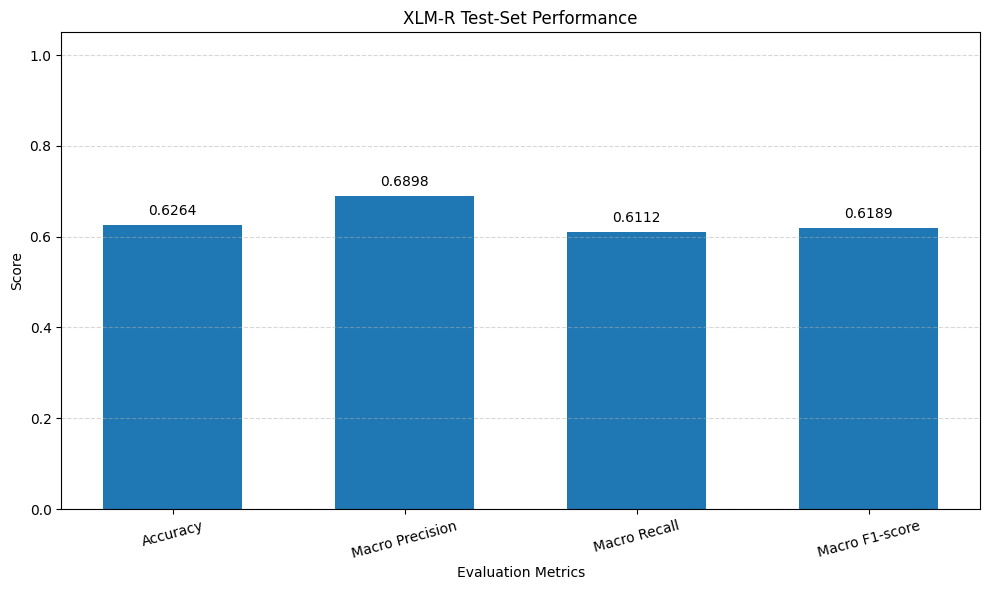

XLM-R TEST-SET PERFORMANCE SUMMARY
Accuracy            : 0.6264
Macro Precision     : 0.6898
Macro Recall        : 0.6112
Macro F1-score      : 0.6189


In [ ]:

# CELL 56: XLM-R PERFORMANCE METRICS GRAPH

import matplotlib.pyplot as plt
import numpy as np

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

metric_values = [
    xlm_test_metrics["accuracy"],
    xlm_test_metrics["macro_precision"],
    xlm_test_metrics["macro_recall"],
    xlm_test_metrics["macro_f1"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values,
    width=0.6
)

plt.title("XLM-R Test-Set Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

print("=" * 70)
print("XLM-R TEST-SET PERFORMANCE SUMMARY")
print("=" * 70)

for name, value in zip(metric_names, metric_values):
    print(f"{name:20s}: {value:.4f}")


In [ ]:

# CELL 57: SAVE XLM-R EXPERIMENTAL RESULTS

import os
import json
import torch

XLM_RESULTS_DIR = "/content/XLMR_Results"
os.makedirs(XLM_RESULTS_DIR, exist_ok=True)

# 1. Save trained model
torch.save(
    xlm_model.state_dict(),
    os.path.join(XLM_RESULTS_DIR, "best_xlmr_model.pth")
)

# 2. Save tokenizer
xlm_tokenizer.save_pretrained(
    os.path.join(XLM_RESULTS_DIR, "tokenizer")
)

# 3. Save evaluation metrics
with open(
    os.path.join(XLM_RESULTS_DIR, "test_metrics.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {key: float(value) for key, value in xlm_test_metrics.items()},
        file,
        indent=4
    )

# 4. Save classification report
xlm_report_df.to_csv(
    os.path.join(XLM_RESULTS_DIR, "classification_report.csv"),
    encoding="utf-8-sig"
)

# 5. Save confusion matrix
xlm_cm_df.to_csv(
    os.path.join(XLM_RESULTS_DIR, "confusion_matrix.csv"),
    encoding="utf-8-sig"
)

# 6. Save training history
pd.DataFrame(xlm_history).to_csv(
    os.path.join(XLM_RESULTS_DIR, "training_history.csv"),
    index=False
)

# 7. Save test predictions
xlm_predictions_df = pd.DataFrame({
    "Actual_Label": xlm_test_labels,
    "Predicted_Label": xlm_test_predictions,
    "Actual_Relation": [
        label_encoder.classes_[i] for i in xlm_test_labels
    ],
    "Predicted_Relation": [
        label_encoder.classes_[i] for i in xlm_test_predictions
    ]
})

xlm_predictions_df.to_csv(
    os.path.join(XLM_RESULTS_DIR, "test_predictions.csv"),
    index=False,
    encoding="utf-8-sig"
)

# 8. Save experiment configuration
xlm_config = {
    "model": XLM_MODEL_NAME,
    "number_of_classes": NUM_CLASSES,
    "class_names": list(label_encoder.classes_),
    "maximum_sequence_length": XLM_MAX_LENGTH,
    "batch_size": XLM_BATCH_SIZE,
    "learning_rate": XLM_LEARNING_RATE,
    "weight_decay": XLM_WEIGHT_DECAY,
    "maximum_epochs": XLM_EPOCHS,
    "early_stopping_patience": XLM_PATIENCE,
    "best_epoch": best_xlm_epoch,
    "best_validation_macro_f1": float(best_xlm_macro_f1),
    "completed_epochs": len(xlm_history["train_loss"]),
    "test_samples": len(xlm_test_labels),
    "random_seed": SEED
}

with open(
    os.path.join(XLM_RESULTS_DIR, "experiment_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(xlm_config, file, indent=4, ensure_ascii=False)

print("=" * 75)
print("XLM-R RESULTS SAVED SUCCESSFULLY")
print("=" * 75)

for file_name in sorted(os.listdir(XLM_RESULTS_DIR)):
    print(file_name)

print("\nResults directory:", XLM_RESULTS_DIR)


XLM-R RESULTS SAVED SUCCESSFULLY
best_xlmr_model.pth
classification_report.csv
confusion_matrix.csv
experiment_config.json
test_metrics.json
test_predictions.csv
tokenizer
training_history.csv

Results directory: /content/XLMR_Results


In [ ]:

# CELL 58: OVERALL PERFORMANCE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Actual test-set results from the three models
model_comparison_df = pd.DataFrame({
    "Model": ["BiLSTM", "AfroXLM-R", "XLM-R"],

    "Accuracy": [
        test_metrics["accuracy"],
        afro_test_metrics["accuracy"],
        xlm_test_metrics["accuracy"]
    ],

    "Macro Precision": [
        test_metrics["macro_precision"],
        afro_test_metrics["macro_precision"],
        xlm_test_metrics["macro_precision"]
    ],

    "Macro Recall": [
        test_metrics["macro_recall"],
        afro_test_metrics["macro_recall"],
        xlm_test_metrics["macro_recall"]
    ],

    "Macro F1-score": [
        test_metrics["macro_f1"],
        afro_test_metrics["macro_f1"],
        xlm_test_metrics["macro_f1"]
    ],

    "Weighted F1-score": [
        test_metrics["weighted_f1"],
        afro_test_metrics["weighted_f1"],
        xlm_test_metrics["weighted_f1"]
    ]
})

print("=" * 100)
print("COMPARATIVE PERFORMANCE OF THE THREE MODELS")
print("=" * 100)

display(
    model_comparison_df.set_index("Model").round(4)
)

# Grouped performance graph
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score",
    "Weighted F1-score"
]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

for i, row in model_comparison_df.iterrows():

    bars = ax.bar(
        x + (i - 1) * width,
        [row[m] for m in metrics],
        width,
        label=row["Model"]
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

ax.set_title("Performance Comparison: BiLSTM, AfroXLM-R and XLM-R")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Test Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylim(0, 1.15)
ax.legend(title="Models")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Rank models using Macro-F1
ranking_df = (
    model_comparison_df[
        ["Model", "Accuracy", "Macro F1-score"]
    ]
    .sort_values("Macro F1-score", ascending=False)
    .reset_index(drop=True)
)

ranking_df.insert(0, "Rank", range(1, len(ranking_df) + 1))

print("\nMODEL RANKING BASED ON TEST MACRO-F1")
display(ranking_df.round(4))


KeyError: 'accuracy'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Exact key names used by each model's metrics dictionary
KEYS = {
    "BiLSTM": {
        "Accuracy": "Accuracy",
        "Macro Precision": "Macro_Precision",
        "Macro Recall": "Macro_Recall",
        "Macro F1-score": "Macro_F1",
        "Weighted F1-score": "Weighted_F1",
    },
    "AfroXLM-R": {
        "Accuracy": "Accuracy",
        "Macro Precision": "Macro Precision",
        "Macro Recall": "Macro Recall",
        "Macro F1-score": "Macro F1-score",
        "Weighted F1-score": "Weighted F1-score",
    },
    "XLM-R": {
        "Accuracy": "accuracy",
        "Macro Precision": "macro_precision",
        "Macro Recall": "macro_recall",
        "Macro F1-score": "macro_f1",
        "Weighted F1-score": "weighted_f1",
    },
}

models = [("BiLSTM", test_metrics),
          ("AfroXLM-R", afro_test_metrics),
          ("XLM-R", xlm_test_metrics)]

metric_map = {m: m for m in KEYS["BiLSTM"]}   # column names for the table

data = {"Model": [name for name, _ in models]}
for column in metric_map:
    data[column] = [d[KEYS[name][column]] for name, d in models]

model_comparison_df = pd.DataFrame(data)
display(model_comparison_df.set_index("Model").round(4))

,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Weighted F1-score
Model,,,,,
BiLSTM,0.4542,0.4520,0.4550,0.4363,0.4565
AfroXLM-R,0.6354,0.6678,0.6323,0.6391,0.6469
XLM-R,0.6264,0.6898,0.6112,0.6189,0.6313


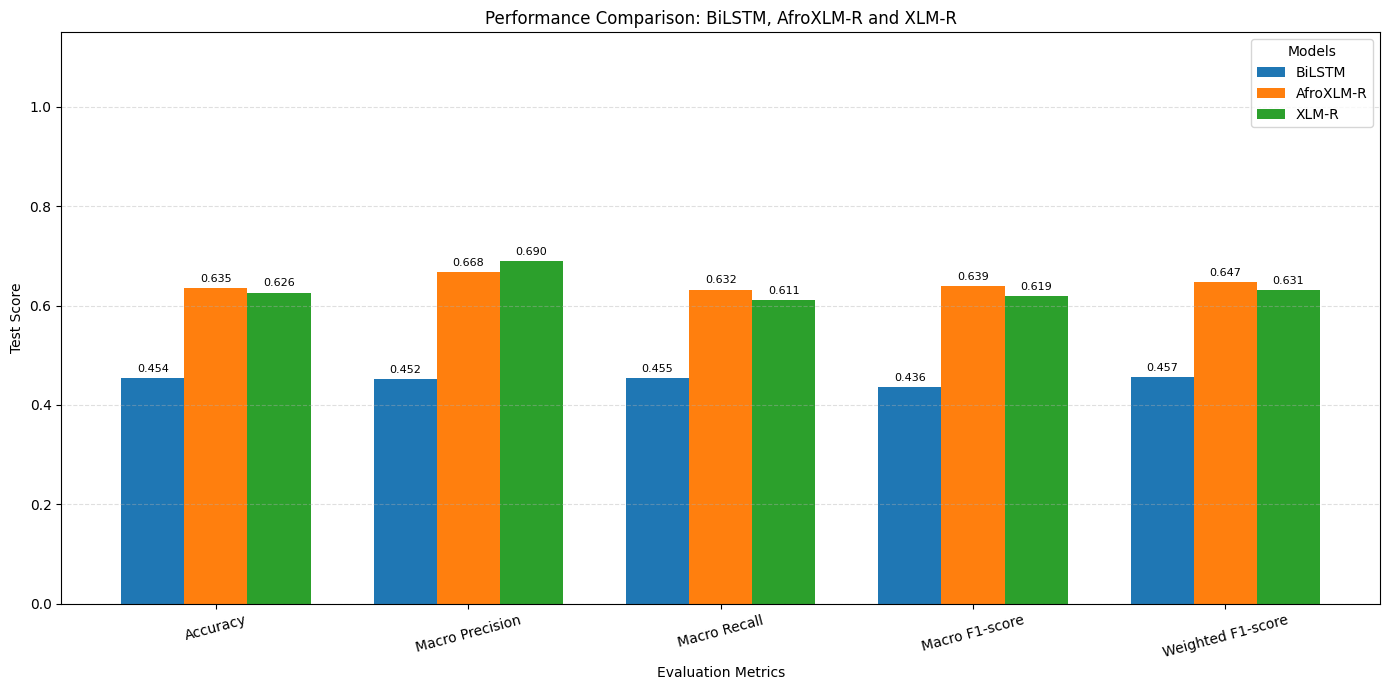

MODEL RANKING BASED ON TEST MACRO-F1


,Rank,Model,Accuracy,Macro F1-score
0,1,AfroXLM-R,0.6354,0.6391
1,2,XLM-R,0.6264,0.6189
2,3,BiLSTM,0.4542,0.4363


In [ ]:
metrics = list(metric_map.keys())
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

for i, row in model_comparison_df.iterrows():
    bars = ax.bar(x + (i - 1) * width,
                  [row[m] for m in metrics],
                  width, label=row["Model"])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

ax.set_title("Performance Comparison: BiLSTM, AfroXLM-R and XLM-R")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Test Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylim(0, 1.15)
ax.legend(title="Models")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

cols = ["Model", "Accuracy", "Macro F1-score"]
ranking_df = model_comparison_df[cols].sort_values("Macro F1-score", ascending=False)
ranking_df = ranking_df.reset_index(drop=True)
ranking_df.insert(0, "Rank", ranking_df.index + 1)

print("MODEL RANKING BASED ON TEST MACRO-F1")
display(ranking_df.round(4))

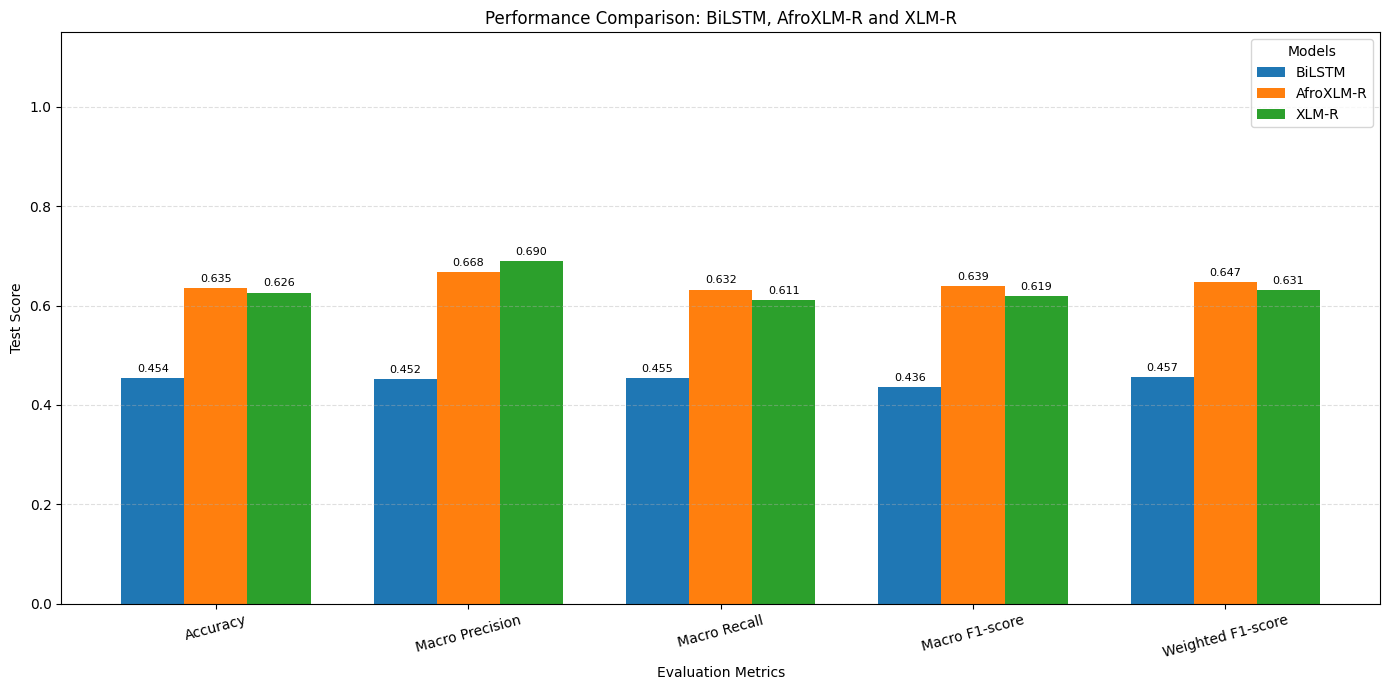

THREE-MODEL COMPARISON FILES SAVED
three_model_performance.csv
three_model_performance.png
three_model_ranking.csv

Saved directory: /content/Three_Model_Comparison


In [ ]:

# CELL 59: SAVE THREE-MODEL COMPARISON RESULTS

import os
import matplotlib.pyplot as plt

COMPARISON_DIR = "/content/Three_Model_Comparison"
os.makedirs(COMPARISON_DIR, exist_ok=True)

# Save comparison table
model_comparison_df.to_csv(
    os.path.join(COMPARISON_DIR, "three_model_performance.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Save model ranking
ranking_df.to_csv(
    os.path.join(COMPARISON_DIR, "three_model_ranking.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Save performance graph
plt.figure(figsize=(14, 7))

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score",
    "Weighted F1-score"
]

x = np.arange(len(metrics))
width = 0.25

for i, row in model_comparison_df.iterrows():

    bars = plt.bar(
        x + (i - 1) * width,
        [row[m] for m in metrics],
        width,
        label=row["Model"]
    )

    plt.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.title("Performance Comparison: BiLSTM, AfroXLM-R and XLM-R")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Test Score")
plt.xticks(x, metrics, rotation=15)
plt.ylim(0, 1.15)
plt.legend(title="Models")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    os.path.join(COMPARISON_DIR, "three_model_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 75)
print("THREE-MODEL COMPARISON FILES SAVED")
print("=" * 75)

for filename in sorted(os.listdir(COMPARISON_DIR)):
    print(filename)

print("\nSaved directory:", COMPARISON_DIR)


PER-CLASS F1-SCORE COMPARISON


,BiLSTM,AfroXLM-R,XLM-R
Relation,,,
Cause-Effect,0.7431,0.7970,0.8392
Component-Whole,0.3305,0.7595,0.6129
Content-Container,0.4335,0.8485,0.8175
Entity-Destination,0.6691,0.7607,0.8667
Entity-Origin,0.3429,0.6335,0.6778
Instrument-Agency,0.4605,0.6512,0.7304
Member-Collection,0.2745,0.4138,0.3030
Message-Topic,0.3568,0.6348,0.6053
Other,0.4202,0.3743,0.3866


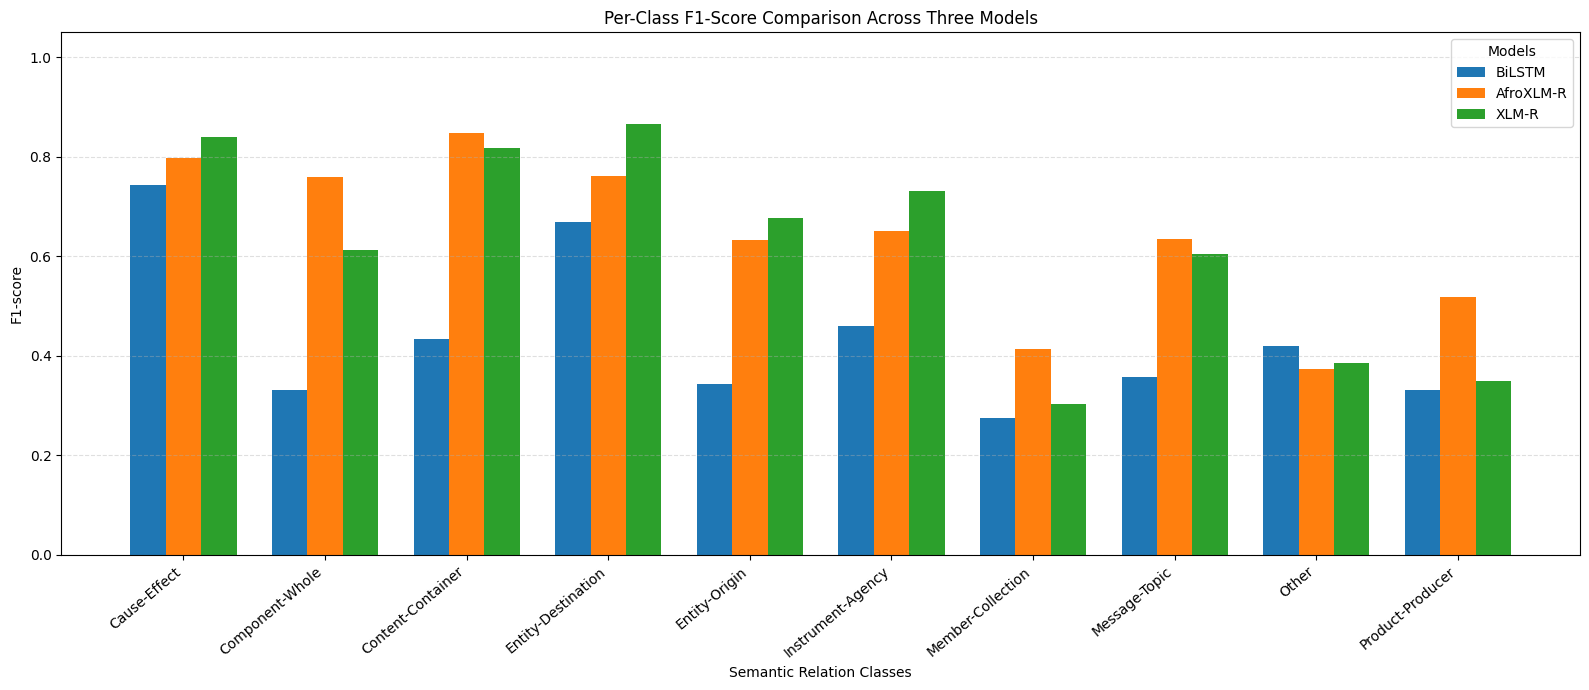


BEST MODEL FOR EACH RELATION


,Relation,Best_Model
0,Cause-Effect,XLM-R
1,Component-Whole,AfroXLM-R
2,Content-Container,AfroXLM-R
3,Entity-Destination,XLM-R
4,Entity-Origin,XLM-R
5,Instrument-Agency,XLM-R
6,Member-Collection,AfroXLM-R
7,Message-Topic,AfroXLM-R
8,Other,BiLSTM
9,Product-Producer,AfroXLM-R


In [ ]:

# CELL 60: PER-CLASS F1-SCORE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def calculate_class_f1(confusion_matrix):
    """Calculate per-class F1-scores from a confusion matrix."""

    true_positive = np.diag(confusion_matrix)
    actual_count = confusion_matrix.sum(axis=1)
    predicted_count = confusion_matrix.sum(axis=0)

    precision = np.divide(
        true_positive,
        predicted_count,
        out=np.zeros(NUM_CLASSES, dtype=float),
        where=predicted_count != 0
    )

    recall = np.divide(
        true_positive,
        actual_count,
        out=np.zeros(NUM_CLASSES, dtype=float),
        where=actual_count != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(NUM_CLASSES, dtype=float),
        where=(precision + recall) != 0
    )

    return f1

# Calculate per-class F1 for each model
bilstm_f1 = calculate_class_f1(cm)
afro_f1 = calculate_class_f1(afro_cm)
xlm_f1 = calculate_class_f1(xlm_cm)

class_names = list(label_encoder.classes_)

per_class_f1_df = pd.DataFrame({
    "Relation": class_names,
    "BiLSTM": bilstm_f1,
    "AfroXLM-R": afro_f1,
    "XLM-R": xlm_f1
})

print("=" * 100)
print("PER-CLASS F1-SCORE COMPARISON")
print("=" * 100)

display(
    per_class_f1_df.set_index("Relation").round(4)
)

# Plot comparison
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(16, 7))

for i, model in enumerate(["BiLSTM", "AfroXLM-R", "XLM-R"]):

    ax.bar(
        x + (i - 1) * width,
        per_class_f1_df[model],
        width,
        label=model
    )

ax.set_title("Per-Class F1-Score Comparison Across Three Models")
ax.set_xlabel("Semantic Relation Classes")
ax.set_ylabel("F1-score")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=40, ha="right")
ax.set_ylim(0, 1.05)
ax.legend(title="Models")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Identify the best model for each relation
per_class_f1_df["Best_Model"] = (
    per_class_f1_df[
        ["BiLSTM", "AfroXLM-R", "XLM-R"]
    ].idxmax(axis=1)
)

print("\nBEST MODEL FOR EACH RELATION")
display(
    per_class_f1_df[["Relation", "Best_Model"]]
)


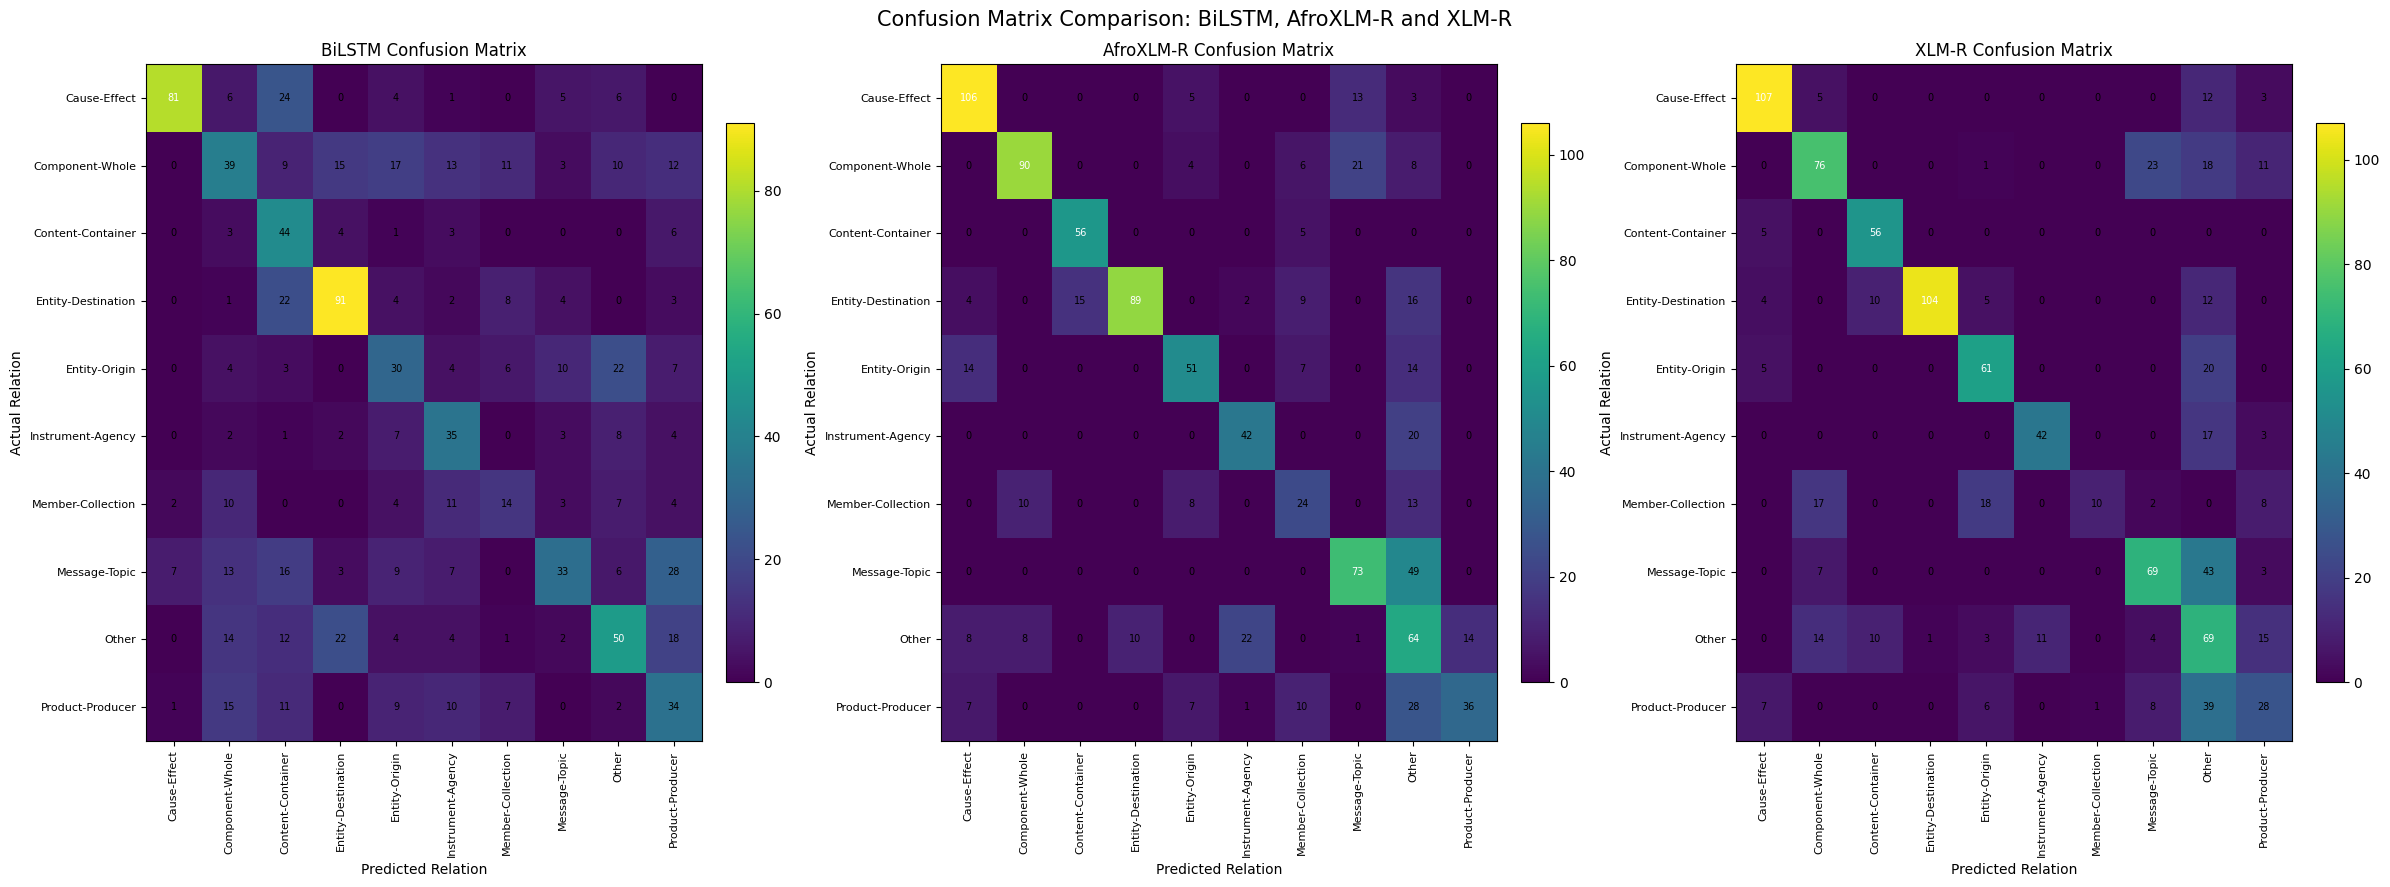


CONFUSION MATRIX SUMMARY


,Model,Correct_Predictions,Incorrect_Predictions,Total_Test_Samples
0,BiLSTM,451,542,993
1,AfroXLM-R,631,362,993
2,XLM-R,622,371,993


In [ ]:

# CELL 61: THREE-MODEL CONFUSION MATRIX COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_matrices = [
    ("BiLSTM", cm),
    ("AfroXLM-R", afro_cm),
    ("XLM-R", xlm_cm)
]

class_names = list(label_encoder.classes_)

fig, axes = plt.subplots(1, 3, figsize=(24, 9))

for ax, (model_name, matrix) in zip(axes, model_matrices):

    image = ax.imshow(
        matrix,
        interpolation="nearest",
        aspect="auto"
    )

    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted Relation")
    ax.set_ylabel("Actual Relation")

    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))

    ax.set_xticklabels(
        class_names,
        rotation=90,
        fontsize=8
    )

    ax.set_yticklabels(
        class_names,
        fontsize=8
    )

    threshold = matrix.max() / 2 if matrix.max() > 0 else 0

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j,
                i,
                str(matrix[i, j]),
                ha="center",
                va="center",
                fontsize=7,
                color="white" if matrix[i, j] > threshold else "black"
            )

    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(
    "Confusion Matrix Comparison: BiLSTM, AfroXLM-R and XLM-R",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Summary of correct and incorrect predictions
confusion_summary = pd.DataFrame({
    "Model": ["BiLSTM", "AfroXLM-R", "XLM-R"],
    "Correct_Predictions": [
        int(np.trace(cm)),
        int(np.trace(afro_cm)),
        int(np.trace(xlm_cm))
    ],
    "Incorrect_Predictions": [
        int(cm.sum() - np.trace(cm)),
        int(afro_cm.sum() - np.trace(afro_cm)),
        int(xlm_cm.sum() - np.trace(xlm_cm))
    ],
    "Total_Test_Samples": [
        int(cm.sum()),
        int(afro_cm.sum()),
        int(xlm_cm.sum())
    ]
})

print("\nCONFUSION MATRIX SUMMARY")
display(confusion_summary)


ACTUAL VS PREDICTED CLASS DISTRIBUTION

BiLSTM


,Actual_Count,Predicted_Count,Difference
Relation,,,
Cause-Effect,127,91,-36
Component-Whole,129,107,-22
Content-Container,61,142,81
Entity-Destination,135,137,2
Entity-Origin,86,89,3
Instrument-Agency,62,90,28
Member-Collection,55,47,-8
Message-Topic,122,63,-59
Other,127,111,-16



AfroXLM-R


,Actual_Count,Predicted_Count,Difference
Relation,,,
Cause-Effect,127,139,12
Component-Whole,129,108,-21
Content-Container,61,71,10
Entity-Destination,135,99,-36
Entity-Origin,86,75,-11
Instrument-Agency,62,67,5
Member-Collection,55,61,6
Message-Topic,122,108,-14
Other,127,215,88



XLM-R


,Actual_Count,Predicted_Count,Difference
Relation,,,
Cause-Effect,127,128,1
Component-Whole,129,119,-10
Content-Container,61,76,15
Entity-Destination,135,105,-30
Entity-Origin,86,94,8
Instrument-Agency,62,53,-9
Member-Collection,55,11,-44
Message-Topic,122,106,-16
Other,127,230,103


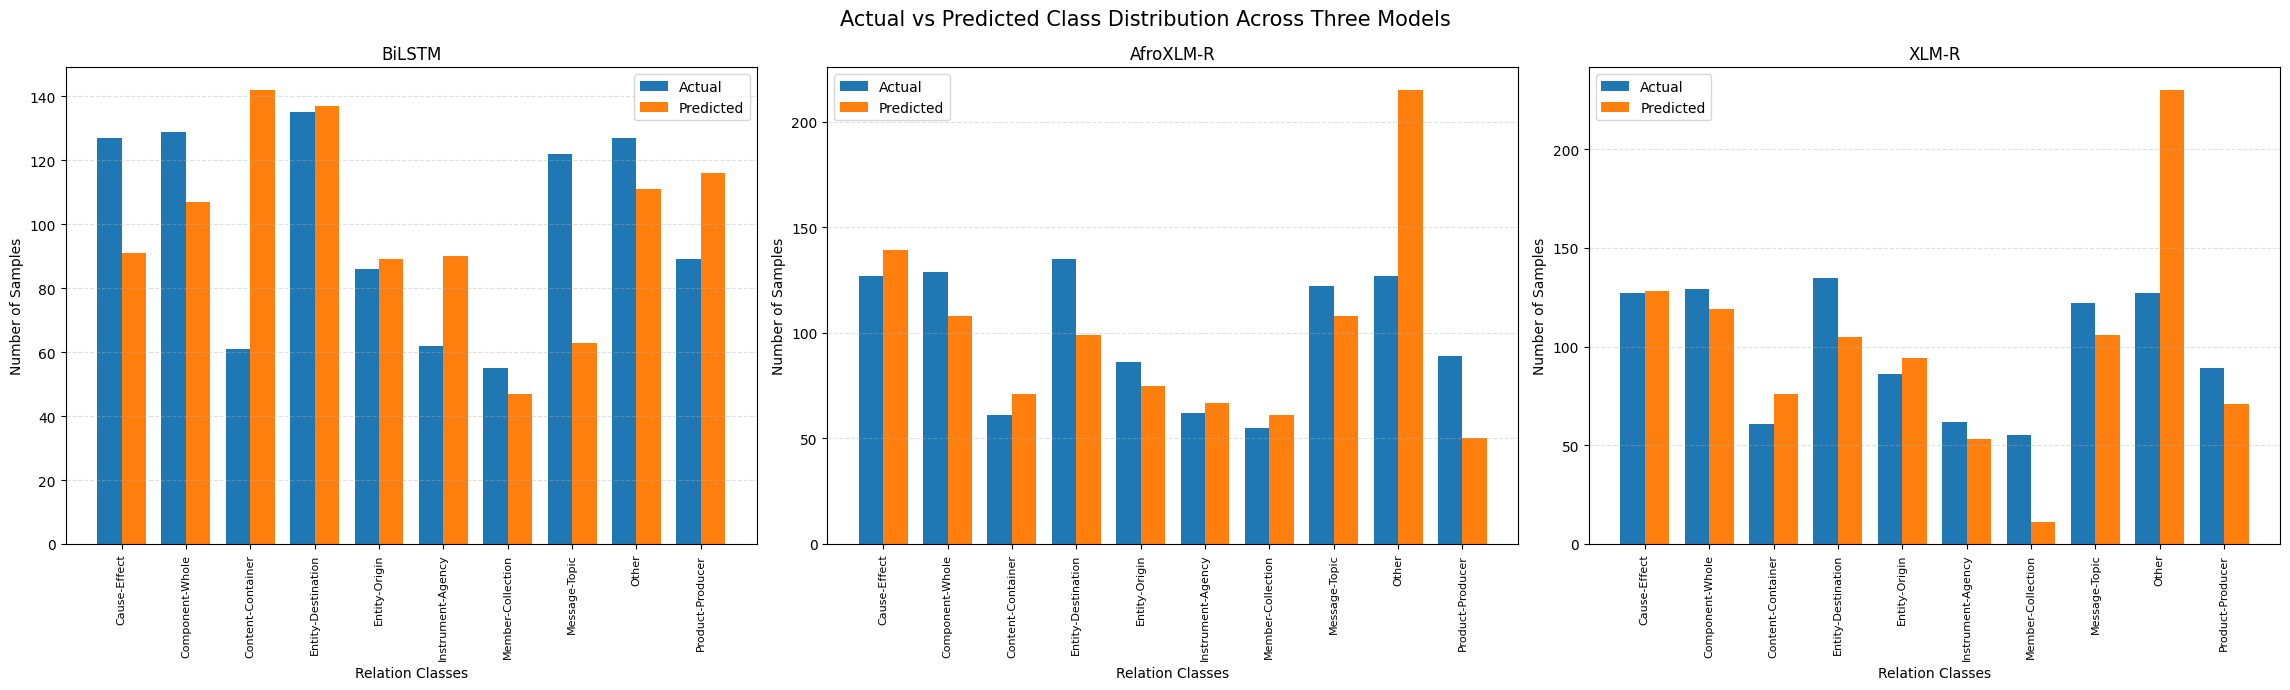


DISTRIBUTION DIFFERENCE SUMMARY


,Model,Total_Absolute_Distribution_Difference
0,AfroXLM-R,242
1,BiLSTM,282
2,XLM-R,254


In [ ]:

# CELL 62: ACTUAL VS PREDICTED CLASS DISTRIBUTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class_names = list(label_encoder.classes_)

model_matrices = {
    "BiLSTM": cm,
    "AfroXLM-R": afro_cm,
    "XLM-R": xlm_cm
}

# Actual distribution from the common test set
actual_counts = cm.sum(axis=1)

distribution_results = []

for model_name, matrix in model_matrices.items():

    predicted_counts = matrix.sum(axis=0)

    for i, relation in enumerate(class_names):

        distribution_results.append({
            "Model": model_name,
            "Relation": relation,
            "Actual_Count": int(actual_counts[i]),
            "Predicted_Count": int(predicted_counts[i]),
            "Difference": int(
                predicted_counts[i] - actual_counts[i]
            )
        })

distribution_df = pd.DataFrame(distribution_results)

print("=" * 100)
print("ACTUAL VS PREDICTED CLASS DISTRIBUTION")
print("=" * 100)

for model_name in model_matrices:

    print(f"\n{model_name}")
    display(
        distribution_df[
            distribution_df["Model"] == model_name
        ][
            ["Relation", "Actual_Count",
             "Predicted_Count", "Difference"]
        ].set_index("Relation")
    )

# Plot actual and predicted distributions
fig, axes = plt.subplots(1, 3, figsize=(23, 7))

for ax, (model_name, matrix) in zip(
    axes, model_matrices.items()
):

    predicted_counts = matrix.sum(axis=0)

    x = np.arange(NUM_CLASSES)
    width = 0.38

    ax.bar(
        x - width / 2,
        actual_counts,
        width,
        label="Actual"
    )

    ax.bar(
        x + width / 2,
        predicted_counts,
        width,
        label="Predicted"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Relation Classes")
    ax.set_ylabel("Number of Samples")
    ax.set_xticks(x)
    ax.set_xticklabels(
        class_names,
        rotation=90,
        fontsize=8
    )
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle(
    "Actual vs Predicted Class Distribution Across Three Models",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Calculate total absolute distribution difference
distribution_summary = (
    distribution_df
    .assign(
        Absolute_Difference=lambda df: df["Difference"].abs()
    )
    .groupby("Model")["Absolute_Difference"]
    .sum()
    .reset_index()
    .rename(columns={
        "Absolute_Difference":
        "Total_Absolute_Distribution_Difference"
    })
)

print("\nDISTRIBUTION DIFFERENCE SUMMARY")
display(distribution_summary)


CLASS DISTRIBUTION ERROR COMPARISON


,Model,MAE,RMSE,Total_Absolute_Error
0,BiLSTM,28.2,36.9703,282
1,AfroXLM-R,24.2,34.0940,242
2,XLM-R,25.4,38.0736,254


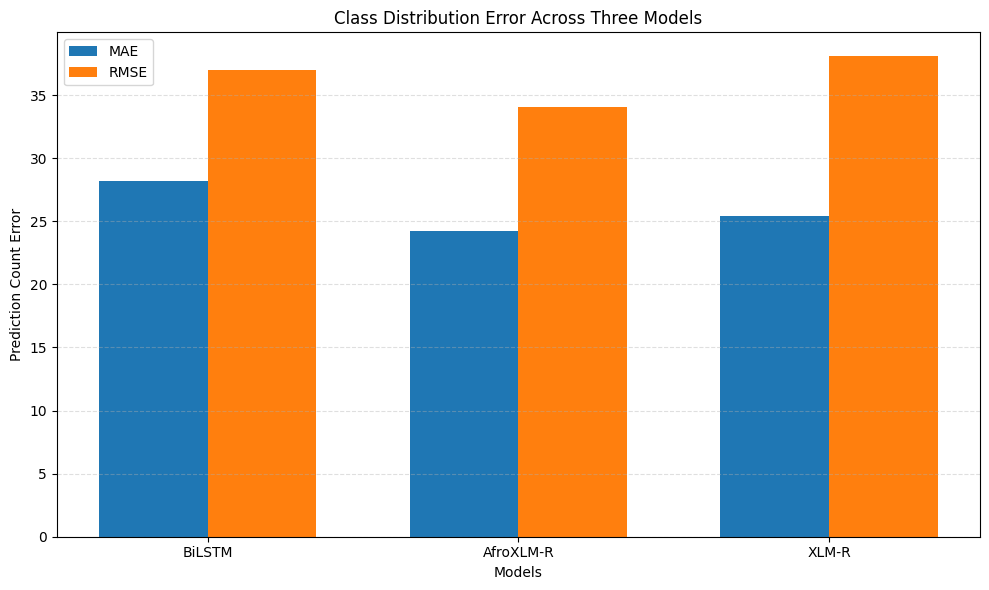


Interpretation:
Lower MAE and RMSE indicate closer predicted class counts.
These metrics measure distribution differences, not classification accuracy.


In [ ]:

# CELL 63: CLASS DISTRIBUTION ERROR ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

models = {
    "BiLSTM": cm,
    "AfroXLM-R": afro_cm,
    "XLM-R": xlm_cm
}

actual_counts = cm.sum(axis=1)
class_names = list(label_encoder.classes_)

error_results = []

for model_name, matrix in models.items():

    predicted_counts = matrix.sum(axis=0)

    differences = predicted_counts - actual_counts

    mae = np.mean(np.abs(differences))
    rmse = np.sqrt(np.mean(differences ** 2))
    total_absolute_error = np.sum(np.abs(differences))

    error_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "Total_Absolute_Error": total_absolute_error
    })

error_comparison_df = pd.DataFrame(error_results)

print("=" * 95)
print("CLASS DISTRIBUTION ERROR COMPARISON")
print("=" * 95)

display(error_comparison_df.round(4))

# Plot distribution errors
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(error_comparison_df))
width = 0.35

ax.bar(
    x - width / 2,
    error_comparison_df["MAE"],
    width,
    label="MAE"
)

ax.bar(
    x + width / 2,
    error_comparison_df["RMSE"],
    width,
    label="RMSE"
)

ax.set_title("Class Distribution Error Across Three Models")
ax.set_xlabel("Models")
ax.set_ylabel("Prediction Count Error")
ax.set_xticks(x)
ax.set_xticklabels(error_comparison_df["Model"])
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("Lower MAE and RMSE indicate closer predicted class counts.")
print("These metrics measure distribution differences, not classification accuracy.")


In [ ]:

# CELL 64: TOP MISCLASSIFIED RELATION PAIRS

import pandas as pd
import numpy as np

models = {
    "BiLSTM": cm,
    "AfroXLM-R": afro_cm,
    "XLM-R": xlm_cm
}

class_names = list(label_encoder.classes_)

all_misclassification_results = []

for model_name, matrix in models.items():

    error_pairs = []

    for actual_idx in range(NUM_CLASSES):
        for predicted_idx in range(NUM_CLASSES):

            if actual_idx != predicted_idx:

                count = int(matrix[actual_idx, predicted_idx])

                if count > 0:
                    error_pairs.append({
                        "Model": model_name,
                        "Actual_Relation": class_names[actual_idx],
                        "Predicted_Relation": class_names[predicted_idx],
                        "Error_Count": count
                    })

    model_errors_df = pd.DataFrame(error_pairs)

    model_errors_df = model_errors_df.sort_values(
        by="Error_Count",
        ascending=False
    ).reset_index(drop=True)

    all_misclassification_results.append(model_errors_df)

    print("\n" + "=" * 90)
    print(f"TOP 15 MISCLASSIFIED RELATION PAIRS: {model_name}")
    print("=" * 90)

    display(model_errors_df.head(15))

# Combine all model errors
combined_errors_df = pd.concat(
    all_misclassification_results,
    ignore_index=True
)

# Save the complete error analysis
combined_errors_df.to_csv(
    "/content/three_model_misclassification_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nComplete misclassification analysis saved.")



TOP 15 MISCLASSIFIED RELATION PAIRS: BiLSTM


,Model,Actual_Relation,Predicted_Relation,Error_Count
0,BiLSTM,Message-Topic,Product-Producer,28
1,BiLSTM,Cause-Effect,Content-Container,24
2,BiLSTM,Entity-Origin,Other,22
3,BiLSTM,Other,Entity-Destination,22
4,BiLSTM,Entity-Destination,Content-Container,22
5,BiLSTM,Other,Product-Producer,18
6,BiLSTM,Component-Whole,Entity-Origin,17
7,BiLSTM,Message-Topic,Content-Container,16
8,BiLSTM,Product-Producer,Component-Whole,15
9,BiLSTM,Component-Whole,Entity-Destination,15



TOP 15 MISCLASSIFIED RELATION PAIRS: AfroXLM-R


,Model,Actual_Relation,Predicted_Relation,Error_Count
0,AfroXLM-R,Message-Topic,Other,49
1,AfroXLM-R,Product-Producer,Other,28
2,AfroXLM-R,Other,Instrument-Agency,22
3,AfroXLM-R,Component-Whole,Message-Topic,21
4,AfroXLM-R,Instrument-Agency,Other,20
5,AfroXLM-R,Entity-Destination,Other,16
6,AfroXLM-R,Entity-Destination,Content-Container,15
7,AfroXLM-R,Entity-Origin,Cause-Effect,14
8,AfroXLM-R,Entity-Origin,Other,14
9,AfroXLM-R,Other,Product-Producer,14



TOP 15 MISCLASSIFIED RELATION PAIRS: XLM-R


,Model,Actual_Relation,Predicted_Relation,Error_Count
0,XLM-R,Message-Topic,Other,43
1,XLM-R,Product-Producer,Other,39
2,XLM-R,Component-Whole,Message-Topic,23
3,XLM-R,Entity-Origin,Other,20
4,XLM-R,Member-Collection,Entity-Origin,18
5,XLM-R,Component-Whole,Other,18
6,XLM-R,Instrument-Agency,Other,17
7,XLM-R,Member-Collection,Component-Whole,17
8,XLM-R,Other,Product-Producer,15
9,XLM-R,Other,Component-Whole,14



Complete misclassification analysis saved.


In [ ]:

# CELL 65: PREDICTION USING THE BEST MODEL (AfroXLM-R)

import torch
import pandas as pd
import numpy as np

# Use the restored best AfroXLM-R model
afro_model.eval()

def predict_amharic_relation(sentence):

    if not isinstance(sentence, str) or not sentence.strip():
        raise ValueError("Please enter a valid Amharic sentence.")

    # Tokenize input sentence
    inputs = afro_tokenizer(
        sentence,
        max_length=MAX_TOKEN_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    # Move inputs to the selected device
    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # Generate predictions
    afro_model.eval()

    with torch.no_grad():

        outputs = afro_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

    # Retrieve predicted relation
    predicted_relation = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = probabilities[0, predicted_class].item()

    # Prepare probability distribution for all classes
    probability_df = pd.DataFrame({
        "Relation": label_encoder.classes_,
        "Probability": probabilities[0].cpu().numpy()
    })

    probability_df["Confidence_Percentage"] = (
        probability_df["Probability"] * 100
    )

    probability_df = probability_df.sort_values(
        by="Probability",
        ascending=False
    ).reset_index(drop=True)

    return predicted_relation, confidence, probability_df


# Enter a new Amharic sentence
new_sentence = input("Enter an Amharic sentence: ").strip()

predicted_relation, confidence, probability_df = (
    predict_amharic_relation(new_sentence)
)

print("\n" + "=" * 75)
print("AMHARIC SEMANTIC RELATION PREDICTION")
print("=" * 75)

print("\nInput sentence:")
print(new_sentence)

print("\nPredicted semantic relation:")
print(predicted_relation)

print(f"\nPrediction confidence: {confidence * 100:.2f}%")

print("\nProbability distribution across all 10 classes:")
display(
    probability_df[
        ["Relation", "Confidence_Percentage"]
    ].round(2)
)


Enter an Amharic sentence: አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።

AMHARIC SEMANTIC RELATION PREDICTION

Input sentence:
አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።

Predicted semantic relation:
Other

Prediction confidence: 62.73%

Probability distribution across all 10 classes:


,Relation,Confidence_Percentage
0,Other,62.730000
1,Member-Collection,28.709999
2,Component-Whole,2.500000
3,Entity-Origin,2.260000
4,Product-Producer,1.830000
5,Cause-Effect,0.720000
6,Content-Container,0.340000
7,Entity-Destination,0.320000
8,Message-Topic,0.300000
9,Instrument-Agency,0.280000


In [ ]:
# CELL 65: PREDICTION USING THE BEST MODEL (AfroXLM-R)

import torch
import pandas as pd
import numpy as np

# Amharic test sentences with entity markers
amharic_sentences = [
    "<e1>አዲስ አበባ</e1> የ<e2>ኢትዮጵያ</e2> ዋና ከተማ ናት።",
    "<e1>ዝናብ</e1> የ<e2>ጎርፍ</e2> መከሰትን ሊያስከትል ይችላል።",
    "<e1>መኪና</e1> የ<e2>ሞተር</e2> ክፍል አለው።",
    "<e1>ወተት</e1> በ<e2>ጠርሙስ</e2> ውስጥ ተቀምጧል።",
    "<e1>ተማሪ</e1> ወደ <e2>ትምህርት ቤት</e2> ሄደ።"
]

afro_model.eval()

prediction_results = []

for sentence in amharic_sentences:

    inputs = afro_tokenizer(
        sentence,
        max_length=MAX_TOKEN_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = afro_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)

        predicted_class = torch.argmax(
            probabilities, dim=1
        ).item()

    predicted_relation = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = probabilities[0, predicted_class].item()

    prediction_results.append({
        "Amharic_Sentence": sentence,
        "Predicted_Relation": predicted_relation,
        "Confidence_Percentage": round(confidence * 100, 2)
    })

prediction_df = pd.DataFrame(prediction_results)

print("=" * 90)
print("AMHARIC SEMANTIC RELATION PREDICTION USING AFROXLM-R")
print("=" * 90)

display(prediction_df)

AMHARIC SEMANTIC RELATION PREDICTION USING AFROXLM-R


,Amharic_Sentence,Predicted_Relation,Confidence_Percentage
0,<e1>አዲስ አበባ</e1> የ<e2>ኢትዮጵያ</e2> ዋና ከተማ ናት።,Component-Whole,77.11
1,<e1>ዝናብ</e1> የ<e2>ጎርፍ</e2> መከሰትን ሊያስከትል ይችላል።,Cause-Effect,99.95
2,<e1>መኪና</e1> የ<e2>ሞተር</e2> ክፍል አለው።,Component-Whole,99.94
3,<e1>ወተት</e1> በ<e2>ጠርሙስ</e2> ውስጥ ተቀምጧል።,Content-Container,99.94
4,<e1>ተማሪ</e1> ወደ <e2>ትምህርት ቤት</e2> ሄደ።,Entity-Destination,99.95


In [ ]:
# CELL 66: UPLOAD THREE ANNOTATORS' FILES

from google.colab import files
import pandas as pd

print("=" * 80)
print("UPLOAD ANNOTATION FILES")
print("Select all three CSV files: Annotator1, Annotator2, and Annotator3")
print("=" * 80)

uploaded_files = files.upload()

# Check that exactly three files are uploaded
if len(uploaded_files) != 3:
    raise ValueError(
        f"Expected exactly 3 annotation files, but received {len(uploaded_files)}."
    )

# Load the three annotation files
annotator_datasets = {}

for i, (file_name, file_content) in enumerate(uploaded_files.items(), start=1):

    annotator_name = f"Annotator{i}"

    df = pd.read_csv(file_name, encoding="utf-8-sig")

    annotator_datasets[annotator_name] = df

    print("\n" + "=" * 80)
    print(annotator_name.upper())
    print("=" * 80)

    print("File:", file_name)
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst five records:")
    display(df.head())

    print("\nMissing values:")
    display(df.isnull().sum())

# Assign individual DataFrames
annotator1_df = annotator_datasets["Annotator1"]
annotator2_df = annotator_datasets["Annotator2"]
annotator3_df = annotator_datasets["Annotator3"]

print("\nAll three annotation files uploaded successfully.")

UPLOAD ANNOTATION FILES
Select all three CSV files: Annotator1, Annotator2, and Annotator3


Saving annotation1.csv to annotation1.csv
Saving annotation2.csv to annotation2.csv
Saving annotation3.csv to annotation3.csv

ANNOTATOR1
File: annotation1.csv
Dataset shape: (6580, 3)
Columns: ['id', 'sentence', 'relation']

First five records:


,id,sentence,relation
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,"Content-Container(e2,e1)"
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,"Product-Producer(e2,e1)"
2,3,<e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ...,"Member-Collection(e1,e2)"
3,4,<e1>ሰዎች</e1> ወደ <e2>መሃል ከተማ</e2> በመሄድ ላይ ናቸው፡፡፡,"Entity-Destination(e1,e2)"
4,5,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,"Message-Topic(e2,e1)"



Missing values:


,0
id,0
sentence,0
relation,0



ANNOTATOR2
File: annotation2.csv
Dataset shape: (6580, 3)
Columns: ['id', 'sentence', 'relation']

First five records:


... (4 outputs left out)

,id,sentence,relation
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,"Content-Container(e2,e1)"
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,"Product-Producer(e2,e1)"
2,3,<e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ...,"Member-Collection(e1,e2)"
3,4,<e1>ሰዎች</e1> ወደ <e2>መሃል ከተማ</e2> በመሄድ ላይ ናቸው፡፡፡,"Entity-Destination(e1,e2)"
4,5,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,"Message-Topic(e2,e1)"



Missing values:


,0
id,0
sentence,0
relation,0



All three annotation files uploaded successfully.


In [ ]:
# CELL 67: VERIFY ANNOTATOR RECORDS AND ALIGN LABELS

import pandas as pd
import re

# Expected 10 parent relation classes
expected_relations = [
    "Cause-Effect",
    "Component-Whole",
    "Content-Container",
    "Entity-Destination",
    "Entity-Origin",
    "Instrument-Agency",
    "Member-Collection",
    "Message-Topic",
    "Other",
    "Product-Producer"
]

# Work with copies to preserve original annotation data
a1 = annotator1_df.copy()
a2 = annotator2_df.copy()
a3 = annotator3_df.copy()

annotators = {
    "Annotator1": a1,
    "Annotator2": a2,
    "Annotator3": a3
}

# 1. Check required columns and duplicate IDs
for name, df in annotators.items():

    required_columns = {"id", "sentence", "relation"}

    if not required_columns.issubset(df.columns):
        raise ValueError(f"{name} is missing required columns.")

    if df["id"].duplicated().any():
        raise ValueError(f"{name} contains duplicate IDs.")

    if df[["id", "sentence", "relation"]].isnull().any().any():
        raise ValueError(f"{name} contains missing values.")

# 2. Verify that all annotators have the same IDs
reference_ids = set(a1["id"])

for name, df in annotators.items():

    current_ids = set(df["id"])

    if current_ids != reference_ids:
        raise ValueError(
            f"Record IDs do not match between Annotator1 and {name}."
        )

# 3. Align records using ID
combined_annotations = a1[
    ["id", "sentence", "relation"]
].rename(columns={"relation": "Annotator1"})

for name, df in [
    ("Annotator2", a2),
    ("Annotator3", a3)
]:

    combined_annotations = combined_annotations.merge(
        df[["id", "sentence", "relation"]].rename(
            columns={
                "sentence": f"sentence_{name}",
                "relation": name
            }
        ),
        on="id",
        how="inner",
        validate="one_to_one"
    )

# 4. Check sentence consistency
for name in ["Annotator2", "Annotator3"]:

    mismatch = (
        combined_annotations["sentence"]
        != combined_annotations[f"sentence_{name}"]
    )

    print(f"{name} sentence mismatches:", mismatch.sum())

    if mismatch.any():
        raise ValueError(
            f"Sentence mismatch detected in {name}. "
            "Please inspect the records before continuing."
        )

# Remove additional sentence columns after successful verification
combined_annotations = combined_annotations.drop(
    columns=["sentence_Annotator2", "sentence_Annotator3"]
)

# 5. Normalize directional labels to parent relation classes
def normalize_relation(label):

    label = str(label).strip()

    # Remove directional suffix, e.g. (e1,e2) or (e2,e1)
    label = re.sub(r"\(e[12],e[12]\)$", "", label)

    return label.strip()

for col in ["Annotator1", "Annotator2", "Annotator3"]:

    combined_annotations[col] = (
        combined_annotations[col].apply(normalize_relation)
    )

# 6. Check for unexpected relation labels
for col in ["Annotator1", "Annotator2", "Annotator3"]:

    unexpected = sorted(
        set(combined_annotations[col].unique())
        - set(expected_relations)
    )

    if unexpected:
        raise ValueError(
            f"Unexpected labels in {col}: {unexpected}"
        )

# 7. Display verification results
print("\n" + "=" * 80)
print("THREE-ANNOTATOR DATA ALIGNMENT REPORT")
print("=" * 80)

print("Total aligned records:", len(combined_annotations))
print("Unique record IDs:", combined_annotations["id"].nunique())
print("Sentence mismatches: 0")
print("Unexpected relation labels: 0")

print("\nAnnotation columns:")
print(combined_annotations.columns.tolist())

print("\nFirst 10 aligned annotations:")
display(combined_annotations.head(10))

print("\nRelation distribution by annotator:")

for col in ["Annotator1", "Annotator2", "Annotator3"]:

    print(f"\n{col}")
    display(
        combined_annotations[col]
        .value_counts()
        .reindex(expected_relations, fill_value=0)
        .rename("Count")
        .to_frame()
    )

# 8. Save aligned annotation data
combined_annotations.to_csv(
    "/content/Aligned_Three_Annotators.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAligned annotation file saved successfully.")

Annotator2 sentence mismatches: 0
Annotator3 sentence mismatches: 0

THREE-ANNOTATOR DATA ALIGNMENT REPORT
Total aligned records: 6580
Unique record IDs: 6580
Sentence mismatches: 0
Unexpected relation labels: 0

Annotation columns:
['id', 'sentence', 'Annotator1', 'Annotator2', 'Annotator3']

First 10 aligned annotations:


,id,sentence,Annotator1,Annotator2,Annotator3
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,Content-Container,Content-Container,Content-Container
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,Product-Producer,Product-Producer,Product-Producer
2,3,<e1>የተማሪ</e1> <e2>ማህበሩ</e2> በኒው ዮርክ ስቴት ዩኒቨርሲቲ...,Member-Collection,Member-Collection,Member-Collection
3,4,<e1>ሰዎች</e1> ወደ <e2>መሃል ከተማ</e2> በመሄድ ላይ ናቸው፡፡፡,Entity-Destination,Entity-Destination,Entity-Destination
4,5,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,Message-Topic,Component-Whole,Message-Topic
5,6,<e1>ፍንዳታ</e1> የተከሰተው በውሃ መዶሻ <e2>ግፊት</e2> ምክንያ...,Cause-Effect,Cause-Effect,Cause-Effect
6,7,የንግድ <e1>ኔትወርኮችም</e1> እንኳ ወደ ከፍተኛ ጥራት ወዳለው <e2...,Component-Whole,Instrument-Agency,Instrument-Agency
7,8,ስለ <e1>ሂሳቡ</e1> እንዲያስታውሱ እና ደረሰኝ እንዳላቸው ለማረጋገጥ...,Message-Topic,Message-Topic,Message-Topic
8,9,<e1>የፋብሪካው</e1> ምርቶች የአበባ ዱባዎችን ፣ የፊንላንድ ዶሮ-ዊስ...,Product-Producer,Product-Producer,Product-Producer
9,10,የደራሲው መጽሐፎቹ እና <e1>መጣጥፎች</e1> ዘመናዊውን <e2>ታሪክ</...,Cause-Effect,Cause-Effect,Cause-Effect



Relation distribution by annotator:

Annotator1


,Count
Annotator1,
Cause-Effect,788
Component-Whole,605
Content-Container,493
Entity-Destination,940
Entity-Origin,561
Instrument-Agency,412
Member-Collection,409
Message-Topic,794
Other,1031



Annotator2


,Count
Annotator2,
Cause-Effect,790
Component-Whole,605
Content-Container,493
Entity-Destination,939
Entity-Origin,560
Instrument-Agency,413
Member-Collection,409
Message-Topic,793
Other,1031



Annotator3


,Count
Annotator3,
Cause-Effect,790
Component-Whole,606
Content-Container,494
Entity-Destination,939
Entity-Origin,561
Instrument-Agency,411
Member-Collection,409
Message-Topic,794
Other,1031



Aligned annotation file saved successfully.


In [ ]:
# CELL 68: THREE-ANNOTATOR AGREEMENT AND MAJORITY VOTING

import pandas as pd
import numpy as np

annotator_columns = [
    "Annotator1",
    "Annotator2",
    "Annotator3"
]

# Verify the aligned annotation dataset
if "combined_annotations" not in globals():
    raise ValueError("Please run Cell 67 first.")

# 1. Count agreement for every record
agreement_counts = combined_annotations[
    annotator_columns
].apply(lambda row: row.value_counts(), axis=1)

# Number of matching annotations for each record
combined_annotations["Agreement_Count"] = (
    combined_annotations[annotator_columns]
    .apply(lambda row: row.value_counts().max(), axis=1)
)

# 2. Identify agreement type
def classify_agreement(row):

    unique_labels = row[annotator_columns].nunique()

    if unique_labels == 1:
        return "Unanimous Agreement"

    elif unique_labels == 2:
        return "Majority Agreement"

    else:
        return "Complete Disagreement"

combined_annotations["Agreement_Type"] = (
    combined_annotations.apply(classify_agreement, axis=1)
)

# 3. Determine majority-voting label
def majority_vote(row):

    counts = row[annotator_columns].value_counts()

    # With three annotators, a majority must have at least two votes
    majority_labels = counts[counts >= 2]

    if len(majority_labels) == 1:
        return majority_labels.index[0]

    return "No Majority"

combined_annotations["Majority_Label"] = (
    combined_annotations.apply(majority_vote, axis=1)
)

# 4. Calculate agreement summary
agreement_summary = (
    combined_annotations["Agreement_Type"]
    .value_counts()
    .reindex(
        [
            "Unanimous Agreement",
            "Majority Agreement",
            "Complete Disagreement"
        ],
        fill_value=0
    )
    .rename_axis("Agreement_Type")
    .reset_index(name="Number_of_Records")
)

agreement_summary["Percentage"] = (
    agreement_summary["Number_of_Records"]
    / len(combined_annotations) * 100
).round(2)

print("=" * 85)
print("THREE-ANNOTATOR AGREEMENT SUMMARY")
print("=" * 85)

display(agreement_summary)

# 5. Calculate Fleiss' Kappa manually
categories = sorted(
    set(
        combined_annotations[annotator_columns]
        .values.flatten()
    )
)

N = len(combined_annotations)
n = len(annotator_columns)
k = len(categories)

# Number of annotators assigning each category to each record
category_counts = np.zeros((N, k), dtype=int)

for j, category in enumerate(categories):

    category_counts[:, j] = (
        combined_annotations[annotator_columns]
        .eq(category)
        .sum(axis=1)
        .values
    )

# Agreement for each record
P_i = (
    (category_counts * (category_counts - 1)).sum(axis=1)
    / (n * (n - 1))
)

P_bar = P_i.mean()

# Overall proportion of assignments per category
p_j = category_counts.sum(axis=0) / (N * n)

# Expected agreement by chance
P_e = np.sum(p_j ** 2)

# Fleiss' Kappa
if np.isclose(1 - P_e, 0):
    fleiss_kappa = np.nan
else:
    fleiss_kappa = (P_bar - P_e) / (1 - P_e)

print("\n" + "=" * 85)
print("FLEISS' KAPPA")
print("=" * 85)

print("Number of records:", N)
print("Number of annotators:", n)
print("Number of relation categories:", k)
print("Observed agreement:", round(P_bar, 4))
print("Expected agreement:", round(P_e, 4))
print("Fleiss' Kappa:", round(fleiss_kappa, 4))

# 6. Majority-voting label distribution
print("\n" + "=" * 85)
print("MAJORITY-VOTING LABEL DISTRIBUTION")
print("=" * 85)

majority_distribution = (
    combined_annotations["Majority_Label"]
    .value_counts()
    .reindex(categories, fill_value=0)
    .rename_axis("Relation")
    .reset_index(name="Count")
)

majority_distribution["Percentage"] = (
    majority_distribution["Count"] / N * 100
).round(2)

display(majority_distribution)

# 7. Save annotated dataset and reports
combined_annotations.to_csv(
    "/content/Three_Annotators_Majority_Voting.csv",
    index=False,
    encoding="utf-8-sig"
)

agreement_summary.to_csv(
    "/content/Three_Annotators_Agreement_Summary.csv",
    index=False,
    encoding="utf-8-sig"
)

majority_distribution.to_csv(
    "/content/Majority_Voting_Relation_Distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAll agreement and majority-voting files saved successfully.")

THREE-ANNOTATOR AGREEMENT SUMMARY


,Agreement_Type,Number_of_Records,Percentage
0,Unanimous Agreement,6565,99.77
1,Majority Agreement,15,0.23
2,Complete Disagreement,0,0.00



FLEISS' KAPPA
Number of records: 6580
Number of annotators: 3
Number of relation categories: 10
Observed agreement: 0.9985
Expected agreement: 0.1099
Fleiss' Kappa: 0.9983

MAJORITY-VOTING LABEL DISTRIBUTION


,Relation,Count,Percentage
0,Cause-Effect,790,12.01
1,Component-Whole,601,9.13
2,Content-Container,493,7.49
3,Entity-Destination,940,14.29
4,Entity-Origin,561,8.53
5,Instrument-Agency,413,6.28
6,Member-Collection,409,6.22
7,Message-Topic,795,12.08
8,Other,1031,15.67
9,Product-Producer,547,8.31



All agreement and majority-voting files saved successfully.


In [ ]:
# CELL 69: DETAILED ANALYSIS OF ANNOTATOR DISAGREEMENTS

import pandas as pd

annotator_columns = [
    "Annotator1",
    "Annotator2",
    "Annotator3"
]

# Select records where annotators did not unanimously agree
disagreement_df = combined_annotations[
    combined_annotations["Agreement_Type"] != "Unanimous Agreement"
].copy()

# Identify the annotator with the different label
def identify_disagreement(row):

    labels = row[annotator_columns].to_dict()

    for annotator, label in labels.items():

        other_labels = [
            value for name, value in labels.items()
            if name != annotator
        ]

        if other_labels[0] == other_labels[1] and label != other_labels[0]:

            return annotator

    return "No unique minority annotator"

disagreement_df["Disagreeing_Annotator"] = (
    disagreement_df.apply(identify_disagreement, axis=1)
)

# Identify the majority label
disagreement_df["Final_Majority_Label"] = (
    disagreement_df["Majority_Label"]
)

# Select columns for detailed inspection
disagreement_report = disagreement_df[
    [
        "id",
        "sentence",
        "Annotator1",
        "Annotator2",
        "Annotator3",
        "Disagreeing_Annotator",
        "Final_Majority_Label"
    ]
].copy()

print("=" * 100)
print("DETAILED THREE-ANNOTATOR DISAGREEMENT ANALYSIS")
print("=" * 100)

print("Total disagreements:", len(disagreement_report))

print("\nDisagreement records:")
display(disagreement_report)

# Count disagreements by annotator
print("\n" + "=" * 100)
print("DISAGREEMENTS BY ANNOTATOR")
print("=" * 100)

disagreement_by_annotator = (
    disagreement_report["Disagreeing_Annotator"]
    .value_counts()
    .reindex(annotator_columns, fill_value=0)
    .rename_axis("Annotator")
    .reset_index(name="Disagreement_Count")
)

display(disagreement_by_annotator)

# Save detailed disagreement report
disagreement_report.to_csv(
    "/content/Three_Annotators_Disagreement_Analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

disagreement_by_annotator.to_csv(
    "/content/Disagreements_By_Annotator.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDisagreement analysis files saved successfully.")

DETAILED THREE-ANNOTATOR DISAGREEMENT ANALYSIS
Total disagreements: 15

Disagreement records:


,id,sentence,Annotator1,Annotator2,Annotator3,Disagreeing_Annotator,Final_Majority_Label
4,5,የሽልማት ኮሚቴው የሽልማቱን <e1>ምክንያቶች</e1> የሚያብራራ ህጋዊ <...,Message-Topic,Component-Whole,Message-Topic,Annotator2,Message-Topic
6,7,የንግድ <e1>ኔትወርኮችም</e1> እንኳ ወደ ከፍተኛ ጥራት ወዳለው <e2...,Component-Whole,Instrument-Agency,Instrument-Agency,Annotator1,Instrument-Agency
14,15,በመኝታ ቤቶቹ ውስጥ በነበረ <e1>ሻጋታ</e1> ምክንያት የደረት ህመም ...,Component-Whole,Cause-Effect,Cause-Effect,Annotator1,Cause-Effect
37,38,ከሰሜን ፓርክ የሚገኘው <e1>ቀይቀበሮ</e1> ወደተተካው <e2>ፓርክ</...,Entity-Destination,Component-Whole,Entity-Destination,Annotator2,Entity-Destination
40,41,ይህ የተፈጥሮ ስጦታ <e1>ፍቅር</e1> ከአንድ ሺህ ዓመታት በላይ በተነ...,Message-Topic,Component-Whole,Message-Topic,Annotator2,Message-Topic
48,49,<e1>የጉዳቱ</e1> ታሪካዊ እይታ በ 1693 የካታኒያ <e2>የመሬት መ...,Component-Whole,Cause-Effect,Cause-Effect,Annotator1,Cause-Effect
58,59,አበቦች ጥሩ ናቸው ፣ ግን በጣም ረጅም ጊዜ አይቆዩም እና በፍራፍሬ <e1...,Component-Whole,Component-Whole,Content-Container,Annotator3,Component-Whole
63,64,ከአንድ ምዕተ ዓመት በፊት በጣሊያን ተራሮች ውስጥ <e1>የቼዝ</e1> <...,Entity-Origin,Component-Whole,Entity-Origin,Annotator2,Entity-Origin
70,71,በቃለ-መጠይቅ ውስጥ በጣም ካልተወሳሰቡት <e1>ጥያቄዎች</e1> መካከል ...,Component-Whole,Message-Topic,Message-Topic,Annotator1,Message-Topic
125,126,የኢትዮጵያ ታሪካዊ ሀብቶች <e1>ዳይሬክተር</e1> የሆኑት ዶ/ር ግርማ ...,Product-Producer,Product-Producer,Component-Whole,Annotator3,Product-Producer



DISAGREEMENTS BY ANNOTATOR


,Annotator,Disagreement_Count
0,Annotator1,4
1,Annotator2,4
2,Annotator3,7



Disagreement analysis files saved successfully.


In [ ]:
# CELL 70: CREATE FINAL GOLD-STANDARD DATASET

import pandas as pd

annotator_columns = [
    "Annotator1",
    "Annotator2",
    "Annotator3"
]

# Copy the aligned annotations
gold_standard_df = combined_annotations.copy()

# Ensure every record has a majority label
if (gold_standard_df["Majority_Label"] == "No Majority").any():
    raise ValueError("Some records do not have a majority label.")

# Create final reference label
gold_standard_df["Gold_Label"] = (
    gold_standard_df["Majority_Label"]
)

# Verify majority voting
gold_standard_df["Majority_Verification"] = (
    gold_standard_df.apply(
        lambda row: (
            row[annotator_columns]
            .eq(row["Gold_Label"])
            .sum()
        ),
        axis=1
    )
)

if not (gold_standard_df["Majority_Verification"] >= 2).all():
    raise ValueError("Majority voting verification failed.")

# Final dataset columns
final_gold_dataset = gold_standard_df[
    [
        "id",
        "sentence",
        "Annotator1",
        "Annotator2",
        "Annotator3",
        "Agreement_Type",
        "Gold_Label"
    ]
].copy()

# Summary
print("=" * 90)
print("FINAL GOLD-STANDARD ANNOTATION DATASET")
print("=" * 90)

print("Total records:", len(final_gold_dataset))
print("Unanimous records:",
      (final_gold_dataset["Agreement_Type"] == "Unanimous Agreement").sum())

print("Majority-agreement records:",
      (final_gold_dataset["Agreement_Type"] == "Majority Agreement").sum())

print("Missing gold labels:",
      final_gold_dataset["Gold_Label"].isna().sum())

print("\nGold-standard relation distribution:")

gold_distribution = (
    final_gold_dataset["Gold_Label"]
    .value_counts()
    .rename_axis("Relation")
    .reset_index(name="Count")
)

gold_distribution["Percentage"] = (
    gold_distribution["Count"]
    / len(final_gold_dataset) * 100
).round(2)

display(gold_distribution)

# Save final gold-standard dataset
gold_path = "/content/Final_Gold_Standard_Amharic_Dataset.csv"

final_gold_dataset.to_csv(
    gold_path,
    index=False,
    encoding="utf-8-sig"
)

gold_distribution.to_csv(
    "/content/Gold_Standard_Relation_Distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal gold-standard dataset saved:", gold_path)

FINAL GOLD-STANDARD ANNOTATION DATASET
Total records: 6580
Unanimous records: 6565
Majority-agreement records: 15
Missing gold labels: 0

Gold-standard relation distribution:


,Relation,Count,Percentage
0,Other,1031,15.67
1,Entity-Destination,940,14.29
2,Message-Topic,795,12.08
3,Cause-Effect,790,12.01
4,Component-Whole,601,9.13
5,Entity-Origin,561,8.53
6,Product-Producer,547,8.31
7,Content-Container,493,7.49
8,Instrument-Agency,413,6.28
9,Member-Collection,409,6.22



Final gold-standard dataset saved: /content/Final_Gold_Standard_Amharic_Dataset.csv


In [ ]:
# CELL 71: INSPECT DATASET AND TEST-SET VARIABLES

import pandas as pd
import numpy as np

print("=" * 90)
print("EXISTING DATASET AND TEST-SET VARIABLE INSPECTION")
print("=" * 90)

# Inspect all existing DataFrames
print("\n1. EXISTING DATAFRAMES")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        print("First 2 records:")
        display(obj.head(2))

# Inspect common test-set variables
print("\n2. POSSIBLE TEST-SET VARIABLES")

candidate_names = [
    "X_test", "y_test",
    "test_texts", "test_labels",
    "test_df", "X_test_text",
    "y_test_encoded", "test_sentences"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        print(f"\nVariable: {name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        elif isinstance(obj, (list, tuple, np.ndarray)):
            print("Length:", len(obj))
            print("First 3 values:", obj[:3])

        else:
            print("Value:", obj)

print("\n" + "=" * 90)
print("INSPECTION COMPLETED")
print("=" * 90)

EXISTING DATASET AND TEST-SET VARIABLE INSPECTION

1. EXISTING DATAFRAMES

Variable: df
Shape: (6580, 3)
Columns: ['id', 'sentence', 'relation']
First 2 records:


,id,sentence,relation
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,"Content-Container(e2,e1)"
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,"Product-Producer(e2,e1)"



Variable: group_analysis
Shape: (1343, 4)
Columns: ['group_id', 'Number_of_Records', 'Number_of_Relations', 'Relations']
First 2 records:


,group_id,Number_of_Records,Number_of_Relations,Relations
0,0,5,1,"Content-Container(e2,e1)"
1,2,5,1,"Member-Collection(e1,e2)"



Variable: duplicate_groups
Shape: (984, 4)
Columns: ['group_id', 'Number_of_Records', 'Number_of_Relations', 'Relations']
First 2 records:


,group_id,Number_of_Records,Number_of_Relations,Relations
0,0,5,1,"Content-Container(e2,e1)"
1,2,5,1,"Member-Collection(e1,e2)"


... (115 outputs left out)

,id,sentence,Annotator1,Annotator2,Annotator3,Agreement_Type,Gold_Label
0,1,<e1>በፖርኩ</e1> ውስጥ አንበሳ ፣ ነብር ፣ ቆርኬ ፣ ድኩላ ፣ ዝሆን...,Content-Container,Content-Container,Content-Container,Unanimous Agreement,Content-Container
1,2,ከአገልግሎት ውጪ የነበረ <e1>ሶቪየት ሰራሽ</e1> ጸረ-አውሮፕላን <e...,Product-Producer,Product-Producer,Product-Producer,Unanimous Agreement,Product-Producer



Variable: gold_distribution
Shape: (10, 3)
Columns: ['Relation', 'Count', 'Percentage']
First 2 records:


,Relation,Count,Percentage
0,Other,1031,15.67
1,Entity-Destination,940,14.29



2. POSSIBLE TEST-SET VARIABLES

Variable: X_test
Type: ndarray
Shape: (993, 21)

Variable: y_test
Type: ndarray
Shape: (993,)

Variable: test_df
Type: DataFrame
Shape: (993, 6)

INSPECTION COMPLETED
